# ROTATION RAMAN TENSOR CALCULATION

**Edition 13.0 — Clean English edition**

Run all cells in order. Choose the workflow and optical method at the top of the application. Detailed explanations are provided in the companion English and Indonesian PDF guides.

## Cell 1 — Setup

Import the required scientific and notebook tools.

In [1]:
# Prepare packages only when the current kernel does not already provide them.
import importlib.util
import subprocess
import sys

required = ["sympy", "numpy", "matplotlib", "ipywidgets"]
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
try:
    from google.colab import output as colab_output

    colab_output.enable_custom_widget_manager()
except ImportError:
    pass
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except (NameError, NotImplementedError):
    pass


## Cell 2 — Numerical helpers

Validate inputs and convert exact or complex values.

In [2]:
"""Shared symbols and small numerical helpers. No material model is selected here."""

import base64
import copy
import csv
import html
import io
import json
import math
import traceback
import zipfile
from contextlib import contextmanager
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from IPython.display import HTML, Markdown, Math, clear_output, display
from matplotlib.ticker import MaxNLocator

sp.init_printing()
plt.rcParams.update({"figure.dpi": 115, "font.size": 10})

# alpha is the detection scan angle. psi, introduced by the geometry input,
# rotates the in-plane measurement frame and is a different operation.
alpha = sp.symbols("alpha", real=True)
a, b, c, d, e, f = sp.symbols("a b c d e f", complex=True)


def real_number(value, name="Value"):
    """Convert a real, finite scalar to float; reject unresolved or complex input."""
    try:
        number = complex(sp.N(value))
    except (TypeError, ValueError) as exc:
        raise ValueError(f"{name} must be a numerical scalar.") from exc
    if not np.isfinite(number) or abs(number.imag) > 1e-12:
        raise ValueError(f"{name} must be real and finite.")
    return number.real


def exact(value):
    """Preserve a finite decimal input as a rational number for symbolic work."""
    number = real_number(value)
    return sp.Rational(str(number))


def deg(value):
    """Convert degrees to radians without discarding exact special angles."""
    return sp.sympify(value) * sp.pi / 180


def numeric(matrix):
    """Evaluate a resolved SymPy matrix as a complex NumPy array."""
    return np.asarray(sp.Matrix(matrix).evalf(), dtype=complex)


def zero(matrix):
    """Check an exact symbolic identity; used for algebraic validation."""
    return all(sp.simplify(sp.expand(value)) == 0 for value in sp.Matrix(matrix))


def tidy(expression):
    """Apply local expansion/factoring, avoiding costly global trig searches."""
    if isinstance(expression, sp.MatrixBase):
        return expression.applyfunc(tidy)
    return sp.factor_terms(sp.expand(expression))


def complex_parameter(magnitude, phase_deg):
    """Build a complex tensor coefficient from magnitude and phase in degrees."""
    magnitude = real_number(magnitude, "Coefficient magnitude")
    phase_deg = real_number(phase_deg, "Coefficient phase")
    if magnitude < 0:
        raise ValueError("Coefficient magnitudes must be nonnegative.")
    return exact(magnitude) * sp.exp(sp.I * deg(exact(phase_deg)))


def parse_complex(value):
    """Read a numerical custom-tensor entry, e.g. '1+0.2j'; never evaluate code."""
    try:
        number = complex(str(value).replace("I", "j"))
    except ValueError as exc:
        raise ValueError(f"Invalid complex tensor entry: {value!r}.") from exc
    if not np.isfinite(number):
        raise ValueError("Custom tensor entries must be finite.")
    return exact(number.real) + sp.I * exact(number.imag)


def serializable(value):
    """Convert a configuration/result to JSON-safe, explicitly named data."""
    if isinstance(value, dict):
        return {str(key): serializable(item) for key, item in value.items()}
    if isinstance(value, (tuple, list)):
        return [serializable(item) for item in value]
    if isinstance(value, sp.MatrixBase):
        return [[str(item) for item in row] for row in value.tolist()]
    if isinstance(value, sp.Basic):
        return str(value)
    if isinstance(value, np.ndarray):
        return serializable(value.tolist())
    if isinstance(value, np.generic):
        return serializable(value.item())
    if isinstance(value, complex):
        return {"real": value.real, "imaginary": value.imag}
    return value


def check(condition, message):
    """Raise an informative validation error even when Python runs with -O."""
    if not condition:
        raise AssertionError(message)


## Cell 3 — Crystal orientation

Build a proper measurement frame from the lattice and surface.

In [3]:
"""Build a proper 3D frame using the direct and reciprocal lattice metrics."""


def trig_deg(value):
    """Keep exact radicals for special angles; evaluate other numeric angles."""
    angle = deg(value)
    sine, cosine = sp.sin(angle), sp.cos(angle)
    if sine.has(sp.sin, sp.cos) or cosine.has(sp.sin, sp.cos):
        sine, cosine = sine.evalf(15), cosine.evalf(15)
    return sine, cosine


def lattice_matrix(parameters):
    """Return L=(a,b,c) in an orthonormal Cartesian crystal coordinate system.

    The first direct-lattice vector lies along Cartesian x, and the second
    lies in the xy plane. The six inputs are a0,b0,c0,alpha,beta,gamma.
    Tensor components always refer to Cartesian axes, even for a skew cell.
    """
    if len(parameters) != 6:
        raise ValueError("Lattice input requires three lengths and three angles.")
    length_a, length_b, length_c, angle_a, angle_b, angle_g = map(sp.sympify, parameters)
    if any(real_number(item, "Lattice length") <= 0 for item in parameters[:3]):
        raise ValueError("Lattice lengths must be positive.")
    if any(not 0 < real_number(item, "Lattice angle") < 180 for item in parameters[3:]):
        raise ValueError("Lattice angles must lie between 0 and 180 degrees.")
    _, cos_a = trig_deg(angle_a)
    _, cos_b = trig_deg(angle_b)
    sin_g, cos_g = trig_deg(angle_g)
    c_y = (cos_a - cos_b * cos_g) / sin_g
    c_z_squared = sp.simplify(1 - cos_b**2 - c_y**2)
    if real_number(c_z_squared, "Lattice volume factor") <= 1e-14:
        raise ValueError("The lattice angles produce a zero or invalid cell volume.")
    return sp.simplify(
        sp.Matrix(
            [
                [length_a, length_b * cos_g, length_c * cos_b],
                [0, length_b * sin_g, length_c * c_y],
                [0, 0, length_c * sp.sqrt(c_z_squared)],
            ]
        )
    )


def real_vector(vector, name):
    """Require a finite, nonzero three-component Cartesian/index vector."""
    result = sp.Matrix(vector)
    if result.shape != (3, 1):
        raise ValueError(f"{name} must contain three components.")
    for item in result:
        real_number(item, name)
    if np.linalg.norm(numeric(result)) < 1e-14:
        raise ValueError(f"{name} must not be the zero vector.")
    return result


def unit(vector):
    """Normalize a nonzero real vector using the Cartesian Euclidean metric."""
    return sp.simplify(vector / sp.sqrt((vector.T * vector)[0]))


def validate_frame(matrix):
    """Require orthonormal columns and determinant +1; reflections are rejected."""
    matrix = sp.Matrix(matrix)
    if matrix.shape != (3, 3):
        raise ValueError("The orientation matrix must be 3×3.")
    for item in matrix:
        real_number(item, "Orientation matrix")
    evaluated = numeric(matrix).real
    if not np.allclose(evaluated.T @ evaluated, np.eye(3), atol=1e-10, rtol=0):
        raise ValueError("The orientation columns must form an orthonormal frame.")
    if not np.isclose(np.linalg.det(evaluated), 1, atol=1e-10, rtol=0):
        raise ValueError("A proper rotation requires det(T)=+1; a reflected frame is invalid.")
    return matrix


def build_orientation(config):
    """Return the frame T with v_crystal = T v_lab and R_lab = T.T R_crystal T.

    Positive psi rotates the measurement axes X toward Y around Z.
    It is a frame-angle convention; an active sample rotation has the
    opposite sign when the laboratory optics are kept fixed.
    """
    lattice = lattice_matrix(config["lattice"])
    if config.get("allow_reflection", False):
        raise ValueError("Reflections are not accepted as crystal rotations.")
    if config.get("orientation", "hkl") == "matrix":
        frame = validate_frame(config["T_manual"])
        return dict(
            L=lattice,
            T=frame,
            notes=["A manual proper frame was used; hkl, uvw and psi were not reapplied."],
        )
    if config.get("orientation", "hkl") != "hkl":
        raise ValueError("Orientation must be 'hkl' or 'matrix'.")
    normal_sign = config.get("normal_sign", 1)
    if normal_sign not in (-1, 1):
        raise ValueError("The normal-side sign must be +1 or -1.")
    indices = real_vector(config["hkl"], "Miller indices")
    reciprocal_normal = sp.simplify(lattice.inv().T * indices)
    normal = normal_sign * unit(reciprocal_normal)
    notes = []
    if config["uvw"] is None:
        # Select a stable reference axis, then project it into the surface.
        index = int(np.argmin(np.abs(numeric(normal).ravel())))
        reference = sp.eye(3)[:, index]
        tangent = sp.simplify(reference - normal * (normal.T * reference)[0])
        notes.append(
            f"Automatic X reference: projected Cartesian {'xyz'[index]} axis. "
            "This is a coordinate reference, not a measured in-plane direction."
        )
    else:
        direction = real_vector(config["uvw"], "Direct-lattice direction [uvw]")
        tangent = sp.simplify(lattice * direction)
        zone_residual = abs(complex(sp.N((reciprocal_normal.T * tangent)[0])))
        zone_residual /= np.linalg.norm(numeric(reciprocal_normal)) * np.linalg.norm(
            numeric(tangent)
        )
        if zone_residual > 1e-10:
            raise ValueError("[uvw] must lie in (hkl): h*u+k*v+l*w must equal zero.")
    x_initial = unit(tangent)
    y_initial = sp.simplify(normal.cross(x_initial))
    real_number(config["azimuth_deg"], "In-plane frame angle psi")
    sine, cosine = trig_deg(config["azimuth_deg"])
    x_axis = sp.simplify(cosine * x_initial + sine * y_initial)
    y_axis = sp.simplify(-sine * x_initial + cosine * y_initial)
    frame = validate_frame(sp.Matrix.hstack(x_axis, y_axis, normal))
    return dict(
        L=lattice,
        g=reciprocal_normal,
        t=tangent,
        X0=x_initial,
        Y0=y_initial,
        T=frame,
        normal_sign=normal_sign,
        notes=notes,
    )


## Cell 4 — Tensor library

Register crystal symmetries, material examples and combination rules.

In [4]:
# First-order symmetric electric-dipole Raman tensor library.
# Components are expressed in orthonormal Cartesian axes, not a skew lattice basis.
def symmetric(xx=0, yy=0, zz=0, xy=0, xz=0, yz=0):
    """Construct a symmetric Cartesian 3×3 tensor from its six independent entries."""
    return sp.Matrix([[xx, xy, xz], [xy, yy, yz], [xz, yz, zz]])


def family(partners, note="", channels=None):
    """Store one tensor or a set of symmetry-related degenerate phonon partners."""
    return dict(
        partners=[sp.Matrix(R) for R in partners],
        note=note,
        channels=channels or [str(i + 1) for i in range(len(partners))],
    )


DIAG = symmetric(a, b, c)
MONO_A = symmetric(a, b, c, xz=d)
MONO_B = symmetric(xy=e, yz=f)
AXIAL = symmetric(a, a, b)
OUTPLANE = [symmetric(xz=e), symmetric(yz=e)]
TRIGONAL = [symmetric(c, -c, yz=d), symmetric(xy=-c, xz=-d)]
CUBIC_E = [symmetric(-b, -b, 2 * b), symmetric(sp.sqrt(3) * b, -sp.sqrt(3) * b)]
CUBIC_T = [symmetric(yz=d), symmetric(xz=d), symmetric(xy=d)]

POINT_GROUPS = {}


def add_group(name, symbol, system, axes, tensors):
    """Register a point group, its axis convention and its allowed symmetric tensor families."""
    POINT_GROUPS[name] = dict(symbol=symbol, system=system, axes=axes, tensors=tensors)


add_group(
    "C1", "1", "triclinic", "Cartesian x,y,z", {"A": family([symmetric(a, b, c, xy=d, xz=e, yz=f)])}
)
add_group(
    "Ci",
    "-1",
    "triclinic",
    "Cartesian x,y,z",
    {"Ag": family([symmetric(a, b, c, xy=d, xz=e, yz=f)])},
)
for name, symbol, labels in [
    ("C2", "2", ("A", "B")),
    ("Cs", "m", ("A'", "A''")),
    ("C2h", "2/m", ("Ag", "Bg")),
]:
    add_group(
        name,
        symbol,
        "monoclinic",
        "C2 || y where present; mirror plane xz where present",
        {labels[0]: family([MONO_A]), labels[1]: family([MONO_B])},
    )
for name, symbol, labels in [
    ("D2", "222", ("A", "B1", "B2", "B3")),
    ("C2v", "mm2", ("A1", "A2", "B1", "B2")),
    ("D2h", "mmm", ("Ag", "B1g", "B2g", "B3g")),
]:
    add_group(
        name,
        symbol,
        "orthorhombic",
        "x || a, y || b, z || c; C2v: C2 || z",
        {
            labels[0]: family([DIAG]),
            labels[1]: family([symmetric(xy=d)]),
            labels[2]: family([symmetric(xz=e)]),
            labels[3]: family([symmetric(yz=f)]),
        },
    )
for name, symbol, labels in [
    ("D3", "32", ("A1", "E")),
    ("C3v", "3m", ("A1", "E")),
    ("D3d", "-3m", ("A1g", "Eg")),
]:
    add_group(
        name,
        symbol,
        "trigonal",
        "C3 || z; D3/D3d: C2 || x; C3v: mirror plane yz",
        {
            labels[0]: family([AXIAL]),
            labels[1]: family(
                TRIGONAL,
                "Both partners share c,d; partner signs follow the stated Cartesian basis.",
            ),
        },
    )
for name, symbol, labels in [
    ("D4", "422", ("A1", "B1", "B2", "E")),
    ("C4v", "4mm", ("A1", "B1", "B2", "E")),
    ("D2d", "-42m", ("A1", "B1", "B2", "E")),
    ("D4h", "4/mmm", ("A1g", "B1g", "B2g", "Eg")),
]:
    add_group(
        name,
        symbol,
        "tetragonal",
        "Principal axis || z; x,y are basal Cartesian axes",
        {
            labels[0]: family([AXIAL]),
            labels[1]: family([symmetric(c, -c)]),
            labels[2]: family([symmetric(xy=d)]),
            labels[3]: family(OUTPLANE),
        },
    )
for name, symbol, labels in [
    ("D6", "622", ("A1", "E1", "E2")),
    ("C6v", "6mm", ("A1", "E1", "E2")),
    ("D6h", "6/mmm", ("A1g", "E1g", "E2g")),
    ("D3h", "-6m2", ("A1'", "E''", "E'")),
]:
    add_group(
        name,
        symbol,
        "hexagonal",
        "z || c; x || a; y is perpendicular to x within the basal plane",
        {
            labels[0]: family([AXIAL]),
            labels[1]: family([symmetric(xz=c), symmetric(yz=c)]),
            labels[2]: family([symmetric(d, -d), symmetric(xy=d)]),
        },
    )
for name, symbol, labels in [
    ("Td", "-43m", ("A1", "E", "T2")),
    ("Oh", "m-3m", ("A1g", "Eg", "T2g")),
]:
    add_group(
        name,
        symbol,
        "cubic",
        "x || [100], y || [010], z || [001]",
        {
            labels[0]: family([a * sp.eye(3)]),
            labels[1]: family(
                CUBIC_E,
                "The two partners have equal Frobenius norm. Their overall normalization is absorbed into b.",
            ),
            labels[2]: family(CUBIC_T, channels=["yz", "xz", "xy"]),
        },
    )

# Point groups specify symmetry-allowed tensor forms. The atomic structure determines
# which irreducible representations occur and how many phonon branches they contain.
SOURCES = {
    "tensor_reference": dict(
        title="The Raman effect in crystals, Advances in Physics 13, 423–482 (1964)",
        url="https://doi.org/10.1080/00018736400101051",
        role="Symmetric tensor forms and Raman selection rules",
    ),
    "silicon": dict(
        title="Helicity-Dependent Raman Spectroscopy of Diamond and Zinc-Blende Crystal Structures, J. Raman Spectrosc. 57, 809–820 (2026)",
        url="https://doi.org/10.1002/jrs.70113",
        role="Silicon T2g tensor rotations and surface geometry",
    ),
    "tmd": dict(
        title="Polarized Raman Spectroscopy of 2H-NbSe2 and 1T-VSe2 Single Crystals, J. Raman Spectrosc. 57, 11–22 (2026)",
        url="https://doi.org/10.1002/jrs.70004",
        role="First-order NbSe2/VSe2 modes; second-order features are distinguished",
    ),
    "tis2": dict(
        title="Breit-Wigner-Fano Raman characteristics in semimetallic 1T-Ti1.03S2, Phys. Rev. B 114, 165426 (2026)",
        url="https://doi.org/10.1103/tdg3-1yg2",
        role="First-order Eg and A1g modes; the shoulder is not treated as a single Gamma-point phonon",
    ),
    "tis2_parent": dict(
        title="Thickness-Dependent Characterization of Chemically Exfoliated TiS2 Nanosheets (2018)",
        url="https://pmc.ncbi.nlm.nih.gov/articles/PMC6645014/",
        role="Parent 1T-TiS2 structure, P-3m1; D3d for Ti1.03S2 is a parent-symmetry model",
    ),
}

MATERIALS = {
    "CaNb2O6": dict(
        label="CaNb₂O₆ — orthorhombic",
        group="D2h",
        space_group="Pbcn (#60)",
        modes={"Ag": "Ag", "B1g": "B1g", "B2g": "B2g", "B3g": "B3g"},
        lattice=(1, 1, 1, 90, 90, 90),
        surface="(211)",
        note="The unity lattice metric reproduces the component reference geometry. Enter actual lattice lengths for the physical (hkl) normal. Only the Component reference workflow uses the prescribed Ag component-intensity sum; the other workflows contract the complete tensor.",
        sources=["tensor_reference"],
    ),
    "Si": dict(
        label="Silicon — diamond / cubic benchmark",
        group="Oh",
        space_group="Fd-3m (#227)",
        modes={"T2g": "T2g"},
        lattice=(1, 1, 1, 90, 90, 90),
        surface="(001)",
        note="The first-order silicon mode is the T2g triplet, also called F2g. Three orthogonal partners are summed as intensities. A unity cubic lattice gives the correct (hkl) direction without the absolute lattice length.",
        sources=["silicon", "tensor_reference"],
    ),
    "Ti1.03S2": dict(
        label="1T-Ti₁.₀₃S₂ — parent 1T model",
        group="D3d",
        space_group="P-3m1 (#164), parent model",
        modes={"A1g": "A1g", "Eg": "Eg"},
        lattice=(1, 1, 1, 90, 90, 120),
        surface="(001)",
        note="D3d represents the parent 1T structure; excess Ti may require a lower local-symmetry model. A first-order Gamma-point tensor does not calculate shoulder, two-phonon or BWF line shapes. The c/a ratio is illustrative.",
        sources=["tis2", "tis2_parent", "tensor_reference"],
    ),
    "2H-NbSe2": dict(
        label="2H-NbSe₂ — bulk parent phase",
        group="D6h",
        space_group="P63/mmc (#194)",
        modes={"A1g": "A1g", "E1g": "E1g", "E2g_low": "E2g", "E2g_high": "E2g"},
        lattice=(1, 1, 1, 90, 90, 120),
        surface="(001)",
        note="Bulk 2H: the two E2g branches have independent coefficients. Monolayer 1H uses D3h. A CDW or supercell requires the appropriate phase symmetry. The c/a ratio is illustrative.",
        sources=["tmd", "tensor_reference"],
    ),
    "1T-VSe2": dict(
        label="1T-VSe₂ — parent phase",
        group="D3d",
        space_group="P-3m1 (#164)",
        modes={"A1g": "A1g", "Eg": "Eg"},
        lattice=(1, 1, 1, 90, 90, 120),
        surface="(001)",
        note="Only first-order Gamma-point modes of the parent phase are included. The feature near 250 cm⁻¹ is not automatically assigned to Eg; the cited study discuss two-phonon combinations. The c/a ratio is illustrative.",
        sources=["tmd", "tensor_reference"],
    ),
    "GENERAL": dict(
        label="General point group / custom tensor",
        group="D2h",
        space_group="specified by the user",
        modes=None,
        lattice=(1, 1, 1, 90, 90, 90),
        surface="(001)",
        note="Symmetry-allowed tensor forms. Frequencies, phonon counts and material coefficients are not inferred.",
        sources=["tensor_reference"],
    ),
}

DEFAULT_VALUES = {a: 1, b: sp.Rational(4, 5), c: sp.Rational(3, 5), d: 1, e: 1, f: 1}


def definitions_for(material, group):
    """Return the actual material mode list or the general point-group tensor templates."""
    if material not in MATERIALS:
        raise ValueError("Unknown material preset.")
    if group == "CUSTOM" and material != "GENERAL":
        raise ValueError(
            "Select General point group / custom tensor before supplying a custom tensor."
        )
    if group == "CUSTOM":
        return {
            "Custom": dict(
                irrep="Custom",
                partners=[],
                channels=["1"],
                note="User-supplied Cartesian 3×3 tensor.",
            )
        }
    if group not in POINT_GROUPS:
        raise ValueError("The point group is not present in this library.")
    if material not in MATERIALS:
        raise ValueError("Unknown material preset.")
    info = MATERIALS[material]
    mode_map = (
        info["modes"] if material != "GENERAL" else {x: x for x in POINT_GROUPS[group]["tensors"]}
    )
    if material != "GENERAL" and group != info["group"]:
        raise ValueError("The point group does not match the selected material preset.")
    return {
        name: dict(irrep=irrep, **POINT_GROUPS[group]["tensors"][irrep])
        for name, irrep in mode_map.items()
    }


def parameters_for(definition):
    """Find the independent tensor coefficients required by a mode family."""
    return sorted(set().union(*(R.free_symbols for R in definition["partners"])), key=str)


def experiment_families(cfg):
    """Validate coefficients and select the explicit intensity-combination policy for each mode."""
    group = cfg["point_group"]
    definitions = definitions_for(cfg["material"], group)
    if not cfg["modes"]:
        raise ValueError("Select at least one phonon mode.")
    answer = {}
    for name in cfg["modes"]:
        if name not in definitions:
            raise ValueError("The mode is not available in this preset: " + name)
        item = copy.deepcopy(definitions[name])
        if group == "CUSTOM":
            R = sp.Matrix(cfg["custom_tensor"])
            if R.shape != (3, 3):
                raise ValueError("A custom tensor must be 3×3.")
            if R.free_symbols:
                raise ValueError("A custom tensor must be numerical.")
            item["partners"] = [R]
        values = cfg["mode_values"].get(name, {})
        numeric_partners = []
        for R in item["partners"]:
            Rn = R.subs(values)
            if Rn.free_symbols:
                raise ValueError(f"Coefficients remain unspecified for {name}: {Rn.free_symbols}")
            if not np.all(np.isfinite(numeric(Rn))):
                raise ValueError("Tensor elements must be finite.")
            numeric_partners.append(Rn)
        item["values"] = values
        item["numeric_partners"] = numeric_partners
        # The REFERENCE decomposition belongs ONLY to the component reference workflow.
        # Quarter-wave-plate always contracts the complete tensor before taking |A|².
        if (
            cfg["calculation_method"] == "COMPONENT_REFERENCE"
            and group == "D2h"
            and item["irrep"] == "Ag"
        ):
            item["rule"] = "COMPONENT_POWER_SUM"
            item["calculation_tensors"] = [sp.diag(a, 0, 0), sp.diag(0, b, 0), sp.diag(0, 0, c)]
            item["calculation_labels"] = ["Ag(x²)", "Ag(y²)", "Ag(z²)"]
            item["combination_reason"] = (
                "User-prescribed sum of Cartesian Ag component intensities; not a claim that these are distinct phonons."
            )
        else:
            item["rule"] = (
                "DEGENERATE_PARTNER_SUM" if len(item["partners"]) > 1 else "SINGLE_TENSOR"
            )
            item["calculation_tensors"] = item["partners"]
            item["calculation_labels"] = item["channels"]
            item["combination_reason"] = (
                "Sum over orthogonal unresolved phonon partners."
                if len(item["partners"]) > 1
                else "One tensor; its elements interfere coherently before the modulus square."
            )
        answer[name] = item
    return answer


# The component reference is an explicit coordinate choice, not a fitted rotation.
# Choosing the negative normal keeps the reference X,Y signs right handed.
# It does not establish the outward normal of an experimental sample.
COMPONENT_REFERENCE_GEOMETRY = dict(
    lattice=(1, 1, 1, 90, 90, 90),
    orientation="hkl",
    hkl=(2, 1, 1),
    uvw=(0, 1, -1),
    azimuth_deg=0,
    normal_sign=-1,
    allow_reflection=False,
    T_manual=sp.eye(3),
)
SURFACES = {
    "(001)": ((0, 0, 1), (1, 0, 0)),
    "(100)": ((1, 0, 0), (0, 1, 0)),
    "(010)": ((0, 1, 0), (1, 0, 0)),
    "(110)": ((1, 1, 0), (0, 0, 1)),
    "(111)": ((1, 1, 1), (1, -1, 0)),
    "(211)": ((2, 1, 1), (0, 1, -1)),
}
RULE_LABELS = {
    "COMPONENT_POWER_SUM": "Component reference Ag component-intensity sum",
    "DEGENERATE_PARTNER_SUM": "Unresolved phonon partner-intensity sum",
    "SINGLE_TENSOR": "Single coherent tensor",
}
AUDIT_VERSION = "13.0"
QWP_SOURCE = {
    "filename": "Imported optical reference notebook",
    "sha256": "c1fa022ce24803c411a24e9aed8152743da6a8feb29cd7ea3cd69885c31aeee0",
    "adopted_method": "Quarter-wave-plate main calculation: source complex 2×2 model, Q, Q.T, circular basis, analyzer reference, coherent amplitude and squared-modulus intensity",
    "material_tensor_policy": "The selectable 3D rotation model is an explicit extension. It supplies a projected crystal tensor to the unchanged Quarter-wave-plate optical/coherent intensity sequence. The original source does not contain a crystal-orientation library.",
    "appendix_policy": "The alternative appendix convention is not substituted for the Quarter-wave-plate main calculation.",
}
SOURCES["birefringence"] = dict(
    title="Raman tensor elements of beta-Ga2O3, Scientific Reports 6, 35964 (2016)",
    url="https://doi.org/10.1038/srep35964",
    role="Demonstrates that anisotropic internal propagation can require a modified Raman formalism.",
)


## Cell 5 — Jones states and optics

Define the input field, detection state and angular scan.

In [5]:
"""Jones states and the optical sequence adopted from the Quarter-wave-plate notebook."""

x_hat = sp.Matrix([1, 0])
y_hat = sp.Matrix([0, 1])
sig_p = sp.Matrix([1, sp.I]) / sp.sqrt(2)
sig_m = sp.Matrix([1, -sp.I]) / sp.sqrt(2)

# P selects external transverse XY components for collinear normal backscattering.
# It is applied after the 3D tensor rotation, never to the unrotated crystal tensor.
P = sp.Matrix([[1, 0, 0], [0, 1, 0]])


def rot(angle):
    """Return the active two-dimensional Cartesian rotation matrix."""
    return sp.Matrix([[sp.cos(angle), -sp.sin(angle)], [sp.sin(angle), sp.cos(angle)]])


def waveplate(axis_angle, retardance):
    """Return an ideal waveplate matrix in the adopted fixed laboratory basis."""
    rotation = rot(axis_angle)
    return sp.simplify(rotation * sp.diag(1, sp.exp(sp.I * retardance)) * rotation.T)


QWP_QWP = waveplate(-sp.pi / 4, sp.pi / 2)
QWP_RETURN_QWP = QWP_QWP.T


def jones(theta, beta):
    """Return a normalized Jones state; theta and beta are real angles in radians."""
    return sp.Matrix([sp.cos(theta), sp.exp(sp.I * beta) * sp.sin(theta)])


OPTICS_LABELS = {
    "QWP": "Quarter-wave-plate: input QWP, Raman tensor, return QWP, analyzer",
    "COMPONENT_SIGMA_ALPHA": "REFERENCE sigma+alpha: theta=45°, beta=beta'=90°",
    "DIRECT_JONES": "Direct Jones input and detection states",
    "CIRCULAR_LINEAR": "Circular-channel model: circular input, direct linear-angle scan (Jones extension)",
    "CIRCULAR_SAME": "Circular-channel model: same circular basis label",
    "CIRCULAR_OPPOSITE": "Circular-channel model: opposite circular basis label",
    "LINEAR_PARALLEL": "Complex linear model: co-rotating parallel linear states",
    "LINEAR_CROSSED": "Complex linear model: co-rotating crossed linear states",
    "LINEAR_PAIR": "Complex linear model: parallel and crossed linear scans",
    "CUBIC_VV": "Cubic reference Eq. 11: VV, sample-angle parameter theta",
    "CUBIC_VH": "Cubic reference Eq. 11: VH, sample-angle parameter theta",
    "CUBIC_SIGMA": "Cubic reference Eq. 11: sigma+alpha, theta=45 degrees, beta=beta'=90 degrees",
}


def optical_chain(kind, direct=None, paper=None):
    """Build the actual incident field, return optics, and detection vector.

    The Quarter-wave-plate profile adopts Q_back=Q.T and the alpha=0 reference from
    the uploaded notebook. The REFERENCE profile specifies effective Jones states;
    it is not assumed identical to a rotating linear analyzer after a QWP.
    Fixed profiles report their actual parameters instead of reading disabled
    user controls. No curve fitting or angular alignment takes place here.
    """
    basis = "FIRST"
    analyzers = None
    if kind == "QWP":
        incident = sp.simplify(QWP_QWP * x_hat)
        return_matrix = QWP_RETURN_QWP
        analyzer = sp.Matrix([-sp.sin(alpha), sp.cos(alpha)])
        parameters = {
            "theta_i_deg": 45,
            "beta_i_deg": 90,
            "analyzer_reference": "+Y at alpha=0; -X at alpha=90°, after return QWP",
        }
    elif kind in ["COMPONENT_SIGMA_ALPHA", "CUBIC_SIGMA"]:
        incident = sig_p
        return_matrix = sp.eye(2)
        analyzer = jones(sp.pi / 4 + alpha, sp.pi / 2)
        parameters = dict(theta_i_deg=45, beta_i_deg=90, theta_s0_deg=45, beta_s_deg=90)
    elif kind == "DIRECT_JONES":
        required = ["theta_i_deg", "beta_i_deg", "theta_s0_deg", "beta_s_deg"]
        if direct is None or any(key not in direct for key in required):
            raise ValueError("Direct Jones input requires theta_i, beta_i, theta_s0 and beta_s.")
        parameters = {key: sp.sympify(direct[key]) for key in required}
        for value in parameters.values():
            real_number(value, "Jones angle")
        incident = jones(deg(parameters["theta_i_deg"]), deg(parameters["beta_i_deg"]))
        return_matrix = sp.eye(2)
        analyzer = jones(deg(parameters["theta_s0_deg"]) + alpha, deg(parameters["beta_s_deg"]))
    elif kind.startswith("CIRCULAR_"):
        paper = paper or {}
        spin = paper.get("s_in", 1)
        if spin not in [-1, 1]:
            raise ValueError("The incident circular basis label must be +1 or -1.")
        incident = sig_p if spin == 1 else sig_m
        return_matrix = sp.eye(2)
        if kind == "CIRCULAR_LINEAR":
            analyzer = jones(alpha, 0)
        elif kind in ["CIRCULAR_SAME", "CIRCULAR_OPPOSITE"]:
            outgoing_spin = spin if kind == "CIRCULAR_SAME" else -spin
            analyzer = sig_p if outgoing_spin == 1 else sig_m
            basis = "CONSTANT"
        else:
            raise ValueError("Unknown Circular-channel model optical scan.")
        parameters = dict(s_in=spin, curve_orbital_charge=0, basis="fixed laboratory XY", scan=kind)
    elif kind.startswith("LINEAR_") or kind in ["CUBIC_VV", "CUBIC_VH"]:
        paper = paper or {}
        offset = exact(real_number(paper.get("theta0_deg", 0), "Linear angle zero"))
        angle = alpha + deg(offset)
        incident = jones(angle, 0)
        return_matrix = sp.eye(2)
        analyzers = dict(
            parallel=jones(angle, 0), crossed=sp.Matrix([-sp.sin(angle), sp.cos(angle)])
        )
        analyzer = (
            analyzers["crossed"]
            if kind in ["LINEAR_CROSSED", "CUBIC_VH"]
            else analyzers["parallel"]
        )
        basis = "SECOND"
        parameters = dict(
            theta0_deg=offset,
            scan="co-rotating linear states",
            channels="both" if kind == "LINEAR_PAIR" else kind.split("_")[-1].lower(),
        )
    else:
        raise ValueError(f"Unknown optical profile: {kind!r}.")
    return dict(
        kind=kind,
        label=OPTICS_LABELS[kind],
        parameters=parameters,
        Ein=incident,
        B=return_matrix,
        analyzer=analyzer,
        effective_analyzer=sp.simplify(return_matrix.H * analyzer),
        scan_basis=basis,
        analyzers=analyzers,
    )


## Cell 6 — Amplitude and intensity

Rotate complete tensors and calculate amplitudes, intensities and extrema.

In [6]:
"""One matrix-based scattering engine for every material and point group."""


def transverse_amplitude_record(tensor, optical):
    """Apply one 2×2 tensor to a Jones state, return optics, then the analyzer.

    This is shared linear algebra, not a choice of intensity-combination rule.
    It has no access to the component reference, material library, or UI state.
    """
    tensor = sp.Matrix(tensor)
    if tensor.shape != (2, 2):
        raise ValueError("The optical Raman tensor must be 2×2.")
    scattered = tidy(tensor * optical["Ein"])
    outgoing = tidy(optical["B"] * scattered)
    basis = optical.get("scan_basis", "FIRST")
    if basis in ["SECOND", "CONSTANT"]:
        full = tidy((optical["analyzer"].H * outgoing)[0])
        if basis == "CONSTANT":
            return dict(
                Rperp=tensor,
                Esc=scattered,
                Eout=outgoing,
                K0=full,
                amplitude=full,
                scan_basis=basis,
            )
        # Both polarization vectors rotate. Amplitude harmonics are 0 and 2;
        # their squared modulus contains intensity harmonics 0, 2 and 4.
        at_zero = tidy(full.subs(alpha, 0))
        at_half_pi = tidy(full.subs(alpha, sp.pi / 2))
        k0 = tidy((at_zero + at_half_pi) / 2)
        kc = tidy((at_zero - at_half_pi) / 2)
        ks = tidy(full.subs(alpha, sp.pi / 4) - k0)
        return dict(
            Rperp=tensor,
            Esc=scattered,
            Eout=outgoing,
            K0=k0,
            Kc=kc,
            Ks=ks,
            amplitude=k0 + kc * sp.cos(2 * alpha) + ks * sp.sin(2 * alpha),
            scan_basis=basis,
        )
    coefficient_c = tidy((optical["analyzer"].subs(alpha, 0).H * outgoing)[0])
    coefficient_d = tidy((optical["analyzer"].subs(alpha, sp.pi / 2).H * outgoing)[0])
    return dict(
        Rperp=tensor,
        Esc=scattered,
        Eout=outgoing,
        C=coefficient_c,
        D=coefficient_d,
        amplitude=coefficient_c * sp.cos(alpha) + coefficient_d * sp.sin(alpha),
        scan_basis=basis,
    )


def amplitude_record(crystal_tensor, frame, optical):
    """Rotate a 3D tensor and propagate its amplitude through the selected optics.

    Fixed-input scans have first-harmonic amplitudes. Co-rotating linear
    states have zeroth/second-harmonic amplitudes. All coefficients follow
    from the declared matrices; none is fitted to a polar curve.
    """
    crystal_tensor = sp.Matrix(crystal_tensor)
    if crystal_tensor.shape != (3, 3):
        raise ValueError("The crystal Raman tensor must be 3×3.")
    lab_tensor = tidy(frame.T * crystal_tensor * frame)
    transverse_tensor = tidy(P * lab_tensor * P.T)
    incident_3d = tidy(P.T * optical["Ein"])
    # This vector is proportional to Raman-induced polarization. Its Z
    # component is not a longitudinal external radiated electric field.
    induced_3d = tidy(lab_tensor * incident_3d)
    record = transverse_amplitude_record(transverse_tensor, optical)
    record.update(
        Rc=crystal_tensor,
        Rlab=lab_tensor,
        Ein3=incident_3d,
        Einduced3=induced_3d,
    )
    return record


def numeric_terms(result, values):
    """Substitute coefficients once and return the declared amplitude basis per channel."""
    pairs = []
    for record in result["terms"]:
        keys = {"FIRST": ["C", "D"], "SECOND": ["K0", "Kc", "Ks"], "CONSTANT": ["K0"]}[
            record.get("scan_basis", "FIRST")
        ]
        expressions = [record[key].subs(values) for key in keys]
        if any(expression.free_symbols for expression in expressions):
            raise ValueError("Some tensor coefficients remain unspecified.")
        pair = np.array([complex(sp.N(expression)) for expression in expressions])
        if not np.all(np.isfinite(pair)):
            raise ValueError("The evaluated scattering amplitudes are not finite.")
        pairs.append(pair)
    if not pairs:
        raise ValueError("At least one scattering channel is required.")
    return np.asarray(pairs)


def summary_from_second_harmonic_amplitudes(pairs):
    """Calculate all 0/2/4 intensity harmonics and continuous-angle extrema."""
    with np.errstate(over="raise", invalid="raise"):
        k0, kc, ks = pairs.T
        i0 = float(np.sum(np.abs(k0) ** 2 + (np.abs(kc) ** 2 + np.abs(ks) ** 2) / 2))
        ic = float(2 * np.real(np.sum(k0 * kc.conj())))
        iss = float(2 * np.real(np.sum(k0 * ks.conj())))
        i4c = float(np.sum(np.abs(kc) ** 2 - np.abs(ks) ** 2) / 2)
        i4s = float(np.real(np.sum(kc * ks.conj())))
    if not np.all(np.isfinite([i0, ic, iss, i4c, i4s])):
        raise ValueError("The intensity exceeds floating-point range; rescale the tensor.")
    constant = max(abs(ic), abs(iss), abs(i4c), abs(i4s)) <= 1e-12 * max(i0, np.finfo(float).tiny)
    if constant:
        return dict(
            I0=i0, Ic=ic, Is=iss, I4c=i4c, I4s=i4s, Imax=i0, Imin=i0, alpha_max=None, alpha_min=None
        )
    # With z=exp(2i*angle), stationary points satisfy a quartic on |z|=1.
    # No sampled-curve fit or target polar pattern is involved.
    u1, u2 = (ic - 1j * iss) / 2, (i4c - 1j * i4s) / 2
    coefficients = np.trim_zeros(
        np.array([2 * u2, u1, 0, -u1.conjugate(), -2 * u2.conjugate()], complex), "f"
    )
    roots = np.roots(coefficients)
    stationary = sorted((np.angle(root) / 2) % np.pi for root in roots if abs(abs(root) - 1) < 1e-5)
    if not stationary:
        raise ArithmeticError("Could not resolve the continuous-angle intensity extrema.")
    values = np.array(
        [
            i0
            + ic * np.cos(2 * t)
            + iss * np.sin(2 * t)
            + i4c * np.cos(4 * t)
            + i4s * np.sin(4 * t)
            for t in stationary
        ]
    )
    maximum, minimum = float(values.max()), float(values.min())
    tolerance = 128 * np.finfo(float).eps * max(i0, maximum, np.finfo(float).tiny)
    if minimum < -tolerance:
        raise ArithmeticError("The calculated intensity violates positivity.")
    return dict(
        I0=i0,
        Ic=ic,
        Is=iss,
        I4c=i4c,
        I4s=i4s,
        Imax=maximum,
        Imin=max(0.0, minimum),
        alpha_max=float(np.rad2deg(stationary[int(values.argmax())])),
        alpha_min=float(np.rad2deg(stationary[int(values.argmin())])),
    )


def summary_for_amplitudes(pairs):
    """Select the exact harmonic summary for the declared amplitude basis."""
    if pairs.shape[1] == 3:
        return summary_from_second_harmonic_amplitudes(pairs)
    if pairs.shape[1] == 1:
        value = float(np.sum(np.abs(pairs[:, 0]) ** 2))
        if not np.isfinite(value):
            raise ValueError("The intensity is not finite; rescale the tensor.")
        return dict(
            I0=value, Ic=0.0, Is=0.0, Imax=value, Imin=value, alpha_max=None, alpha_min=None
        )
    return summary_from_pairs(pairs)


def intensity_expression(summary, variable=alpha):
    """Build the displayed expression from every computed harmonic, including 4θ."""
    return (
        summary["I0"]
        + summary["Ic"] * sp.cos(2 * variable)
        + summary["Is"] * sp.sin(2 * variable)
        + summary.get("I4c", 0) * sp.cos(4 * variable)
        + summary.get("I4s", 0) * sp.sin(4 * variable)
    )


def summary_from_pairs(pairs):
    """Calculate harmonic coefficients and extrema without fitting sampled data."""
    try:
        with np.errstate(over="raise", invalid="raise"):
            cosine_power = float(np.sum(np.abs(pairs[:, 0]) ** 2))
            sine_power = float(np.sum(np.abs(pairs[:, 1]) ** 2))
            i0 = cosine_power / 2 + sine_power / 2
            ic = cosine_power / 2 - sine_power / 2
            iss = float(np.real(np.sum(pairs[:, 0] * pairs[:, 1].conj())))
            radius = float(np.hypot(ic, iss))
            maximum = i0 + radius
    except FloatingPointError as exc:
        raise ValueError(
            "The intensity exceeds floating-point range; rescale the input coefficients."
        ) from exc
    if not np.all(np.isfinite([i0, ic, iss, radius, maximum])):
        raise ValueError("The intensity coefficients are not finite; rescale the tensor.")
    minimum = i0 - radius
    roundoff = 64 * np.finfo(float).eps * max(i0, radius, np.finfo(float).tiny)
    if minimum < -roundoff:
        raise ArithmeticError("The intensity extrema violate positivity beyond numerical roundoff.")
    # A tiny negative minimum can result from cancellation at an exact extinction.
    minimum = max(0.0, minimum)
    constant = radius <= 1e-12 * max(i0, np.finfo(float).tiny)
    peak = None if constant else float(np.rad2deg(np.arctan2(iss, ic)) / 2 % 180)
    return dict(
        I0=i0,
        Ic=ic,
        Is=iss,
        Imax=maximum,
        Imin=minimum,
        alpha_max=peak,
        alpha_min=None if peak is None else (peak + 90) % 180,
    )


def evaluate_terms(result, values, angles):
    """Evaluate channel intensities as |A_j|², then sum the requested channels."""
    pairs = numeric_terms(result, values)
    try:
        with np.errstate(over="raise", invalid="raise"):
            if pairs.shape[1] == 3:
                basis = np.array([np.ones_like(angles), np.cos(2 * angles), np.sin(2 * angles)])
            elif pairs.shape[1] == 1:
                basis = np.ones((1, len(angles)))
            else:
                basis = np.array([np.cos(angles), np.sin(angles)])
            amplitudes = pairs @ basis
            components = np.abs(amplitudes) ** 2
            total = np.sum(components, axis=0)
    except FloatingPointError as exc:
        raise ValueError("The intensity exceeds floating-point range; rescale the tensor.") from exc
    if not np.all(np.isfinite(total)):
        raise ValueError("The intensity curve contains non-finite values.")
    return dict(
        pairs=pairs, components=components, total=total, summary=summary_for_amplitudes(pairs)
    )


def numeric_curve(result, values, angles):
    """Convenience wrapper used by independent tests and small scripted examples."""
    return evaluate_terms(result, values, np.asarray(angles))["total"]


def numeric_summary(result, values):
    """Return exact harmonic extrema after numerical coefficient substitution."""
    return summary_for_amplitudes(numeric_terms(result, values))


## Cell 7 — Optical reference model

Preserve the imported complex optical model and quarter-wave-plate sequence.

In [7]:
"""The Quarter-wave-plate main-source model, with no REFERENCE channel or intensity rules."""

# Separate REAL symbols reproduce the assumptions in Quarter-wave-plate's source.
# They must not reuse the general library's complex a,b,c symbols.
ref_a, ref_A, ref_delta, ref_phi = sp.symbols("a A delta phi", real=True)
QWP_SOURCE_TENSOR = sp.Matrix(
    [
        [ref_a, ref_A * sp.exp(sp.I * ref_delta)],
        [-ref_A * sp.exp(sp.I * ref_delta), ref_a * sp.exp(sp.I * ref_phi)],
    ]
)
QWP_MODE = "Quarter-wave-plate source model"
METHOD_LABELS = {
    "COMPONENT_REFERENCE": "Component reference",
    "QWP": "Quarter-wave-plate",
    "CIRCULAR": "Circular-channel model",
    "LINEAR": "Complex linear model",
    "CUBIC_REF": "Cubic reference",
}
TENSOR_MODEL_LABELS = {
    "QWP_SOURCE_2D": "Original Quarter-wave-plate 2×2 model",
    "CRYSTAL_3D": "Rotated crystal 3×3 tensor",
}


@lru_cache(maxsize=1)
def qwp_source_algebra():
    """Recompute the source's main sequence and independent analytic checks.

    The matrix-chain record supplies the plotted intensity. The handwritten
    closed form below is an independent regression check, never a curve input.
    The source's alternative-convention appendix is not an active optical path.
    """
    optical = optical_chain("QWP")
    record = transverse_amplitude_record(QWP_SOURCE_TENSOR, optical)
    r_pp = sp.simplify((sig_p.H * QWP_SOURCE_TENSOR * sig_p)[0])
    r_mp = sp.simplify((sig_m.H * QWP_SOURCE_TENSOR * sig_p)[0])
    v_plus = sp.simplify(QWP_RETURN_QWP * sig_p)
    v_minus = sp.simplify(QWP_RETURN_QWP * sig_m)
    # Follow the source's reference-axis construction, including its global phase.
    index = int(np.argmax([abs(complex(sp.N(item))) for item in v_plus]))
    p1 = sp.simplify(
        v_plus[index] / sp.sqrt(sp.simplify(v_plus[index] * sp.conjugate(v_plus[index])))
    )
    e_ref = sp.simplify(v_plus / p1)
    e_perp = sp.Matrix([[0, -1], [1, 0]]) * e_ref
    p2 = sp.simplify((e_perp.T * v_minus)[0])
    analyzer = e_ref * sp.cos(alpha) + e_perp * sp.sin(alpha)
    check(
        zero(analyzer - optical["analyzer"]),
        "The Quarter-wave-plate analyzer origin differs from the source.",
    )
    i_pp = sp.simplify(sp.expand_complex(r_pp * sp.conjugate(r_pp)))
    i_mp = sp.simplify(sp.expand_complex(r_mp * sp.conjugate(r_mp)))
    i_cross = sp.simplify(sp.im(sp.expand_complex(r_pp * sp.conjugate(r_mp))))
    # Independent source equation, retained only for reporting and tests.
    reference_pp = (
        ref_a**2 * sp.cos(ref_phi / 2) ** 2
        + ref_A**2
        + 2 * ref_a * ref_A * sp.cos(ref_phi / 2) * sp.sin(ref_phi / 2 - ref_delta)
    )
    reference_mp = ref_a**2 * sp.sin(ref_phi / 2) ** 2
    reference_cross = ref_a**2 * sp.sin(ref_phi) / 2 + ref_a * ref_A * sp.sin(
        ref_phi / 2
    ) * sp.sin(ref_phi / 2 - ref_delta)
    reference_intensity = (
        reference_pp * sp.cos(alpha) ** 2
        + reference_mp * sp.sin(alpha) ** 2
        + 2 * reference_cross * sp.sin(alpha) * sp.cos(alpha)
    )
    return dict(
        record=record,
        Rpp=r_pp,
        Rmp=r_mp,
        v_plus=v_plus,
        v_minus=v_minus,
        p1=p1,
        p2=p2,
        e_ref=e_ref,
        e_perp=e_perp,
        Ipp=i_pp,
        Imp=i_mp,
        Icross=i_cross,
        source_intensity=reference_intensity,
        source_pieces=(reference_pp, reference_mp, reference_cross),
    )


def qwp_source_values(parameters):
    """Validate four real source inputs and convert phase degrees to radians."""
    required = ["a", "A", "delta_deg", "phi_deg"]
    if parameters is None or any(key not in parameters for key in required):
        raise ValueError("The Quarter-wave-plate source model requires real a,A,delta_deg,phi_deg.")
    values = {key: exact(real_number(parameters[key], key)) for key in required}
    return {
        ref_a: values["a"],
        ref_A: values["A"],
        ref_delta: deg(values["delta_deg"]),
        ref_phi: deg(values["phi_deg"]),
    }


## Cell 8 — Additional optical models

Define circular channels, complex linear scans and conditional selection checks.

In [8]:
"""Paper-specific conventions, examples and conditional selection diagnostics.

The circular-selection reference supply selection rules, not a quantitative vortex intensity model.
Linear et al. supply coherent, phase-sensitive linear-polarization scans.
The functions below keep those two roles distinct.
"""

theta_scan = sp.symbols("theta", real=True)
PAPER_SOURCES = {
    "circular": dict(
        title="Selection rule for Raman spectra of two-dimensional materials using circularly-polarized vortex light",
        journal="Physical Chemistry Chemical Physics 23, 17271–17278 (2021)",
        doi="10.1039/D1CP02209A",
        url="https://doi.org/10.1039/D1CP02209A",
        read_pages="All 8 PDF pages, including Tables 1–6 and references",
        equations="11 (Jones basis); 17,21–24 (selection); Sections 4–5 (scope)",
    ),
    "linear": dict(
        title="Polarized Raman spectroscopy in low-symmetry 2D materials: angle-resolved experiments and complex number tensor elements",
        journal="Physical Chemistry Chemical Physics 23, 27103–27123 (2021)",
        doi="10.1039/D1CP03626B",
        url="https://doi.org/10.1039/D1CP03626B",
        read_pages="All 21 PDF pages, including Figures 1–12, Table 1 and references",
        equations="2–4 (tensor contraction); 7–10 (complex response); 11–16 (linear scans)",
    ),
}
SOURCES.update(PAPER_SOURCES)

# Paper examples use illustrative cell lengths. Tensor ratios are entered
# explicitly by the reference factory; they are not material-name predictions.
MATERIALS.update(
    {
        "BP": dict(
            label="Black phosphorus / D2h (Complex linear model example)",
            group="D2h",
            space_group="D2h axis convention used in Linear et al.: layer plane xz, normal y",
            lattice=(1, 1, 1, 90, 90, 90),
            surface="(010)",
            modes={"Ag(1)": "Ag", "B2g": "B2g", "Ag(2)": "Ag"},
            note="Paper Fig. 5 ratios can be loaded explicitly. Unity cell lengths are sufficient for this principal-plane example; they are not measured BP lattice constants.",
            sources=["linear"],
        ),
        "MoS2-1L": dict(
            label="Monolayer MoS2 / D3h (Circular-channel model example)",
            group="D3h",
            space_group="Monolayer D3h; correct labels A1-prime and E-prime",
            lattice=(1, 1, 1, 90, 90, 120),
            surface="(001)",
            modes={"A1'": "A1'", "E'": "E'"},
            note="Plane-wave Jones example. The supplied Circular paper uses bulk-like A1g/E2g labels in one D3h passage; this preset uses A1-prime/E-prime.",
            sources=["circular"],
        ),
        "Graphene": dict(
            label="Graphene / D6h (Circular-channel model G-mode example)",
            group="D6h",
            space_group="D6h monolayer model",
            lattice=(1, 1, 1, 90, 90, 120),
            surface="(001)",
            modes={"G (E2g)": "E2g"},
            note="Illustrative E2g tensor. No electronic band calculation or vortex intensity is inferred.",
            sources=["circular"],
        ),
        "MoTe2-1Tprime": dict(
            label="1T-prime MoTe2 / C2h (Complex linear model example)",
            group="C2h",
            space_group="C2h, unique axis y; paper Section 2.2",
            lattice=(1, 1, 1, 90, 100, 90),
            surface="(001)",
            modes={"Ag": "Ag", "Bg": "Bg"},
            note="Illustrative monoclinic metric and tensor coefficients; not the measured Fig. 6 fit parameters.",
            sources=["linear"],
        ),
        "ReSe2": dict(
            label="ReSe2 / Ci (Complex linear model example)",
            group="Ci",
            space_group="Ci, Cartesian tensor axes",
            lattice=(1, 1, 1, 90, 90, 90),
            surface="(001)",
            modes={"Ag": "Ag"},
            note="Illustrative Cartesian Ci tensor; measured triclinic lattice and mode-specific coefficients must be supplied for a sample calculation.",
            sources=["linear"],
        ),
    }
)


def default_paper_parameters(method):
    """Return explicit paper controls without borrowing another workflow's optics."""
    if method == "CIRCULAR":
        return dict(
            s_in=1, N=2, ell_i=0, m_ph=[0], absorption_delta_m=None, thin_2d_assumptions=False
        )
    if method == "LINEAR":
        return dict(theta0_deg=0)
    if method == "CUBIC_REF":
        return dict(theta0_deg=0)
    return None


def paper_demo_config(method, material="CaNb2O6"):
    """Build a declared paper-workflow example using the existing tensor library."""
    if method not in ["CIRCULAR", "LINEAR"]:
        raise ValueError("Choose CIRCULAR or LINEAR.")
    config = demonstration_config(material, "COMPONENT_SIGMA_ALPHA")
    config.update(
        calculation_method=method,
        ag_rule="COHERENT_SINGLE_TENSOR",
        optics="CIRCULAR_LINEAR" if method == "CIRCULAR" else "LINEAR_PAIR",
        paper_parameters=default_paper_parameters(method),
        case_label=METHOD_LABELS[method] + " / " + material,
        input_note="Illustrative tensor coefficients. The selected paper supplies the stated formalism, not these sample-specific coefficients.",
    )
    return config


def linear_bp_reference_config():
    """Use the ratios printed in Fig. 5, with a declared xz angle convention."""
    config = paper_demo_config("LINEAR", "BP")
    config.update(
        normal_sign=-1,
        case_label="Complex linear model BP: Fig. 5 ratios, Eq. 13 scans",
        input_note="Fig. 5 prints c/a=1.96 and phi_ac=0 degrees for Ag(1), c/a=1.32 and phi_ac=94 degrees for Ag(2), and an off-diagonal reference magnitude 1.30. a=1 fixes an arbitrary scale for each illustrative branch. Curves reproduce Eq. 13 with the displayed angle zero, not digitized experimental data.",
    )
    config["mode_values"]["Ag(1)"] = {a: 1, b: 1, c: sp.Rational(196, 100)}
    config["mode_values"]["Ag(2)"] = {a: 1, b: 1, c: sp.Rational(132, 100) * sp.exp(sp.I * deg(94))}
    # The library calls the xz entry e; the review calls that entry f.
    config["mode_values"]["B2g"] = {e: sp.Rational(130, 100)}
    return config


def circular_mos2_reference_config():
    """Declare the non-vortex A1-prime/E-prime circular-channel example."""
    config = paper_demo_config("CIRCULAR", "MoS2-1L")
    config.update(
        case_label="Circular-channel model: monolayer MoS2, ell_i=0",
        input_note="D3h plane-wave Jones tensors and circular channels; the alpha scan is a direct Jones extension. Intensities use illustrative coefficients, not a prediction of the vortex paper.",
    )
    config["paper_parameters"].update(N=3, m_ph=[0, 2, -2], thin_2d_assumptions=True)
    return config


def circular_integer(value, label):
    """Require a finite integer charge/order and reject Boolean substitutes."""
    if isinstance(value, (bool, np.bool_)):
        raise ValueError(label + " must be an integer, not a Boolean.")
    number = real_number(value, label)
    if int(number) != number:
        raise ValueError(label + " must be an integer.")
    return int(number)


def circular_congruence(N, s_i, s_s, ell_i, phonon_charges, delta_m=None):
    """Check Eq. 24 and optional absorption Eq. 21 as necessary conditions.

    Each charge is tested separately. Passing is not an intensity prediction
    and does not establish the intermediate electronic-state assumptions.
    The scattered OAM is zero, as assumed in the supplied paper.
    """
    N, s_i, s_s = [
        circular_integer(value, label)
        for value, label in [
            (N, "Cyclic order N"),
            (s_i, "Incident circular label"),
            (s_s, "Scattered circular label"),
        ]
    ]
    if N not in [2, 3, 4, 6] or s_i not in [-1, 1] or s_s not in [-1, 1]:
        raise ValueError("Use N=2,3,4,6 and circular basis labels +/-1.")
    ell_i = circular_integer(ell_i, "Orbital charge ell_i")
    if not phonon_charges:
        raise ValueError("Enter at least one integer phonon pseudo-angular-momentum charge.")
    phonon_charges = [circular_integer(q, "Phonon charge") for q in phonon_charges]
    matching = [int(q) for q in phonon_charges if (s_s - s_i - int(ell_i) + int(q)) % N == 0]
    if delta_m is None:
        absorption = None
    else:
        delta_m = circular_integer(delta_m, "Optical electronic charge difference")
        absorption = (int(delta_m) - s_i - int(ell_i)) % N == 0
    return dict(
        eq24_pass=bool(matching),
        matching_m_ph=matching,
        eq21_pass=absorption,
        combined_necessary_pass=None if absorption is None else bool(matching) and absorption,
        absorption_condition_checked=absorption is not None,
    )


def circular_basis_matrix(tensor):
    """Return U-dagger R U in the fixed laboratory circular Jones basis."""
    circular = sp.Matrix.hstack(sig_p, sig_m)
    return tidy(circular.H * sp.Matrix(tensor) * circular)


def circular_diagnostics(run):
    """Keep plane-wave tensor channels and the paper's conditional rule side by side."""
    parameters = run["config"]["paper_parameters"]
    output = {
        "parameters": copy.deepcopy(parameters),
        "rule_checks": [],
        "channels": {},
        "intensity_scope": "Plane-wave Jones intensity (ell=0). Requested vortex charge enters the separate Eq. 24 check only.",
        "scope": (
            "Conditional 2D rule"
            if parameters["thin_2d_assumptions"]
            else "Diagnostic only: the paper's thin-2D/electronic assumptions have not been established for this sample."
        ),
    }
    for outgoing in [1, -1]:
        condition = circular_congruence(
            parameters["N"],
            parameters["s_in"],
            outgoing,
            parameters["ell_i"],
            parameters["m_ph"],
            parameters.get("absorption_delta_m"),
        )
        output["rule_checks"].append(dict(s_i=parameters["s_in"], s_s=outgoing, **condition))
    for name, result in run["results"].items():
        values = run["families"][name]["values"]
        matrices = [circular_basis_matrix(record["Rperp"]) for record in result["terms"]]
        powers = np.zeros((2, 2), float)
        for matrix in matrices:
            powers += np.abs(numeric(matrix.subs(values))) ** 2
        output["channels"][name] = dict(
            matrices=matrices,
            powers=powers,
            row_labels=["s_s=+1", "s_s=-1"],
            column_labels=["s_i=+1", "s_i=-1"],
        )
    # Check the axis directly for the user's orthorhombic case. A tilted (211)
    # normal is not one of the D2h C2 axes. No N-fold rule is assigned from hkl alone.
    if run["config"]["point_group"] in ["D2h", "D2"]:
        z = numeric(run["geometry"]["T"][:, 2]).real.reshape(3)
        axis = bool(np.max(np.abs(z)) > 1 - 1e-10)
        output["axis_check"] = dict(
            known=True,
            compatible=axis and parameters["N"] == 2,
            note="For this orthorhombic setting, test N=2 on a principal Cartesian axis. A general tilted surface normal is not a C2 axis.",
        )
    elif run["config"]["point_group"] in ["C2v", "C2h", "C2"]:
        z = numeric(run["geometry"]["T"][:, 2]).real.reshape(3)
        index = 2 if run["config"]["point_group"] == "C2v" else 1
        output["axis_check"] = dict(
            known=True,
            compatible=bool(abs(z[index]) > 1 - 1e-10 and parameters["N"] == 2),
            note="Check the unique C2 axis in the stated library convention.",
        )
    elif run["config"]["point_group"] in [
        "D3h",
        "D3d",
        "D6h",
        "D6",
        "D3",
        "C3v",
        "C6v",
        "D4",
        "D4h",
        "C4v",
    ]:
        z = numeric(run["geometry"]["T"][:, 2]).real.reshape(3)
        order = (
            3
            if run["config"]["point_group"] in ["D3h", "D3d", "D3", "C3v"]
            else 4 if run["config"]["point_group"] in ["D4", "D4h", "C4v"] else 6
        )
        output["axis_check"] = dict(
            known=True,
            compatible=bool(abs(z[2]) > 1 - 1e-10 and order % parameters["N"] == 0),
            note="Check the declared cyclic order about the crystallographic z axis.",
        )
    else:
        output["axis_check"] = dict(
            known=False,
            compatible=False,
            note="No automatic axis certification is supplied for this point-group setting; establish it independently.",
        )
    output["rule_applicable"] = bool(
        parameters["thin_2d_assumptions"] and output["axis_check"]["compatible"]
    )
    if not output["axis_check"]["compatible"]:
        output["scope"] = (
            "Formal congruence only: the selected normal/order is not certified as the required cyclic axis. Do not use it as an extinction prediction."
        )
    return output


def resonance_element(excitation_ev, phonon_ev, contributions):
    """Evaluate a supplied finite sum of third-order terms in Linear Eq. 9.

    Each term contains Ecv, Ecprime_v, Gamma_c, Gamma_cprime and a complex
    numerator weight. These inputs stand in for electronic/phonon matrix
    elements; they are not inferred from crystal symmetry or a band gap.
    """
    laser = np.asarray(excitation_ev, dtype=float)
    phonon = real_number(phonon_ev, "Phonon energy")
    if phonon < 0 or not np.all(np.isfinite(laser)):
        raise ValueError("Use finite laser energies and a nonnegative phonon energy.")
    result = np.zeros_like(laser, dtype=complex)
    for term in contributions:
        gap = real_number(term["Ecv"], "Transition energy")
        final_gap = real_number(term.get("Ecprime_v", gap), "Second transition energy")
        gamma = real_number(term["Gamma_c"], "Damping")
        final_gamma = real_number(term.get("Gamma_cprime", gamma), "Second damping")
        weight = complex(term["weight"])
        if gamma <= 0 or final_gamma <= 0 or not np.isfinite(weight):
            raise ValueError("Positive damping and finite complex numerator weights are required.")
        result += weight / (
            (laser - gap + 1j * gamma) * (laser - phonon - final_gap + 1j * final_gamma)
        )
    return result


## Cell 9 — Polarization and interference checks

Inspect effective states and reconstruct interference independently.

In [9]:
"""Independent polarization-state and within-mode interference diagnostics.

The diagnostics do not choose coefficients, align a polar plot, or replace
the selected intensity curve. They make the consequences of that selection
visible and test the coherent result by a second, entry-wise calculation.
"""

PAPER_EQUATION_MAP = "### Equation references\n\nThe tensor amplitude and coherent intensity follow the complex-response reference, Eqs. 3–4 and 12–13 (DOI 10.1039/D1CP03626B). The separate conditional circular-selection check follows Eq. 24 (DOI 10.1039/D1CP02209A). See the companion guides for conventions and limits."


def vector_samples(vector, angles):
    """Evaluate a Jones/Cartesian vector as dimension-by-angle complex samples."""
    angles = np.asarray(angles, dtype=float)
    rows = []
    for entry in sp.Matrix(vector):
        value = np.asarray(sp.lambdify(alpha, entry, "numpy")(angles), dtype=complex)
        rows.append(np.broadcast_to(value, angles.shape))
    answer = np.vstack(rows)
    if not np.all(np.isfinite(answer)):
        raise ValueError("The polarization-state samples must be finite.")
    return answer


def normalized_stokes(vector):
    """Describe one nonzero Jones state, using S3=2 Im(Ex* Ey)/S0.

    This sign is defined here; it is not an unqualified LCP/RCP name.
    Under exp[i(k.r-omega.t)], propagation-relative helicity of a pure
    circular transverse state is sign(k_z)*S3 in this laboratory frame.
    """
    vector = np.asarray(vector, dtype=complex).reshape(2)
    power = float(np.vdot(vector, vector).real)
    if power <= 0 or not np.isfinite(power):
        raise ValueError("A Jones state must have finite nonzero norm.")
    product = vector[0].conjugate() * vector[1]
    s1 = float((abs(vector[0]) ** 2 - abs(vector[1]) ** 2) / power)
    s2 = float(2 * product.real / power)
    s3 = float(2 * product.imag / power)
    kind = "circular" if abs(abs(s3) - 1) < 1e-10 else "linear" if abs(s3) < 1e-10 else "elliptical"
    return dict(S0=power, S1=s1, S2=s2, S3=s3, kind=kind)


def optical_state_audit(optical):
    """Inspect the effective incident/detection states at the sample, not after a QWP."""
    sample_angles = np.deg2rad([0, 45, 90])
    incident = vector_samples(optical["Ein"], sample_angles)
    detection = vector_samples(optical["effective_analyzer"], sample_angles)
    rows = []
    for index, angle in enumerate([0, 45, 90]):
        before = normalized_stokes(incident[:, index])
        after = normalized_stokes(detection[:, index])
        rows.append(
            dict(
                scan_angle_deg=angle,
                incident=before,
                detection=after,
                h_incident_expectation=-before["S3"],
                h_detection_expectation=after["S3"],
            )
        )
    return dict(
        effective_incident=optical["Ein"],
        effective_detection=optical["effective_analyzer"],
        return_optics=optical["B"],
        rows=rows,
        convention="Fixed laboratory XY; time dependence exp[i(k.r-omega.t)]; ki=-Z, ks=+Z.",
        helicity_note="h is an expectation for an elliptical state and a +/-1 eigenvalue only for a circular state. These h values are not substituted for the paper's s labels in Eq. 24.",
    )


def tensor_interference_audit(run):
    """Independently reconstruct complete-tensor intensities from Cartesian entries.

    Entries of each single phonon tensor are summed as amplitudes. Only after
    that operation are powers summed across orthogonal phonon partners. The
    component reference keeps its own selected curve; its coherent comparison uses
    exactly the same full tensor, orientation, states and coefficients.
    """
    angles = run["angles"]
    output, states = {}, {}
    for name, family_data in run["families"].items():
        optical = run["results"][name]["optical"]
        key = (optical["kind"], json.dumps(serializable(optical["parameters"]), sort_keys=True))
        if key not in states:
            if run["geometry"] is None:
                incident, detection = optical["Ein"], optical["effective_analyzer"]
            else:
                transform = run["geometry"]["T"] * P.T
                incident = transform * optical["Ein"]
                detection = transform * optical["effective_analyzer"]
            states[key] = vector_samples(incident, angles), vector_samples(detection, angles)
        incident, detection = states[key]
        coherent, self_power = np.zeros(len(angles)), np.zeros(len(angles))
        entries, entry_labels = [], []
        with np.errstate(over="raise", invalid="raise"):
            for partner, tensor in enumerate(family_data["numeric_partners"], 1):
                tensor = numeric(tensor)
                amplitude = np.zeros(len(angles), dtype=complex)
                for row, column in np.ndindex(tensor.shape):
                    if tensor[row, column] == 0:
                        continue
                    entry = detection[row].conjugate() * tensor[row, column] * incident[column]
                    entries.append(entry)
                    entry_labels.append(f"Partner {partner}: R_{'xyz'[row]}{'xyz'[column]}")
                    amplitude += entry
                    self_power += np.abs(entry) ** 2
                coherent += np.abs(amplitude) ** 2
        cross = coherent - self_power
        selected = run["curves"][name]
        scale = max(float(coherent.max()), float(selected.max()), np.finfo(float).tiny)
        discrepancy = float(np.max(np.abs(coherent - selected)) / scale)
        reference = run["results"][name]["rule"] == "COMPONENT_POWER_SUM"
        if not reference and discrepancy > 2e-9:
            raise ArithmeticError(
                "The complete-tensor curve fails its independent entry-wise contraction."
            )
        if not np.all(np.isfinite(coherent)) or not np.all(np.isfinite(self_power)):
            raise ValueError("The interference audit overflowed; rescale the tensor coefficients.")
        output[name] = dict(
            coherent_intensity=coherent,
            entry_self_power=self_power,
            interference=cross,
            selected_intensity=selected,
            entry_amplitudes=np.asarray(entries, dtype=complex).reshape(-1, len(angles)),
            entry_labels=entry_labels,
            relative_difference_from_selected=discrepancy,
            selected_is_component_prescription=reference,
            interpretation="Entry self-powers are an algebraic diagnostic, not separate phonon intensities. Interference can be negative. Self-power and cross terms depend on the chosen component basis; the complete coherent intensity does not.",
        )
    return output


def attach_physics_audit(run):
    """Add explicit state and interference records without altering any calculated curve."""
    profiles = {}
    for result in run["results"].values():
        optical = result["optical"]
        profiles.setdefault(optical["kind"], optical_state_audit(optical))
    run["physics"] = dict(
        optical_states=profiles,
        interference=tensor_interference_audit(run),
        uses_coherent_intensity=not any(
            result["rule"] == "COMPONENT_POWER_SUM" for result in run["results"].values()
        ),
        validation_scope="Algebra/model consistency only; not experimental certification or a microscopic tensor prediction.",
    )
    return run


def physics_audit_markdown(run):
    """Explain Jones-state conventions and demonstrate retained within-mode interference."""
    lines = [
        "## Polarization and interference checks",
        "This record uses the active tensor, geometry, coefficients and optics. It does not alter the selected curve.",
    ]
    if not run["physics"]["uses_coherent_intensity"]:
        lines.append(
            "**Component reference:** the requested Ag component-intensity curve is preserved. The coherent column below is a separately calculated comparison for the same complete tensor and states. Linear Eqs. 3–4 prescribe the coherent column for one phonon, unless incoherent averaging is independently justified."
        )
    if run["geometry"] is None:
        lines.append(
            "**Original Quarter-wave-plate source:** the Jones chain and coherent law are reproduced. Its antisymmetric off-diagonal model is not certified as a reciprocal nonmagnetic crystal tensor by the Linear review. Select the 3D crystal extension for the symmetry-allowed material tensors."
        )
    variable = theta_scan if run["optical"].get("scan_basis") == "SECOND" else alpha
    for name, profile in run["physics"]["optical_states"].items():
        lines += [
            "### " + OPTICS_LABELS[name],
            r"$$e_{s,\mathrm{sample}}=B^\dagger e_{\mathrm{analyzer}}="
            + sp.latex(profile["effective_detection"].subs(alpha, variable))
            + "$$",
        ]
        table = [
            "| Scan angle (degrees) | Input state | Input S3 | Detection at sample | Detection S3 |",
            "|---:|---|---:|---|---:|",
        ]
        for row in profile["rows"]:
            table.append(
                f"| {row['scan_angle_deg']} | {row['incident']['kind']} | {row['incident']['S3']:.5g} | {row['detection']['kind']} | {row['detection']['S3']:.5g} |"
            )
        lines.append("\n".join(table))
    lines += [
        "S3=2 Im(Ex* Ey)/S0 refers to one fixed laboratory XY basis. With exp[i(k.r-omega.t)], ki=-Z and ks=+Z, propagation-relative circular helicity is hi=-S3i and hs=+S3s. Thus equal laboratory circular labels are not automatically equal propagation-relative helicities. The paper's Eq. 11 labels are retained explicitly in the separate Eq. 24 checker.",
        r"$$I_{\mathrm{coherent}}=\sum_\nu\left|\sum_j A_{\nu j}\right|^2=\sum_{\nu,j}|A_{\nu j}|^2+2\operatorname{Re}\sum_\nu\sum_{j<k}A_{\nu j}A_{\nu k}^*.$$",
        "Here nu labels orthogonal unresolved phonon partners, while j labels tensor-entry contributions within one partner. Negative cross terms describe destructive interference; they are not negative measured intensities.",
    ]
    table = [
        "| Mode / channel | Angle (degrees) | Entry self-powers | Interference | Complete coherent I | Selected curve I |",
        "|---|---:|---:|---:|---:|---:|",
    ]
    for name, item in run["physics"]["interference"].items():
        for angle in [0, 45, 90]:
            index = int(np.argmin(np.abs(np.rad2deg(run["angles"]) - angle)))
            fields = [
                item[key][index]
                for key in [
                    "entry_self_power",
                    "interference",
                    "coherent_intensity",
                    "selected_intensity",
                ]
            ]
            table.append(
                f"| {name} | {np.rad2deg(run['angles'][index]):.4g} | "
                + " | ".join(f"{value:.7g}" for value in fields)
                + " |"
            )
    lines.append("\n".join(table))
    lines.append(
        "The entry split is an algebraic explanation, not a decomposition into independent phonons. Only the complete intensity is invariant under a change of Cartesian basis. Raw angle-resolved audit data are included in the result ZIP."
    )
    return "\n\n".join(lines)


## Cell 10 — Calculation pipeline

Validate one configuration and return all calculated quantities.

In [10]:
"""Validate one declared experiment and run the same scattering engine for all modes."""


def validate_lattice_for_group(config):
    """Check consistency between the conventional cell setting and tensor axes.

    Trigonal presets use a conventional hexagonal cell, not rhombohedral
    primitive indices. A custom Cartesian tensor can use a general cell.
    """
    lattice = np.array(config["lattice"], dtype=float)
    if lattice.shape != (6,) or not np.all(np.isfinite(lattice)):
        raise ValueError("The lattice requires six finite numerical parameters.")
    if config["point_group"] not in POINT_GROUPS:
        return
    system = POINT_GROUPS[config["point_group"]]["system"]
    close = lambda actual, expected: np.allclose(actual, expected, rtol=0, atol=1e-9)
    if system in ["orthorhombic", "tetragonal", "cubic"] and not close(lattice[3:], 90):
        raise ValueError("This conventional tensor setting requires alpha=beta=gamma=90°.")
    if system in ["trigonal", "hexagonal"]:
        if not close(lattice[3:], [90, 90, 120]) or not close(lattice[0], lattice[1]):
            raise ValueError(
                "Use the conventional hexagonal setting: a0=b0, alpha=beta=90°, gamma=120°."
            )
    if system in ["tetragonal", "cubic"] and not close(lattice[0], lattice[1]):
        raise ValueError("This symmetry requires a0=b0 in the selected setting.")
    if system == "cubic" and not close(lattice[1], lattice[2]):
        raise ValueError("Cubic symmetry requires a0=b0=c0.")
    if system == "monoclinic" and not close(lattice[[3, 5]], 90):
        raise ValueError("The unique-y setting requires alpha=gamma=90°; beta may differ.")


def demonstration_config(material="CaNb2O6", optics="QWP"):
    """Build an explicitly illustrative starting configuration, without running it."""
    if material not in MATERIALS:
        raise ValueError("Unknown material preset.")
    info = MATERIALS[material]
    definitions = definitions_for(material, info["group"])
    hkl, uvw = SURFACES[info["surface"]]
    method = (
        "CUBIC_REF"
        if optics.startswith("CUBIC_")
        else (
            "CIRCULAR"
            if optics.startswith("CIRCULAR_")
            else (
                "LINEAR"
                if optics.startswith("LINEAR_")
                else "QWP" if optics == "QWP" else "COMPONENT_REFERENCE"
            )
        )
    )
    return dict(
        calculation_method=method,
        paper_parameters=default_paper_parameters(method),
        tensor_model="CRYSTAL_3D",
        source_parameters=None,
        case_label=f"{material} demonstration",
        input_note="Illustrative coefficients and lattice ratios; replace with sample-specific inputs.",
        material=material,
        point_group=info["group"],
        modes=list(definitions),
        mode_values={
            name: {symbol: DEFAULT_VALUES[symbol] for symbol in parameters_for(item)}
            for name, item in definitions.items()
        },
        custom_tensor=None,
        lattice=info["lattice"],
        orientation="hkl",
        hkl=hkl,
        uvw=uvw,
        azimuth_deg=0,
        normal_sign=1,
        allow_reflection=False,
        T_manual=sp.eye(3),
        optics=optics,
        direct_jones=dict(theta_i_deg=45, beta_i_deg=90, theta_s0_deg=45, beta_s_deg=0),
        ag_rule=(
            "REFERENCE_AG_COMPONENT_SUM"
            if method == "COMPONENT_REFERENCE"
            else "COHERENT_SINGLE_TENSOR"
        ),
        normalize=False,
        show_steps=True,
        show_components=True,
        show_geometry=True,
        plot_points=721,
    )


def component_reference_config():
    """Declare the user's slides 12–14 as a named, fully visible reference case."""
    config = demonstration_config("CaNb2O6", "COMPONENT_SIGMA_ALPHA")
    config.update(copy.deepcopy(COMPONENT_REFERENCE_GEOMETRY))
    config.update(
        case_label="Component reference Ag reference (211), slides 12–14",
        input_note="Unity lattice metric and the explicit reference frame from the REFERENCE reconstruction; coefficients are illustrative.",
        modes=["Ag"],
        direct_jones=dict(theta_i_deg=45, beta_i_deg=90, theta_s0_deg=45, beta_s_deg=90),
    )
    return config


def qwp_source_config():
    """Create a faithful original-source case, without inactive crystal/REFERENCE inputs."""
    return dict(
        calculation_method="QWP",
        tensor_model="QWP_SOURCE_2D",
        source_parameters=dict(a=1, A=0.4, delta_deg=60, phi_deg=60),
        case_label="Original Quarter-wave-plate source model",
        input_note="Main calculation of the supplied Quarter-wave-plate notebook; a=1, A=0.4, delta=phi=60 degrees is an illustrative source example.",
        material=None,
        point_group=None,
        optics="QWP",
        direct_jones=None,
        ag_rule="COHERENT_SINGLE_TENSOR",
        normalize=False,
        show_steps=True,
        show_components=True,
        show_geometry=False,
        plot_points=721,
    )


def physical_start_config():
    """Start with coherent circular-input optics on a principal CaNb2O6 surface."""
    config = demonstration_config("CaNb2O6", "QWP")
    config.update(
        hkl=(1, 0, 0),
        uvw=(0, 1, 0),
        case_label="Coherent CaNb2O6 (100): Quarter-wave-plate 3D extension",
        input_note="Symmetry-allowed full 3×3 D2h tensors and unchanged Quarter-wave-plate optics. Coefficients are illustrative. The principal (100) orientation does not require an assumed tilted-surface lattice ratio.",
    )
    return config


def validate_method_policy(config):
    """Reject hybrid configurations instead of silently mixing the two methods."""
    method = config.get("calculation_method")
    if method not in METHOD_LABELS:
        raise ValueError("Select one of the five declared workflows explicitly.")
    model = config.get("tensor_model")
    if model not in TENSOR_MODEL_LABELS:
        raise ValueError("Select a declared tensor model.")
    if method == "QWP":
        if config.get("optics") != "QWP":
            raise ValueError(
                "The Quarter-wave-plate workflow requires the original Quarter-wave-plate optical chain."
            )
        expected_rule = "COHERENT_SINGLE_TENSOR"
    elif method == "COMPONENT_REFERENCE":
        if config.get("optics") not in ["COMPONENT_SIGMA_ALPHA", "DIRECT_JONES"]:
            raise ValueError(
                "The component reference workflow requires its direct Jones states, without a Quarter-wave-plate return QWP."
            )
        if model != "CRYSTAL_3D":
            raise ValueError("The component reference workflow requires its 3×3 crystal tensors.")
        expected_rule = "REFERENCE_AG_COMPONENT_SUM"
    else:
        permitted = (
            ["CUBIC_VV", "CUBIC_VH", "CUBIC_SIGMA"]
            if method == "CUBIC_REF"
            else (
                ["CIRCULAR_LINEAR", "CIRCULAR_SAME", "CIRCULAR_OPPOSITE"]
                if method == "CIRCULAR"
                else ["LINEAR_PARALLEL", "LINEAR_CROSSED", "LINEAR_PAIR"]
            )
        )
        if config.get("optics") not in permitted or model != "CRYSTAL_3D":
            raise ValueError(
                "The selected paper workflow requires its own crystal/Jones configuration."
            )
        expected_rule = "COHERENT_SINGLE_TENSOR"
        config["paper_parameters"] = {
            **default_paper_parameters(method),
            **(config.get("paper_parameters") or {}),
        }
    if config.get("ag_rule", expected_rule) != expected_rule:
        raise ValueError("The Ag combination rule conflicts with the selected calculation method.")
    config["ag_rule"] = expected_rule
    if method not in ["CIRCULAR", "LINEAR", "CUBIC_REF"]:
        config["paper_parameters"] = None


def assemble_calculated_run(config, geometry, optical, families, record_builder, assumptions):
    """Evaluate already-selected channels; this helper cannot choose a method policy."""
    angles = np.linspace(0, 2 * np.pi, config["plot_points"])
    results, curves, summaries, component_curves, circular_projections = {}, {}, {}, {}, {}
    for name, family_data in families.items():
        selected_optical = family_data.get("optical", optical)
        records = [
            record_builder(tensor, selected_optical)
            for tensor in family_data["calculation_tensors"]
        ]
        result = dict(terms=records, rule=family_data["rule"], optical=selected_optical)
        evaluated = evaluate_terms(result, family_data["values"], angles)
        result["numeric_pairs"] = evaluated["pairs"]
        results[name] = result
        curves[name] = evaluated["total"]
        summaries[name] = evaluated["summary"]
        component_curves[name] = evaluated["components"]
        projected = {}
        for label, state_s in [("s_out=+, s_in=+", sig_p), ("s_out=-, s_in=+", sig_m)]:
            amplitudes = [
                complex(sp.N((state_s.H * record["Rperp"] * sig_p)[0].subs(family_data["values"])))
                for record in records
            ]
            with np.errstate(over="raise", invalid="raise"):
                value = float(np.sum(np.abs(amplitudes) ** 2))
            if not np.isfinite(value):
                raise ValueError("The circular-basis projection is not finite; rescale the tensor.")
            projected[label] = value
        circular_projections[name] = projected
    return dict(
        config=config,
        geometry=geometry,
        optical=optical,
        families=families,
        results=results,
        angles=angles,
        curves=curves,
        summaries=summaries,
        component_curves=component_curves,
        circular_projections=circular_projections,
        assumptions=assumptions,
        scan_label=(
            "Polarization angle θ (°)"
            if optical.get("scan_basis") == "SECOND"
            else "Detection angle α (°)"
        ),
        scan_kind=(
            "Co-rotating linear"
            if optical.get("scan_basis") == "SECOND"
            else (
                "Fixed circular channel"
                if optical.get("scan_basis") == "CONSTANT"
                else "Detection-state scan"
            )
        ),
    )


def calculate_qwp_source(config):
    """Run the original 2×2 source tensor with the original coherent intensity law.

    No lattice, rotation, material tensor, REFERENCE channel selection or component reference
    function is called on this route. The plotted curve comes from Q.T*R*Q*x.
    """
    values = qwp_source_values(config["source_parameters"])
    # Drop inactive crystal fields if a scripted caller supplied them.
    for key in [
        "lattice",
        "orientation",
        "hkl",
        "uvw",
        "azimuth_deg",
        "normal_sign",
        "allow_reflection",
        "T_manual",
        "custom_tensor",
        "mode_values",
        "modes",
    ]:
        config.pop(key, None)
    config.update(material=None, point_group=None, direct_jones=None, show_geometry=False)
    optical = optical_chain("QWP")
    config["effective_optical_parameters"] = copy.deepcopy(optical["parameters"])
    item = dict(
        irrep="Effective source model (not a crystal irrep)",
        partners=[QWP_SOURCE_TENSOR],
        numeric_partners=[QWP_SOURCE_TENSOR.subs(values)],
        calculation_tensors=[QWP_SOURCE_TENSOR],
        calculation_labels=["Complete Quarter-wave-plate source tensor"],
        values=values,
        rule="SINGLE_TENSOR",
        combination_reason="One complete tensor amplitude, followed by one squared modulus, exactly as in the Quarter-wave-plate main source.",
        note="The antisymmetric off-diagonal entries belong to this source model; they are not imposed on an orthorhombic material.",
    )
    run = assemble_calculated_run(
        config,
        None,
        optical,
        {QWP_MODE: item},
        lambda tensor, selected_optical: transverse_amplitude_record(tensor, selected_optical),
        [
            "Original Quarter-wave-plate main-source tensor and optical convention; the alternative appendix convention is not selected.",
            "a and A are real amplitudes; delta and phi are real phases. Input phases use degrees.",
            "This effective 2×2 source model has no surface-orientation parameter.",
        ],
    )
    return attach_physics_audit(run)


def calculate_experiment(configuration):
    """Return computed matrices, curves and summaries; never fit to a target plot.

    Configuration is copied before calculation. Reference REFERENCE formulas are
    deliberately outside this function and cannot determine its output.
    """
    config = copy.deepcopy(configuration)
    validate_method_policy(config)
    if not isinstance(config["plot_points"], int) or not 361 <= config["plot_points"] <= 3601:
        raise ValueError("Use between 361 and 3601 detection-angle samples.")
    if config["tensor_model"] == "QWP_SOURCE_2D":
        return calculate_qwp_source(config)
    if config["material"] not in MATERIALS:
        raise ValueError("Unknown material preset.")
    config["source_parameters"] = None
    validate_lattice_for_group(config)
    geometry = build_orientation(config)
    optical = optical_chain(
        config["optics"], config.get("direct_jones"), config.get("paper_parameters")
    )
    if config["calculation_method"] == "CIRCULAR":
        parameters = config["paper_parameters"]
        circular_congruence(
            parameters["N"],
            parameters["s_in"],
            1,
            parameters["ell_i"],
            parameters["m_ph"],
            parameters.get("absorption_delta_m"),
        )
        if not isinstance(parameters["thin_2d_assumptions"], (bool, np.bool_)):
            raise ValueError("Declare the Circular thin-2D/electronic assumptions as a Boolean.")
    # Fixed profiles export their actual values; inactive direct controls are not exported as active inputs.
    config["effective_optical_parameters"] = copy.deepcopy(optical["parameters"])
    if config["optics"] != "DIRECT_JONES":
        config["direct_jones"] = None
    families = experiment_families(config)
    if config["calculation_method"] == "LINEAR":
        if any(
            not zero(tensor - tensor.T)
            for item in families.values()
            for tensor in item["calculation_tensors"]
        ):
            raise ValueError(
                "The Complex linear model workflow assumes a reciprocal symmetric tensor R.T=R. Use another explicitly justified model for a nonsymmetric tensor."
            )
        if config["optics"] == "LINEAR_PAIR":
            paired = {}
            for name, item in families.items():
                for channel, kind in [
                    ("parallel", "LINEAR_PARALLEL"),
                    ("crossed", "LINEAR_CROSSED"),
                ]:
                    selected = copy.deepcopy(item)
                    selected.update(
                        base_mode=name,
                        polarization_channel=channel,
                        optical=optical_chain(kind, paper=config["paper_parameters"]),
                    )
                    paired[name + " [" + channel + "]"] = selected
            families = paired
    assumptions = [
        "Collinear normal-incidence/backscattering geometry; ideal external polarization optics.",
        "Tensor entries are supplied coefficients, not fitted or first-principles predictions.",
        "Internal birefringence, Fresnel corrections, finite-NA averaging and CDW supercells are not included.",
    ]
    if any(item["rule"] == "COMPONENT_POWER_SUM" for item in families.values()):
        assumptions.append(
            "D2h Ag uses the user-prescribed component-intensity sum, not the standard coherent single-phonon Ag contraction."
        )
    if config["calculation_method"] == "QWP":
        assumptions.append(
            "3D rotation is an explicit extension: a rotated/projected crystal tensor replaces the original source tensor. The Quarter-wave-plate Jones sequence and coherent intensity law remain unchanged."
        )
        if any(len(item["partners"]) > 1 for item in families.values()):
            assumptions.append(
                "The sum over orthogonal degenerate phonon partners is a material-library extension; it is not a split of the elements of one tensor."
            )
    elif config["calculation_method"] == "CIRCULAR":
        assumptions.extend(
            [
                "The supplied Circular-channel model paper gives conditional angular-momentum selection rules; it does not calculate vortex Raman intensities.",
                "Displayed intensities are ell=0 plane-wave Jones calculations. The separate vortex congruence check never masks or rescales those curves.",
                "The rule checker uses user-declared phonon charges; they are not assigned automatically to all selected modes.",
            ]
        )
    elif config["calculation_method"] == "CUBIC_REF":
        assumptions.extend(
            [
                "Cubic reference Eq. 11 states; the sigma+alpha detector is an effective elliptical-state scan, with no extra Quarter-wave-plate return QWP.",
                "For Si, sum complete-tensor intensities over the three orthogonal T2g partners (Eq. 9). This is not a sum over Cartesian entries within one phonon.",
                "The Fig. 1 benchmark locks the cubic paper axes and d across all six surfaces. Other materials/orientations are a Jones/tensor extension, not a claimed paper benchmark.",
            ]
        )
    elif config["calculation_method"] == "LINEAR":
        assumptions.extend(
            [
                "Incident and detected linear polarization rotate together; theta is not the sigma+alpha analyzer scan.",
                "One coefficient set is shared between parallel and crossed curves of each branch. The curves are calculations, not fits to supplied data.",
                "A real rotation acts as T.T*R*T even when R is complex; R.T=R does not require R.H=R.",
            ]
        )
    run = assemble_calculated_run(
        config,
        geometry,
        optical,
        families,
        lambda tensor, selected_optical: amplitude_record(tensor, geometry["T"], selected_optical),
        assumptions,
    )
    if config["calculation_method"] == "CIRCULAR":
        run["circular"] = circular_diagnostics(run)
    return attach_physics_audit(run)


def benchmark_config(material, base):
    """Create a comparison example with its own declared lattice and surface.

    Display settings and the selected optical profile are copied. Material
    coefficients and geometry come from that material's illustrative preset.
    """
    if base["tensor_model"] == "QWP_SOURCE_2D":
        raise ValueError(
            "Select the 3D rotation extension for material comparisons; the original Quarter-wave-plate source has no material library."
        )
    config = demonstration_config(material, base["optics"])
    for key in [
        "normalize",
        "show_steps",
        "show_components",
        "show_geometry",
        "plot_points",
        "direct_jones",
        "paper_parameters",
    ]:
        if key in base:
            config[key] = copy.deepcopy(base[key])
    return config


## Cell 11 — Component reference calculation

Retain the requested reference component-intensity prescription.

In [11]:
"""A separate derivation/check of the user-provided component reference, not a plotting engine."""

@lru_cache(maxsize=1)
def component_ag_symbolics():
    """Derive the reference equations from rotated rank-one tensor components.

    Even the display denominator is obtained from the algebra. The generic
    scattering engine does not call this reference function.
    """
    theta, beta, beta_prime = sp.symbols("theta beta beta_prime", real=True)
    amplitude_a, amplitude_b, amplitude_c = sp.symbols("a b c", nonnegative=True)
    frame = build_orientation(COMPONENT_REFERENCE_GEOMETRY)["T"]
    parts, weights = [], []
    for index, coefficient in enumerate([amplitude_a, amplitude_b, amplitude_c]):
        vector = tidy(P * frame.T * sp.eye(3)[:, index])

        def projected_power(angle, phase):
            """Evaluate the Jones-state power projected onto one rotated real vector."""
            # |vx*cos(angle)+vy*exp(i*phase)*sin(angle)|² for a real geometric vector.
            return tidy(
                (vector[0] ** 2 + vector[1] ** 2) / 2
                + (vector[0] ** 2 - vector[1] ** 2) * sp.cos(2 * angle) / 2
                + vector[0] * vector[1] * sp.sin(2 * angle) * sp.cos(phase)
            )

        input_power = projected_power(theta, beta)
        output_power = projected_power(theta + alpha, beta_prime)
        weights.append((input_power, output_power))
        parts.append(coefficient**2 * input_power * output_power)
    general = sum(parts)
    canonical = sp.expand(general)
    # Extract rational numerical denominators; no value 144 is supplied to the derivation.
    denominators = [sp.denom(term.as_coeff_Mul()[0]) for term in canonical.as_ordered_terms()]
    denominator = sp.ilcm(*denominators)
    u, v, sine_i, sine_s, phase_i, phase_s = sp.symbols("u v s t p q", real=True)
    substitutions = {
        sp.cos(2 * theta): u,
        sp.cos(2 * (theta + alpha)): v,
        sp.sin(2 * theta): sine_i,
        sp.sin(2 * (theta + alpha)): sine_s,
        sp.cos(beta): phase_i,
        sp.cos(beta_prime): phase_s,
    }
    polynomial = sp.Poly(
        sp.expand(denominator * canonical.xreplace(substitutions)),
        u,
        v,
        sine_i,
        sine_s,
        phase_i,
        phase_s,
    )
    coefficient = lambda monomial: sp.factor_terms(polynomial.coeff_monomial(monomial))
    constant = coefficient(1)
    linear = coefficient(u)
    bilinear = coefficient(u * v)
    phase_constant = coefficient(sine_i * phase_i)
    phase_linear = coefficient(v * sine_i * phase_i)
    mixed = coefficient(sine_i * sine_s * phase_i * phase_s)
    offset = sp.cancel(phase_constant / phase_linear)
    grouped = (
        constant
        + linear * (u + v)
        + bilinear * u * v
        + phase_linear * (offset + v) * sine_i * phase_i
        + phase_linear * (offset + u) * sine_s * phase_s
        + mixed * sine_i * sine_s * phase_i * phase_s
    )
    check(
        sp.expand(grouped - polynomial.as_expr()) == 0,
        "The grouped REFERENCE expansion failed its symbolic identity check.",
    )
    numerator = grouped.xreplace({value: key for key, value in substitutions.items()})
    special = sp.expand(general.subs({theta: sp.pi / 4, beta: sp.pi / 2, beta_prime: sp.pi / 2}))
    final_numerator = sp.collect(sp.expand(denominator * special), sp.sin(2 * alpha))
    return dict(
        T=frame,
        theta=theta,
        beta=beta,
        beta_prime=beta_prime,
        coefficients=(amplitude_a, amplitude_b, amplitude_c),
        weights=weights,
        parts=parts,
        general=general,
        expanded=numerator / denominator,
        expanded_numerator=numerator,
        denominator=denominator,
        special=special,
        final_numerator=final_numerator,
    )


def component_reference_matches(run):
    """Identify the reference geometry/state explicitly; never alter an input to match it."""
    config = run["config"]
    if (
        config.get("calculation_method") != "COMPONENT_REFERENCE"
        or config["point_group"] != "D2h"
        or "Ag" not in run["results"]
    ):
        return False
    if run["results"]["Ag"]["rule"] != "COMPONENT_POWER_SUM":
        return False
    direct = config.get("direct_jones") or {}
    same_state = config["optics"] == "COMPONENT_SIGMA_ALPHA" or (
        config["optics"] == "DIRECT_JONES"
        and all(
            key in direct and abs(float(direct[key]) - expected) < 1e-10
            for key, expected in [
                ("theta_i_deg", 45),
                ("beta_i_deg", 90),
                ("theta_s0_deg", 45),
                ("beta_s_deg", 90),
            ]
        )
    )
    reference_frame = build_orientation(COMPONENT_REFERENCE_GEOMETRY)["T"]
    return same_state and np.allclose(
        numeric(run["geometry"]["T"]), numeric(reference_frame), atol=1e-10, rtol=0
    )


def component_ag_flow_markdown(run):
    """Explain slides 12–14 only when the active inputs actually match that reference."""
    if not component_reference_matches(run):
        return []
    data = component_ag_symbolics()
    denominator_latex = sp.latex(data["denominator"])
    lines = [
        "## Component reference: slides 12, 13 and 14",
        "The active frame and Jones states match this declared reference. The generic matrix calculation has already produced the curve; the following independent derivation checks it.",
        "Transcription note: one intermediate z² line on slide 12 displays theta−alpha. The complete expressions on slides 12–13 and the slide-14 result use theta+alpha. This derivation follows that consistent completed sequence; the isolated sign is not copied into the engine.",
        "### A. General component intensities (slide 12)",
    ]
    equation = lambda label, expression: lines.append(
        "$$" + label + "=" + sp.latex(expression) + "$$"
    )
    equation(r"e_i(\theta,\beta)", jones(data["theta"], data["beta"]))
    equation(r"e_s(\theta+\alpha,\beta')", jones(data["theta"] + alpha, data["beta_prime"]))
    for label, part in zip([r"I_{Ag(x^2)}", r"I_{Ag(y^2)}", r"I_{Ag(z^2)}"], data["parts"]):
        equation(label, part)
    lines.append(r"$$I_{Ag}=I_{Ag(x^2)}+I_{Ag(y^2)}+I_{Ag(z^2)}.$$")
    lines.append("### B. Expand and collect the terms (slide 13)")
    lines.append(
        "The common denominator is derived from the rotated matrix entries: "
        + denominator_latex
        + "."
    )
    lines.append(
        r"$$I_{Ag}=\frac{1}{"
        + denominator_latex
        + r"}\left["
        + sp.latex(data["expanded_numerator"])
        + r"\right].$$"
    )
    lines.append("### C. Apply the slide 14 conditions")
    lines.append(
        r"$$\theta=\frac{\pi}{4},\quad\beta=\beta'=\frac{\pi}{2},\quad\cos2\theta=0,\quad\sin2\theta=1,\quad\cos\beta=\cos\beta'=0,\quad\cos2(\theta+\alpha)=-\sin2\alpha.$$"
    )
    lines.append("### D. Symbolic and numerical final intensity")
    lines.append(
        r"$$\boxed{I_{Ag}(\alpha)=\frac{1}{"
        + denominator_latex
        + r"}\left["
        + sp.latex(data["final_numerator"])
        + r"\right]}.$$"
    )
    values = run["families"]["Ag"]["values"]
    substitution = {
        symbol: sp.Abs(values[key]) for symbol, key in zip(data["coefficients"], [a, b, c])
    }
    equation(
        r"I_{Ag}(\alpha)\;\mathrm{(active\ coefficients)}",
        sp.N(sp.expand(data["special"].subs(substitution)), 8),
    )
    lines.append(
        "For complex inputs, a²,b²,c² in this reference mean the corresponding squared magnitudes. The user-prescribed component-intensity sum is retained."
    )
    return lines


## Cell 12 — Optical-model reports

Format the calculated equations and paired linear plots.

In [12]:
"""Readable paper notes and calculation records, with equations tied to their source."""

PAPER_NOTES = "### Sources and model scope\n\nCircular selection rules: DOI 10.1039/D1CP02209A. Complex linear response: DOI 10.1039/D1CP03626B. Cubic benchmark: DOI 10.1002/jrs.70113.\n\nThe companion guides explain the assumptions and every code cell. Tensor coefficients are supplied inputs; the component reference remains an explicit separate intensity prescription."


def display_intensity(summary, variable=alpha):
    """Suppress only roundoff-sized display terms while retaining raw exported numbers."""
    cleaned = copy.deepcopy(summary)
    scale = max(
        abs(summary[key])
        for key in ["I0", "Ic", "Is"] + (["I4c", "I4s"] if "I4c" in summary else [])
    )
    threshold = 64 * np.finfo(float).eps * max(scale, np.finfo(float).tiny)
    for key in ["Ic", "Is", "I4c", "I4s"]:
        if key in cleaned and abs(cleaned[key]) <= threshold:
            cleaned[key] = 0
    return sp.N(intensity_expression(cleaned, variable), 8)


def final_intensity_context(run, name):
    """Place enough provenance beside every final equation to identify the calculation."""
    config = run["config"]
    optical = run["results"][name].get("optical", run["optical"])
    geometry = (
        "original optical source model"
        if run["geometry"] is None
        else f"hkl={config['hkl']}, [uvw]={config['uvw']}, normal={config['normal_sign']}, psi={config['azimuth_deg']} degrees"
    )
    return (
        "**Final intensity — "
        + METHOD_LABELS[config["calculation_method"]]
        + "; "
        + name
        + ".** "
        + optical["label"]
        + ". "
        + geometry
        + "."
    )


def paper_steps_markdown(run):
    """Report the paper's actual geometry and algebra, followed by this run's results."""
    config, geometry, optical = run["config"], run["geometry"], run["optical"]
    linear_scan = config["calculation_method"] == "LINEAR"
    variable = theta_scan if linear_scan else alpha
    source = PAPER_SOURCES["linear" if linear_scan else "circular"]
    lines = [
        "# ROTATION RAMAN TENSOR CALCULATION",
        "## " + METHOD_LABELS[config["calculation_method"]],
        "**Case:** " + config["case_label"],
        "**Input note:** " + config["input_note"],
        f"**Material:** {config['material']}; **point group:** {config['point_group']}; **plane:** {config['hkl']}; **in-plane reference:** {config['uvw']}.",
        "**Source:** " + source["title"] + ", " + source["journal"] + ". " + source["url"],
        "### Coordinate frame",
    ]

    def equation(label, expression):
        """Typeset a calculated equation using the actual scan-variable name."""
        if isinstance(expression, (sp.Basic, sp.MatrixBase)):
            expression = expression.subs(alpha, variable)
        lines.append("$$" + label + "=" + sp.latex(expression) + "$$")

    for key in ["L", "g", "t", "T"]:
        if key in geometry:
            equation(key, geometry[key])
    equation(r"T^{-1}=T^T", geometry["T"].T)
    equation(r"\det T", sp.simplify(geometry["T"].det()))
    lines.extend("- " + item for item in run["assumptions"])
    if linear_scan:
        lines.extend(
            [
                "### Co-rotating linear states",
                r"$$e_i=(\cos\theta,\sin\theta)^T,\quad e_{s,\parallel}=e_i,\quad e_{s,\perp}=(-\sin\theta,\cos\theta)^T.$$",
            ]
        )
        lines.append(
            "Theta is the polarization angle in the fixed measurement frame. A sample rotation at fixed laboratory optics requires the corresponding opposite frame-angle convention. The selected zero offset is "
            + str(config["paper_parameters"]["theta0_deg"])
            + " degrees."
        )
        lines.append(
            r"$$\mathcal A=K_0+K_c\cos2\theta+K_s\sin2\theta,\quad I=|\mathcal A|^2=I_0+I_c\cos2\theta+I_s\sin2\theta+I_{4c}\cos4\theta+I_{4s}\sin4\theta.$$"
        )
        lines.append(
            "Parallel and crossed curves of a branch use the same tensor coefficients. Eq. 13 is recovered on the review's principal xz plane. A general rotated surface can have a nonzero projected off-diagonal entry even when the crystal Ag tensor is diagonal."
        )
    else:
        lines.extend(
            [
                "### Circular basis and plane-wave Jones scan",
                r"$$U=(\sigma_+\ \sigma_-),\quad R_{circ}=U^\dagger R_\perp U,\quad I_{s_s,s_i}=|(R_{circ})_{s_s,s_i}|^2.$$",
            ]
        )
        equation(r"E_i", optical["Ein"])
        equation(r"e_s(\alpha)", optical["analyzer"])
        lines.append(
            "The polar curve is an ell=0 tensor/Jones calculation. A fixed circular analyzer gives a constant curve because no detection state changes during that scan. The linear-analyzer scan is an explicit extension for this program."
        )
    for name, result in run["results"].items():
        item = run["families"][name]
        values = item["values"]
        lines.append("### " + name)
        lines.append(
            "**Tensor policy:** " + RULE_LABELS[result["rule"]] + ". " + item["combination_reason"]
        )
        lines.append(
            "Active coefficients: `" + json.dumps(serializable(values), ensure_ascii=False) + "`."
        )
        selected = result["optical"]
        equation("E_i", selected["Ein"])
        equation("e_s", selected["analyzer"])
        for record, label in zip(result["terms"], item["calculation_labels"]):
            lines.append("**Complete tensor / phonon partner:** " + label + ".")
            if config["show_steps"]:
                equation("R_c", record["Rc"])
                equation("R_c T", tidy(record["Rc"] * geometry["T"]))
                equation(r"R_{lab}=T^T R_c T", record["Rlab"])
                equation(r"R_\perp=P R_{lab}P^T", record["Rperp"])
                equation(r"E_{i,3D}", record["Ein3"])
                equation(r"\mathcal P_{Raman,3D}\propto R_{lab}E_{i,3D}", record["Einduced3"])
            equation(r"R_{\perp,\mathrm{active}}", sp.N(record["Rperp"].subs(values), 6))
            equation(r"\mathcal A=e_s^\dagger R_\perp E_i", tidy(record["amplitude"].subs(values)))
            if linear_scan:
                for key in ["K0", "Kc", "Ks"]:
                    equation(key, sp.N(record[key].subs(values), 7))
        lines.append(final_intensity_context(run, name))
        equation(
            r"I(\theta)" if linear_scan else r"I(\alpha)",
            display_intensity(run["summaries"][name], variable),
        )
    if not linear_scan:
        diagnostics = run["circular"]
        lines.append("### All four circular tensor channels")
        for name, item in diagnostics["channels"].items():
            lines.append(
                "**"
                + name
                + ".** Rows are outgoing +/−; columns are incoming +/−, in the fixed XY basis."
            )
            for matrix in item["matrices"]:
                equation(r"R_{circ}", matrix)
            equation(r"I_{circ}\;\mathrm{(partner\ powers\ summed)}", sp.Matrix(item["powers"]))
        lines.extend(["### Separate angular-momentum check", r"$$s_s-s_i-\ell_i+m_\nu^{ph}=Np.$$"])
        lines.append(
            "User-declared charges for this independent rule example: `"
            + str(config["paper_parameters"]["m_ph"])
            + "`. These charges have not been assigned automatically to the modes above."
        )
        lines.append("**Scope:** " + diagnostics["scope"])
        lines.append(
            "**Rotation-axis check:** "
            + diagnostics["axis_check"]["note"]
            + " Compatible: "
            + str(diagnostics["axis_check"]["compatible"])
            + "."
        )
        lines += [
            "| s_i | s_s | Eq. 24 congruence | Matching m_ph | Optional Eq. 21 |",
            "|---:|---:|---|---|---|",
        ]
        for row in diagnostics["rule_checks"]:
            lines.append(
                f"| {row['s_i']} | {row['s_s']} | {row['eq24_pass']} | {row['matching_m_ph']} | {'not supplied' if row['eq21_pass'] is None else row['eq21_pass']} |"
            )
        lines.append(
            "A passing congruence is not a quantitative intensity. The condition is diagnostic only when the axis or thin-2D/electronic assumptions are unestablished. No row in this table masks the plane-wave curves."
        )
        lines.append(
            "Circular labels here refer to the stated Jones basis. If helicity is defined relative to each beam's propagation direction, use that beam's transverse frame before assigning a same/opposite-helicity name. The incident and returned wavevectors are opposite in backscattering."
        )
    lines.append(
        "Small roundoff-sized harmonics are suppressed in the displayed final equation only. Raw summary coefficients remain in the ZIP and CSV data."
    )
    return "\n\n".join(lines)


def linear_figures(run):
    """Show parallel/crossed curves together, using a common scale for each branch."""
    config = run["config"]
    groups = {}
    for name in run["results"]:
        base = run["families"][name].get("base_mode", name)
        groups.setdefault(base, []).append(name)
    figure = plt.figure(figsize=(11, 3.8 * len(groups)), layout="constrained")
    grid = figure.add_gridspec(len(groups), 2)
    for row, (base, names) in enumerate(groups.items()):
        cart = figure.add_subplot(grid[row, 0])
        polar = figure.add_subplot(grid[row, 1], projection="polar")
        maximum = max(run["summaries"][name]["Imax"] for name in names)
        scale = maximum if config["normalize"] and maximum > 0 else 1
        for index, name in enumerate(names):
            label = run["families"][name].get(
                "polarization_channel", run["optical"]["parameters"]["channels"]
            )
            color = ["#174e75", "#c45f26"][index % 2]
            curve = run["curves"][name] / scale
            cart.plot(np.rad2deg(run["angles"]), curve, label=label, color=color, linewidth=2)
            polar.plot(run["angles"], curve, label=label, color=color, linewidth=2)
        cart.set(
            xlim=(0, 360),
            xlabel="Polarization angle θ (°)",
            ylabel="I / common pair maximum" if config["normalize"] else "Model intensity (a.u.)",
            title=base + " — shared tensor coefficients",
        )
        cart.grid(alpha=0.25)
        cart.legend(fontsize=8)
        for axes in [cart, polar]:
            axes.set_ylim(0, 1 if maximum == 0 else 1.08 * maximum / scale)
        polar.set_theta_zero_location("E")
        polar.set_title(base + " — radius = intensity")
        polar.yaxis.set_major_locator(MaxNLocator(5))
    figure.suptitle(run_description(run), fontsize=10)
    return [("polar_intensity", figure)]


## Cell 13 — Calculation reports and figures

Show the actual matrices, states, curves and measurement frame.

In [13]:
"""Create readable calculation records and figures from already-computed results."""


def run_description(run):
    """Label the actual workflow/model; never assign a crystal to the 2D source."""
    config = run["config"]
    if config["tensor_model"] == "QWP_SOURCE_2D":
        return "Quarter-wave-plate — original 2×2 source model"
    method = METHOD_LABELS[config["calculation_method"]]
    suffix = " / 3D extension" if config["calculation_method"] == "QWP" else ""
    scope = " | ell=0 Jones reference" if config["calculation_method"] == "CIRCULAR" else ""
    return f"{method}{suffix} | {config['material']} / {config['point_group']} | {config['hkl']}{scope}"


def qwp_source_steps_markdown(run):
    """Follow the thirteen main-source steps without calling the REFERENCE reporter."""
    config, optical = run["config"], run["optical"]
    algebra = qwp_source_algebra()
    record = run["results"][QWP_MODE]["terms"][0]
    values = run["families"][QWP_MODE]["values"]
    lines = [
        "# ROTATION RAMAN TENSOR CALCULATION",
        "## Quarter-wave-plate — original source calculation",
        "**Case:** " + config["case_label"],
        "**Input note:** " + config["input_note"],
        "This route reproduces the main calculation of the supplied Quarter-wave-plate notebook. All fields and the polar curve are calculated from its complete 2×2 tensor and optical matrices.",
    ]

    def equation(label, expression):
        """Append an exact or numerically substituted source equation."""
        lines.append("$$" + label + "=" + sp.latex(expression) + "$$")

    lines.extend("- " + item for item in run["assumptions"])
    lines += [
        "### 1. Symbols",
        "a,A are real source amplitudes; delta,phi and alpha are real. Phase controls use degrees; matrix calculations use radians.",
        "Active source inputs: `" + json.dumps(serializable(config["source_parameters"])) + "`.",
        "### 2. Laboratory and circular bases",
    ]
    equation(r"\hat x", x_hat)
    equation(r"\hat y", y_hat)
    equation(r"\sigma_+", sig_p)
    equation(r"\sigma_-", sig_m)
    lines.append("### 3. Quarter-wave plate at −45°")
    equation("Q", QWP_QWP)
    equation(r"Q^\dagger Q", sp.simplify(QWP_QWP.H * QWP_QWP))
    lines.append("### 4. Incident field after the plate")
    equation(r"E_i=Q\hat x", optical["Ein"])
    lines.append(r"$$E_i=e^{i\pi/4}\sigma_+.$$")
    lines.append("### 5. Complete complex source tensor")
    equation("R", QWP_SOURCE_TENSOR)
    equation(r"R_{\rm numerical}", sp.N(record["Rperp"].subs(values), 7))
    lines.append("### 6. Circular-basis tensor elements")
    equation(r"R_{++}=\sigma_+^\dagger R\sigma_+", algebra["Rpp"])
    equation(r"R_{-+}=\sigma_-^\dagger R\sigma_+", algebra["Rmp"])
    lines.append("### 7. Raman-scattered field")
    equation(r"E_{sc}=R E_i", record["Esc"])
    lines.append(r"$$E_{sc}=e^{i\pi/4}(R_{++}\sigma_++R_{-+}\sigma_-).$$")
    lines.append("### 8. Return plate and analyzer reference")
    equation(r"Q_{back}=Q^T", optical["B"])
    for label, key in [
        (r"Q_{back}\sigma_+", "v_plus"),
        (r"Q_{back}\sigma_-", "v_minus"),
        (r"\hat e_{ref}", "e_ref"),
        (r"\hat e_\perp", "e_perp"),
        ("p_1", "p1"),
        ("p_2", "p2"),
    ]:
        equation(label, algebra[key])
    equation("p_2/p_1", sp.simplify(algebra["p2"] / algebra["p1"]))
    lines.append("### 9. Linear analyzer axis")
    equation(r"e_\alpha", optical["analyzer"])
    lines.append(
        "The analyzer passes +Y at alpha=0 and −X at alpha=90°, after the returning plate."
    )
    lines.append("### 10. Returning field and detected amplitude")
    equation(r"E_{out}=Q_{back}E_{sc}", record["Eout"])
    equation(r"\mathcal A=e_\alpha^\dagger E_{out}", record["amplitude"])
    lines.append(r"$$\mathcal A=-R_{++}\cos\alpha-iR_{-+}\sin\alpha.$$")
    lines.append(
        "The minus sign is the source's common global phase. It drops out only after the squared modulus."
    )
    lines.append("### 11. Intensity from the complete amplitude")
    lines.append(
        r"$$I=|\mathcal A|^2=|R_{++}|^2\cos^2\alpha+|R_{-+}|^2\sin^2\alpha+2\operatorname{Im}(R_{++}R_{-+}^*)\sin\alpha\cos\alpha.$$"
    )
    for label, key in [
        (r"|R_{++}|^2", "Ipp"),
        (r"|R_{-+}|^2", "Imp"),
        (r"\operatorname{Im}(R_{++}R_{-+}^*)", "Icross"),
    ]:
        equation(label, algebra[key])
    equation(r"I_{\mathrm{source\ closed\ form}}", algebra["source_intensity"])
    lines.append(
        "The closed form is checked independently. The curve itself is evaluated from the matrix-chain amplitude above."
    )
    lines.append("### 12. Source special cases")
    lines.extend(
        [
            r"$$\phi=0:\quad I=(a^2+A^2-2aA\sin\delta)\cos^2\alpha.$$",
            r"$$A=0:\quad I=a^2\cos^2(\alpha-\phi/2).$$",
            r"$$A=0,\ \phi=\pi:\quad I=a^2\sin^2\alpha.$$",
        ]
    )
    lines.append("### 13. Calculated polar curve")
    total = run["summaries"][QWP_MODE]
    lines.append(final_intensity_context(run, QWP_MODE))
    equation(
        r"I(\alpha)\;\mathrm{(active\ inputs)}",
        display_intensity(total),
    )
    lines.append(
        "The Cartesian and polar figures use this same computed result. Source identity: `"
        + QWP_SOURCE["filename"]
        + "`, SHA-256 `"
        + QWP_SOURCE["sha256"]
        + "`."
    )
    return "\n\n".join(lines)


def steps_markdown(run):
    """Explain inputs, geometry, Jones propagation and channel intensities in English."""
    if run["config"]["tensor_model"] == "QWP_SOURCE_2D":
        return qwp_source_steps_markdown(run)
    if run["config"]["calculation_method"] == "CUBIC_REF":
        return cubic_steps_markdown(run)
    if run["config"]["calculation_method"] in ["CIRCULAR", "LINEAR"]:
        return paper_steps_markdown(run)
    config, geometry, optical = run["config"], run["geometry"], run["optical"]
    lines = [
        "# ROTATION RAMAN TENSOR CALCULATION",
        "## 1. Declared inputs and interpretation",
        f"**Case:** {config.get('case_label', 'Untitled case')}",
        "**Calculation workflow:** " + run_description(run),
        f"**Material / point group:** {config['material']} / {config['point_group']}",
        f"**Plane / in-plane direction:** {config['hkl']} / {config['uvw']}; normal-side sign={config['normal_sign']}; frame angle psi={config['azimuth_deg']}°.",
        f"**Optical method:** {optical['label']}",
        "**Input note:** " + config.get("input_note", "User-supplied parameters."),
        "The in-plane frame angle psi and detection scan angle alpha are distinct. No fitting or alignment to a target polar plot is performed.",
    ]

    def equation(label, expression):
        """Append an equation computed from the current run."""
        lines.append("$$" + label + "=" + sp.latex(expression) + "$$")

    lines.extend("- " + item for item in run["assumptions"])
    lines.append("## 2. Build the proper 3D measurement frame")
    for key in ["L", "g", "t", "X0", "Y0", "T"]:
        if key in geometry:
            equation(key, geometry[key])
    equation(r"T^{-1}=T^T", geometry["T"].T)
    equation(r"T^TT", tidy(geometry["T"].T * geometry["T"]))
    equation(r"\det T", sp.simplify(geometry["T"].det()))
    lines.extend(geometry["notes"])
    lines.append(
        "Positive psi rotates the measurement X axis toward Y around Z. For an active sample rotation at fixed laboratory optics, the sign convention must be converted accordingly."
    )
    lines.append("## 3. Propagate the Jones states")
    if config["optics"] == "QWP":
        equation(r"Q_{\mathrm{QWP}}", QWP_QWP)
    equation(r"E_i", optical["Ein"])
    equation(r"B_{\mathrm{return}}", optical["B"])
    equation(r"e_{\mathrm{analyzer}}(\alpha)", optical["analyzer"])
    equation(
        r"e_{s,\mathrm{effective}}=B^\dagger e_{\mathrm{analyzer}}", optical["effective_analyzer"]
    )
    equation("P", P)
    lines.append(
        "Actual optical parameters: `" + json.dumps(serializable(optical["parameters"])) + "`."
    )
    lines.append(r"$$\mathcal A_j=e_{\rm analyzer}^\dagger B P T^T R_{c,j}T P^T E_i.$$")
    if config["calculation_method"] == "COMPONENT_REFERENCE":
        lines.extend(component_ag_flow_markdown(run))
    else:
        lines.append(
            "The following 3D geometry is an extension of the Quarter-wave-plate source. The original Jones sequence and coherent intensity rule are retained for each complete tensor."
        )
        lines.append(
            r"$$R_{++}=\tfrac12[R_{xx}+R_{yy}+i(R_{xy}-R_{yx})],\quad R_{-+}=\tfrac12[R_{xx}-R_{yy}+i(R_{xy}+R_{yx})].$$"
        )
        lines.append(r"$$\mathcal A=-R_{++}\cos\alpha-iR_{-+}\sin\alpha,\quad I=|\mathcal A|^2.$$")
    lines.append("## 4. Rotate and calculate every mode/channel")
    for name, result in run["results"].items():
        family_data = run["families"][name]
        values = family_data["values"]
        lines.append(f"### {name} ({family_data['irrep']})")
        lines.append("**Combination rule:** " + RULE_LABELS[result["rule"]] + ".")
        lines.append(family_data["combination_reason"])
        if family_data["note"]:
            lines.append(family_data["note"])
        if result["rule"] == "COMPONENT_POWER_SUM":
            equation(r"R_{Ag,c}\;\mathrm{(complete\ tensor)}", DIAG)
            equation(r"R_{Ag,lab}=T^T R_{Ag,c}T", tidy(geometry["T"].T * DIAG * geometry["T"]))
            lines.append(
                "The complete tensor above audits the rotation. The requested REFERENCE curve sums the following three component intensities; it does not square the sum of their amplitudes."
            )
        for index, (record, label) in enumerate(
            zip(result["terms"], family_data["calculation_labels"]), 1
        ):
            lines.append(f"#### Channel {index}: {label}")
            if config["show_steps"]:
                equation(r"R_c", record["Rc"])
                equation(r"R_cT", tidy(record["Rc"] * geometry["T"]))
                equation(r"R_{lab}=T^TR_cT", record["Rlab"])
                equation(r"R_\perp=P R_{lab}P^T", record["Rperp"])
            equation(r"R_{lab,\rm numerical}", sp.N(record["Rlab"].subs(values), 6))
            equation(r"R_{\perp,\rm numerical}", sp.N(record["Rperp"].subs(values), 6))
            if config["calculation_method"] == "QWP":
                for label, state_s in [(r"R_{++}", sig_p), (r"R_{-+}", sig_m)]:
                    equation(label, tidy((state_s.H * record["Rperp"] * sig_p)[0].subs(values)))
            equation(r"E_{i,3D}=P^TE_i", record["Ein3"])
            equation(
                r"\mathcal P_{\rm Raman,3D}\propto R_{lab}E_{i,3D}",
                sp.N(record["Einduced3"].subs(values), 6),
            )
            equation(
                r"E_{sc}\propto P\mathcal P_{\rm Raman,3D}", sp.N(record["Esc"].subs(values), 6)
            )
            equation(r"E_{out}=B E_{sc}", sp.N(record["Eout"].subs(values), 6))
            equation("C_j", sp.N(record["C"].subs(values), 7))
            equation("D_j", sp.N(record["D"].subs(values), 7))
            equation(r"\mathcal A_j(\alpha)", tidy(record["amplitude"].subs(values)))
            summary = summary_from_pairs(result["numeric_pairs"][[index - 1]])
            equation(
                r"I_j(\alpha)=|\mathcal A_j|^2",
                summary["I0"]
                + summary["Ic"] * sp.cos(2 * alpha)
                + summary["Is"] * sp.sin(2 * alpha),
            )
        total = run["summaries"][name]
        lines.append(final_intensity_context(run, name))
        lines.append(
            r"The final intensity is $I=|\mathcal A|^2$ for this complete tensor."
            if result["rule"] == "SINGLE_TENSOR"
            else r"The final intensity is $I=\sum_j|\mathcal A_j|^2$ with the channel meaning stated above."
        )
        equation(
            r"I(\alpha)",
            display_intensity(total),
        )
    lines.append("## 5. Sources and limits")
    if config["calculation_method"] == "QWP":
        lines.append(
            "The Quarter-wave-plate optical sequence was checked against the uploaded source notebook: `"
            + QWP_SOURCE["filename"]
            + "`."
        )
    for key in dict.fromkeys(MATERIALS[config["material"]]["sources"] + ["birefringence"]):
        source = SOURCES[key]
        lines.append(f"- {source['title']}: {source['url']}")
    return "\n\n".join(lines)


def figures_for_run(run):
    """Plot total intensity and optional channels; normalization only affects display."""
    config = run["config"]
    if config["calculation_method"] == "LINEAR":
        figures = linear_figures(run)
        if config["show_geometry"]:
            figures.append(("orientation", orientation_figure(run)))
        return figures
    names = list(run["results"])
    figure = plt.figure(figsize=(11, 3.7 * len(names)), layout="constrained")
    grid = figure.add_gridspec(len(names), 2)
    figures = []
    for row, name in enumerate(names):
        total = run["curves"][name]
        maximum = run["summaries"][name]["Imax"]
        scale = maximum if config["normalize"] and maximum > 0 else 1
        cartesian = figure.add_subplot(grid[row, 0])
        polar = figure.add_subplot(grid[row, 1], projection="polar")
        for axes, angles in [(cartesian, np.rad2deg(run["angles"])), (polar, run["angles"])]:
            if config["show_components"] and len(run["component_curves"][name]) > 1:
                for label, curve in zip(
                    run["families"][name]["calculation_labels"], run["component_curves"][name]
                ):
                    axes.plot(angles, curve / scale, "--", linewidth=1, alpha=0.65, label=label)
            axes.plot(angles, total / scale, color="#124e78", linewidth=2.2, label="total")
            axes.set_ylim(0, 1 if maximum == 0 else 1.08 * maximum / scale)
        cartesian.set(
            xlim=(0, 360),
            xlabel=run["scan_label"],
            ylabel="I / Imax of total mode" if config["normalize"] else "Intensity (a.u.)",
            title=f"{name} — {RULE_LABELS[run['results'][name]['rule']]}",
        )
        cartesian.grid(alpha=0.25)
        cartesian.legend(fontsize=8)
        polar.set_theta_zero_location("E")
        polar.set_theta_direction(1)
        polar.set_title(name + (" — zero signal" if maximum == 0 else " — radius = intensity"))
        polar.yaxis.set_major_locator(MaxNLocator(5))
    figure.suptitle(
        run_description(run),
        fontsize=10,
    )
    figures.append(("polar_intensity", figure))
    if not run["physics"]["uses_coherent_intensity"]:
        figures.append(("component_coherent_comparison", component_coherent_figure(run)))
    if config["show_geometry"] and run["geometry"] is not None:
        figures.append(("orientation", orientation_figure(run)))
    return figures


def component_coherent_figure(run):
    """Compare the unchanged REFERENCE rule with the complete tensor using identical inputs."""
    names = [
        name
        for name, item in run["physics"]["interference"].items()
        if item["selected_is_component_prescription"]
    ]
    figure = plt.figure(figsize=(11, 4 * len(names)), layout="constrained")
    grid = figure.add_gridspec(len(names), 2)
    for row, name in enumerate(names):
        item = run["physics"]["interference"][name]
        maximum = max(
            float(item["coherent_intensity"].max()), float(item["selected_intensity"].max())
        )
        scale = maximum if run["config"]["normalize"] and maximum > 0 else 1
        cartesian = figure.add_subplot(grid[row, 0])
        polar = figure.add_subplot(grid[row, 1], projection="polar")
        for axes, angles in [(cartesian, np.rad2deg(run["angles"])), (polar, run["angles"])]:
            axes.plot(
                angles,
                item["coherent_intensity"] / scale,
                color="#124e78",
                linewidth=2,
                label="Complete coherent tensor",
            )
            axes.plot(
                angles,
                item["selected_intensity"] / scale,
                "--",
                color="#c76d24",
                linewidth=2,
                label="Preserved REFERENCE component sum",
            )
            axes.set_ylim(0, 1.08 * maximum / scale if maximum > 0 else 1)
        cartesian.set(
            xlim=(0, 360),
            xlabel=run["scan_label"],
            ylabel=(
                "I / common comparison maximum"
                if run["config"]["normalize"]
                else "Intensity (a.u.)"
            ),
            title=name + ": same tensor, geometry and Jones states",
        )
        cartesian.grid(alpha=0.25)
        cartesian.legend(fontsize=8)
        polar.set_theta_zero_location("E")
        polar.set_theta_direction(1)
        polar.set_title("Interference changes the result; the REFERENCE curve is unchanged")
    figure.suptitle(
        "Within one phonon: coherent amplitude sum versus REFERENCE prescription", fontsize=11
    )
    return figure


def orientation_figure(run):
    """Plot the proper crystal-to-measurement frame used by any 3D workflow."""
    figure = plt.figure(figsize=(7, 6))
    axes = figure.add_subplot(111, projection="3d")
    frame = numeric(run["geometry"]["T"]).real
    for index, label in enumerate(["x crystal", "y crystal", "z crystal"]):
        vector = np.eye(3)[:, index]
        axes.quiver(0, 0, 0, *vector, color="gray", alpha=0.45)
        axes.text(*(1.08 * vector), label, color="gray")
    for index, (label, color) in enumerate(
        zip(["X lab", "Y lab", "Z normal"], ["#087f8c", "#d26a20", "#744caa"])
    ):
        vector = frame[:, index]
        axes.quiver(0, 0, 0, *vector, color=color, linewidth=2)
        axes.text(*(1.14 * vector), label, color=color)
    u, v = np.meshgrid(np.linspace(-0.6, 0.6, 2), np.linspace(-0.6, 0.6, 2))
    plane = frame[:, 0, None, None] * u + frame[:, 1, None, None] * v
    axes.plot_surface(*plane, alpha=0.12, color="#087f8c")
    axes.set(
        xlim=(-1.4, 1.4),
        ylim=(-1.4, 1.4),
        zlim=(-1.4, 1.4),
        xlabel="Cartesian crystal x",
        ylabel="Cartesian crystal y",
        zlabel="Cartesian crystal z",
    )
    axes.set_box_aspect((1, 1, 1))
    return figure


def comparison_figure(runs, normalized=True):
    """Overlay frozen runs and label their actual geometry and optical method."""
    figure = plt.figure(figsize=(13, 6), layout="constrained")
    cartesian = figure.add_subplot(121)
    polar = figure.add_subplot(122, projection="polar")
    styles = ["-", "--", "-.", ":"]
    for index, run in enumerate(runs, 1):
        config = run["config"]
        for name, curve in run["curves"].items():
            maximum = run["summaries"][name]["Imax"]
            scale = maximum if normalized and maximum > 0 else 1
            label = f"{index}: {name} | {run_description(run)} | {config['optics']}"
            style = styles[(index - 1) % len(styles)]
            cartesian.plot(
                np.rad2deg(run["angles"]), curve / scale, style, label=label, linewidth=1.5
            )
            polar.plot(run["angles"], curve / scale, style, linewidth=1.5)
    cartesian.set(
        xlim=(0, 360),
        xlabel="Scan angle (°); α or θ according to each case",
        ylabel="I / Imax of each mode" if normalized else "Intensity (a.u.)",
    )
    cartesian.set_ylim(bottom=0)
    cartesian.grid(alpha=0.25)
    cartesian.legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
    polar.set_theta_zero_location("E")
    polar.set_ylim(bottom=0)
    polar.yaxis.set_major_locator(MaxNLocator(5))
    figure.suptitle("Saved cases — compare the stated polarization and scan protocols")
    return figure


## Cell 14 — Cubic six-surface benchmark

Calculate VV, VH and circular-angle scans from complete silicon tensors.

In [14]:
"""Cubic benchmark, computed by the existing 3D Jones engine."""

CUBIC_SOURCE = dict(
    title="Helicity-Dependent Raman Spectroscopy of Diamond and Zinc-Blende Crystal Structures",
    journal="Journal of Raman Spectroscopy 57, 809-820 (2026)",
    doi="10.1002/jrs.70113",
    url="https://doi.org/10.1002/jrs.70113",
    pdf_pages_read=12,
    sha256="b54bb6b858da5abfd7f919129a1a31aea86521c5df863b05ebbcd8c75321f049",
    supporting_information="Separate SI is listed by the publisher; its download was unavailable during this revision. No claim to have read that separate file. Fig. 1 is reconstructed from main-text Eqs. 1-11 and independently derived checks.",
)
SOURCES["cubic_2026"] = CUBIC_SOURCE
CUBIC_PANELS = {
    "VV": ("CUBIC_VV", "Fig1a_VV.csv", "theta_deg", "(a) VV"),
    "VH": ("CUBIC_VH", "Fig1b_VH.csv", "theta_deg", "(b) VH"),
    "SIGMA": ("CUBIC_SIGMA", "Fig1c_sigma_plus_alpha.csv", "alpha_deg", r"(c) $\sigma_+\alpha$"),
}
CUBIC_COLORS = ["#ff0000", "#ff8c00", "#20a928", "#1685c4", "#9362cf", "#916252"]

CUBIC_READING_NOTES = "### Cubic benchmark reference\n\nDOI 10.1002/jrs.70113: the six-surface silicon benchmark uses the Eq. 4 frame, Eq. 11 Jones states and the complete T2g partner sum. VV and VH scan theta; sigma+alpha scans alpha with theta=45 degrees and beta=beta'=90 degrees. All curves use one shared coefficient scale. The companion guides provide the derivation and independent checks."


def cubic_frame(indices):
    """Construct the paper's cubic Cartesian frame, including its polar-axis limit."""
    h, k, ell = real_vector(indices, "Cubic Miller indices")
    norm = sp.sqrt(h * h + k * k + ell * ell)
    m2 = sp.simplify(h * h + k * k)
    if zero(sp.Matrix([m2])):
        return sp.eye(3) if float(ell) > 0 else sp.diag(1, -1, -1)
    m = sp.sqrt(m2)
    return validate_frame(
        sp.Matrix.hstack(
            sp.Matrix([k, -h, 0]) / m,
            sp.Matrix([h * ell, k * ell, -m2]) / (m * norm),
            sp.Matrix([h, k, ell]) / norm,
        )
    )


def cubic_fig1_config(k, protocol, magnitude=1, plot_points=721):
    """Build one locked Fig. 1 case using the ordinary material/geometry engine."""
    if isinstance(k, bool) or k not in range(6) or protocol not in CUBIC_PANELS:
        raise ValueError("Fig. 1 uses integer k=0..5 and protocol VV, VH or SIGMA.")
    magnitude = real_number(magnitude, "Common tensor magnitude |d|")
    if magnitude <= 0:
        raise ValueError("Use a positive common |d| for the Fig. 1 intensity scale.")
    config = demonstration_config("Si", CUBIC_PANELS[protocol][0])
    config.update(
        hkl=(5, k, 0),
        uvw=(k, -5, 0),
        normal_sign=1,
        case_label=f"Cubic benchmark {protocol}: ({5}{k}{0})",
        input_note="Si T2g triplet; paper Eq. 4 axes, Eq. 11 states, common d; theoretical matrix calculation.",
        plot_points=plot_points,
        normalize=False,
        show_components=False,
    )
    config["mode_values"]["T2g"] = {d: exact(magnitude)}
    return config


def cubic_projected_partners(run):
    """Apply Eq. 8 to three complete rotated tensors, without splitting their entries."""
    frame = run["geometry"]["T"]
    records = run["results"]["T2g"]["terms"]
    return [
        tidy(sum((frame[row, column] * records[row]["Rlab"] for row in range(3)), sp.zeros(3)))
        for column in range(3)
    ]


def cubic_steps_markdown(run):
    """Document the actual rotated tensors, optical states and complete-partner sum."""
    variable = theta_scan if run["optical"]["scan_basis"] == "SECOND" else alpha
    lines = [
        "# ROTATION RAMAN TENSOR CALCULATION",
        "## Cubic reference tensor/Jones calculation",
        "**Case:** " + run["config"]["case_label"],
        "**Source:** " + CUBIC_SOURCE["title"] + ". " + CUBIC_SOURCE["url"],
        "The benchmark uses main-text Eqs. 1-11. Other materials use the same optical states as a general tensor/Jones extension.",
    ]

    def equation(label, expression):
        """Show an expression calculated from the active matrices, with the correct scan label."""
        lines.append("$$" + label + "=" + sp.latex(expression.subs(alpha, variable)) + "$$")

    equation("T", run["geometry"]["T"])
    equation(r"T^{-1}=T^T", run["geometry"]["T"].T)
    equation(r"e_i", run["optical"]["Ein"])
    equation(r"e_s", run["optical"]["effective_analyzer"])
    lines.append(
        "VV/VH use the paper's theta parameter; sigma+alpha fixes theta=45 degrees and scans alpha. For an active laboratory sample rotation the frame-angle sign must be converted consistently."
    )
    for name, result in run["results"].items():
        values = run["families"][name]["values"]
        lines.append("### " + name + ": complete phonon partners")
        for i, record in enumerate(result["terms"], 1):
            lines.append("**Partner " + str(i) + ".**")
            if run["config"]["show_steps"]:
                equation("R_c", record["Rc"])
                equation(r"R_{lab}=T^TR_cT", record["Rlab"])
                equation(r"R_\perp=P R_{lab}P^T", record["Rperp"])
            equation(r"\mathcal A_" + str(i), tidy(record["amplitude"].subs(values)))
        lines.append(
            r"$$I=\sum_{\nu\in\mathrm{orthogonal\ partners}}|\mathcal A_\nu|^2.$$ Each complete tensor is contracted coherently. This sum does not discard interference within a tensor."
        )
        lines.append(final_intensity_context(run, name))
        equation("I", display_intensity(run["summaries"][name], variable))
    return "\n\n".join(lines)


def cubic_all_extrema(summary):
    """Return all global extremum angles from harmonic stationary roots over 0..360 degrees."""
    ic, iss = summary["Ic"], summary["Is"]
    i4c, i4s = summary.get("I4c", 0), summary.get("I4s", 0)
    if max(abs(ic), abs(iss), abs(i4c), abs(i4s)) < 1e-13 * max(
        summary["I0"], np.finfo(float).tiny
    ):
        return dict(maxima_deg=[], minima_deg=[], constant=True)
    u1, u2 = (ic - 1j * iss) / 2, (i4c - 1j * i4s) / 2
    poly = np.trim_zeros(
        np.array([2 * u2, u1, 0, -u1.conjugate(), -2 * u2.conjugate()], complex), "f"
    )
    roots = np.roots(poly)
    base = [(np.angle(z) / 2) % np.pi for z in roots if abs(abs(z) - 1) < 1e-5]
    angles = np.unique(np.round(np.rad2deg(base + [x + np.pi for x in base]) % 360, 9) % 360)
    values = (
        summary["I0"]
        + ic * np.cos(2 * np.deg2rad(angles))
        + iss * np.sin(2 * np.deg2rad(angles))
        + i4c * np.cos(4 * np.deg2rad(angles))
        + i4s * np.sin(4 * np.deg2rad(angles))
    )
    tolerance = 1e-9 * max(summary["Imax"], np.finfo(float).tiny)
    return dict(
        maxima_deg=angles[np.abs(values - summary["Imax"]) < tolerance].tolist(),
        minima_deg=angles[np.abs(values - summary["Imin"]) < tolerance].tolist(),
        constant=False,
    )


def calculate_cubic_fig1(magnitude=1, plot_points=721):
    """Calculate all 18 cases through calculate_experiment, with one shared tensor scale."""
    runs = {protocol: [] for protocol in CUBIC_PANELS}
    for protocol in runs:
        for k in range(6):
            runs[protocol].append(
                calculate_experiment(cubic_fig1_config(k, protocol, magnitude, plot_points))
            )
    return dict(
        runs=runs,
        common_d=float(magnitude),
        source=CUBIC_SOURCE,
        surfaces=[(5, k, 0) for k in range(6)],
        scale_policy="One shared |d|^2 divisor; no per-curve normalization.",
        angles=runs["VV"][0]["angles"],
    )


def cubic_fig1_figure(study, individual=None):
    """Plot the computed arrays with the paper's angle sense, colors and common scale."""
    keys = [individual] if individual else list(CUBIC_PANELS)
    figure = plt.figure(figsize=(6.4, 5.9) if individual else (14, 5.1), layout="constrained")
    for i, key in enumerate(keys, 1):
        axes = figure.add_subplot(1, len(keys), i, projection="polar")
        for k, run in enumerate(study["runs"][key]):
            axes.plot(
                run["angles"],
                run["curves"]["T2g"] / study["common_d"] ** 2,
                color=CUBIC_COLORS[k],
                label=f"(5{k}0)",
                linewidth=1.8,
            )
        axes.set_theta_zero_location("E")
        axes.set_theta_direction(1)
        axes.set_ylim(0, {"VV": 1.5, "VH": 1.2, "SIGMA": 1.5}[key])
        axes.set_title(
            CUBIC_PANELS[key][3] + (" — theta" if key != "SIGMA" else " — alpha"), pad=21
        )
        axes.set_ylabel(r"$I/|d|^2$", labelpad=22)
        axes.grid(alpha=0.45)
        axes.legend(loc="upper left", bbox_to_anchor=(1.02, 1.1), fontsize=8, frameon=False)
    figure.suptitle("Si T2g — Cubic benchmark: calculated from rotated 3×3 tensors", fontsize=12)
    return figure


## Cell 15 — OriginLab export

Package calculated arrays with a native polar-plot script.

In [15]:
"""OriginLab handoff for the computed Fig. 1 arrays, without recalculating curves."""

ORIGIN_FIG1_SCRIPT = r'''"""Run inside Origin's Python Console with originpro available.

The CSV arrays were calculated by ROTATION RAMAN TENSOR CALCULATION.
This script creates native Origin polar graphs from those arrays and saves
an OPJU project. It does not replace the physics calculation or clear the
current Origin session. Use a blank project for a clean Fig. 1 deliverable.
"""
import csv
from pathlib import Path
import originpro as op

COLORS = ["#ff0000", "#ff8c00", "#20a928", "#1685c4", "#9362cf", "#916252"]
PANELS = [
    ("Fig1a_VV.csv", "Fig. 1(a) VV", "theta", 1.5),
    ("Fig1b_VH.csv", "Fig. 1(b) VH", "theta", 1.2),
    ("Fig1c_sigma_plus_alpha.csv", "Fig. 1(c) sigma+alpha", "alpha", 1.5),
]


def build_origin_fig1(data_directory=None):
    """Create three six-surface theta(X)-radius(Y) plots with shared intensity units."""
    folder = Path(data_directory) if data_directory else Path(__file__).resolve().parent
    for filename, title, angle_name, radial_limit in PANELS:
        with (folder / filename).open(newline="", encoding="utf-8") as source:
            rows = list(csv.reader(source))
        if len(rows) < 362 or len(rows[0]) != 7:
            raise ValueError("Expected one degree-angle column and six surface-intensity columns.")
        columns = list(zip(*[[float(value) for value in row] for row in rows[1:]]))
        if abs(columns[0][0]) > 1e-10 or abs(columns[0][-1] - 360) > 1e-10:
            raise ValueError("The angular column must run from 0 to 360 degrees.")
        sheet = op.new_sheet("w", lname=title + " - Si T2g input data")
        sheet.cols = 7
        sheet.from_list(0, list(columns[0]), lname=angle_name, units="degree", axis="X")
        for column in range(1, 7):
            sheet.from_list(column, list(columns[column]), lname="(5" + str(column-1) + "0)",
                            units="I/|d|^2", axis="Y",
                            comments="One common d scale; no per-curve normalization.")
        graph = op.new_graph(lname=title + " - six surface orientations", template="polar")
        layer = graph[0]
        for column, color in enumerate(COLORS, 1):
            plot = layer.add_plot(sheet, coly=column, colx=0, type=192)
            plot.color = color
        layer.rescale()
        layer.set_xlim(0, 360, 45)
        layer.set_ylim(0, radial_limit, 0.25 if radial_limit == 1.5 else 0.2)
        graph.lt_exec("legend -r;")
    output = folder / "Cubic_Fig1_Origin.opju"
    suffix = 2
    while output.exists():
        output = folder / ("Cubic_Fig1_Origin_" + str(suffix) + ".opju")
        suffix += 1
    op.save(str(output))
    if not output.exists():
        raise RuntimeError("Origin did not create the requested project file; check write permissions.")
    print("Created Fig. 1(a), 1(b), 1(c) native Origin polar graphs:", output)
    return output


if __name__ == "__main__":
    build_origin_fig1()
'''

CUBIC_ORIGIN_README = r"""# Cubic benchmark: Python calculation and OriginLab plotting

The attached program computes Si T2g response for (500), (510), (520),
(530), (540), (550) using J. Raman Spectrosc. 57,
809-820 (2026), DOI 10.1002/jrs.70113, Eqs. 1-11.

## Make the graphs in OriginLab

1. Extract this entire ZIP into one writable folder. Keep the CSVs and
   plot_in_origin.py together. Open a blank Origin project.
2. In Origin's Python Console, run the following using your extracted path:

   import runpy
   runpy.run_path(r"C:\YourFolder\plot_in_origin.py", run_name="__main__")

3. The script imports each seven-column CSV, designates column A as X
   (degrees), B:G as Y (intensity), creates the native POLAR template with
   plot type 192, and colors the six surfaces red through brown.
   It saves Cubic_Fig1_Origin.opju in that folder, with a numeric suffix
   if that filename already exists. Existing Origin windows are not cleared.
4. Verify the angular axis: zero at the right, 90 at the top, positive
   counterclockwise, 0-360 degrees. Use the same radius scale for all six
   curves within each panel. Export the three Origin graphs;
   merge them into a single figure in Origin if desired.

If automated plotting is unavailable in your Origin version, import each
CSV manually, set A=X and B:G=Y, select all seven columns and choose
Polar theta(X) r(Y). X is already in degrees; do not convert to radians.
Select the six line colors in the order of the column labels.

## Files and angular meanings

- Fig1a_VV.csv: theta_deg and six complete Si intensities divided by |d|².
- Fig1b_VH.csv: theta_deg and six complete Si intensities divided by |d|².
- Fig1c_sigma_plus_alpha.csv: alpha_deg and six intensities divided by |d|².
- intensity_raw_long.csv: unnormalized and common-scaled intensities together.
- extrema.csv: continuous-angle maxima/minima and all equivalent angles.
- matrices_and_inputs.json: all inputs, original tensors, rotated tensors,
  amplitudes, and Eq. 8 phonon-basis tensors.
- calculation_steps.md: the actual matrix calculation for all 18 cases.
- paper_reading_notes.md: full-main-paper reading record and scope.
- validation.json: numerical benchmark checks.
- previews/: Matplotlib previews, explicitly not native Origin output.

One common d is used across every surface and protocol. None of these
curves is normalized to its own maximum. For d=1, the common-scaled and
raw intensities are identical. A polar radius represents intensity, not
the square root of intensity.

The limiting checks are VV maximum 1 at (500) and 4/3 at (550), VH
maximum 1 for all surfaces, and sigma+alpha maximum at 90 degrees for
(500), tilting to 103.2825255885 degrees for (550).

## What has been run

The Python tensor calculations, analytic checks, CSV round trips and
Matplotlib previews were executed. The Origin script is syntax checked
and uses the official documented API. OriginLab is not installed in the
calculation environment, so native Origin execution and creation of an
OPJU file occur when you run the script inside your local Origin session.
No provided PNG is claimed to be exported by Origin.

OriginLab references:
https://docs.originlab.com/origin-help/polar-graph/
https://docs.originlab.com/x-function/ref/plotxy/
https://docs.originlab.com/originpro/classoriginpro_1_1graph_1_1GLayer.html
https://docs.originlab.com/originpro/classoriginpro_1_1worksheet_1_1WSheet.html
https://docs.originlab.com/originpro/namespaceoriginpro_1_1project.html
"""


def cubic_summary_markdown(study):
    """Summarize measured-from-model extrema without individual curve normalization."""
    lines = [
        "## Cubic benchmark: Si T2g, six (5,k,0) surfaces",
        "All 18 curves are calculated from three rotated 3×3 tensors using Eq. 9 and Eq. 11. VV/VH scan theta; sigma+alpha scans alpha. One common |d|² scale is retained.",
        "| Surface | VV maximum / |d|² | VH maximum / |d|² | Sigma maximum angle (degrees, 0..180) | Sigma maximum / |d|² |",
        "|---|---:|---:|---:|---:|",
    ]
    for k in range(6):
        vv = study["runs"]["VV"][k]["summaries"]["T2g"]
        vh = study["runs"]["VH"][k]["summaries"]["T2g"]
        sigma = study["runs"]["SIGMA"][k]["summaries"]["T2g"]
        lines.append(
            f"| (5{k}0) | {vv['Imax']/study['common_d']**2:.9g} | {vh['Imax']/study['common_d']**2:.9g} | {sigma['alpha_max']:.9f} | {sigma['Imax']/study['common_d']**2:.9g} |"
        )
    return "\n\n".join(lines[:2]) + "\n\n" + "\n".join(lines[2:])


def make_cubic_origin_archive(study, validation=None):
    """Package the actual computed data and an Origin-native plotting script."""
    buffer = io.BytesIO()
    with zipfile.ZipFile(buffer, "w", zipfile.ZIP_DEFLATED) as archive:
        archive.writestr("README_OriginLab.md", CUBIC_ORIGIN_README)
        archive.writestr("plot_in_origin.py", ORIGIN_FIG1_SCRIPT)
        archive.writestr("paper_reading_notes.md", CUBIC_READING_NOTES)
        archive.writestr("summary.md", cubic_summary_markdown(study))
        archive.writestr(
            "validation.json",
            json.dumps(
                serializable(validation or {"status": "not run"}), indent=2, allow_nan=False
            ),
        )
        raw = io.StringIO()
        raw_writer = csv.writer(raw)
        raw_writer.writerow(
            [
                "protocol",
                "surface",
                "scan_angle_deg",
                "intensity_raw",
                "intensity_over_common_d_squared",
            ]
        )
        extrema = io.StringIO()
        extrema_writer = csv.writer(extrema)
        extrema_writer.writerow(
            [
                "protocol",
                "surface",
                "Imin_raw",
                "Imax_raw",
                "all_maximum_angles_deg",
                "all_minimum_angles_deg",
            ]
        )
        matrices = {}
        steps = []
        for protocol, (_, filename, angle_name, _) in CUBIC_PANELS.items():
            table = io.StringIO()
            writer = csv.writer(table)
            writer.writerow([angle_name] + [f"I_(5{k}0)" for k in range(6)])
            curves = [
                run["curves"]["T2g"] / study["common_d"] ** 2 for run in study["runs"][protocol]
            ]
            writer.writerows(zip(np.rad2deg(study["angles"]), *curves))
            archive.writestr(filename, table.getvalue())
            for k, run in enumerate(study["runs"][protocol]):
                surface = f"(5{k}0)"
                raw_writer.writerows(
                    (
                        protocol,
                        surface,
                        float(angle),
                        float(value),
                        float(value / study["common_d"] ** 2),
                    )
                    for angle, value in zip(np.rad2deg(study["angles"]), run["curves"]["T2g"])
                )
                summary = run["summaries"]["T2g"]
                angles = cubic_all_extrema(summary)
                extrema_writer.writerow(
                    [
                        protocol,
                        surface,
                        summary["Imin"],
                        summary["Imax"],
                        json.dumps(angles["maxima_deg"]),
                        json.dumps(angles["minima_deg"]),
                    ]
                )
                matrices[protocol + surface] = dict(
                    inputs=run["config"],
                    T=run["geometry"]["T"],
                    terms=run["results"]["T2g"]["terms"],
                    phonon_basis_tensors_eq8=cubic_projected_partners(run),
                    summary=summary,
                )
                steps.append(cubic_steps_markdown(run))
        archive.writestr("intensity_raw_long.csv", raw.getvalue())
        archive.writestr("extrema.csv", extrema.getvalue())
        archive.writestr(
            "matrices_and_inputs.json",
            json.dumps(serializable(matrices), indent=2, allow_nan=False),
        )
        archive.writestr("calculation_steps.md", "\n\n---\n\n".join(steps))
        for protocol in [None, *CUBIC_PANELS]:
            figure = cubic_fig1_figure(study, protocol)
            for extension in ["png", "svg"]:
                image_buffer = io.BytesIO()
                figure.savefig(image_buffer, format=extension, dpi=180, bbox_inches="tight")
                archive.writestr(
                    "previews/" + (protocol or "Fig1_all") + "." + extension,
                    image_buffer.getvalue(),
                )
            plt.close(figure)
    return buffer.getvalue()


## Cell 16 — Calculation export

Save the active calculation, diagnostics and figures.

In [16]:
"""Reproducible ZIP export with explicit inputs and no dependence on widget globals."""


def make_archive(run, figures, report, comparisons=(), comparison_plot=None, validation=None):
    """Serialize the exact active calculation and optional frozen comparisons.

    This function accepts all state as arguments. A later UI selection cannot
    silently change the data associated with an earlier exported calculation.
    """
    buffer = io.BytesIO()
    with zipfile.ZipFile(buffer, "w", zipfile.ZIP_DEFLATED) as archive:

        def write_json(name, value):
            """Write readable UTF-8 JSON with explicit SymPy/complex conversion."""
            archive.writestr(
                name, json.dumps(serializable(value), indent=2, ensure_ascii=False, allow_nan=False)
            )

        write_json("inputs.json", run["config"])
        write_json("summary.json", run["summaries"])
        write_json("assumptions.json", run["assumptions"])
        write_json(
            "calculation_policy.json",
            dict(
                calculation_method=run["config"]["calculation_method"],
                tensor_model=run["config"]["tensor_model"],
                ag_rule=run["config"]["ag_rule"],
                optics=run["config"]["optics"],
                mode_rules={name: item["rule"] for name, item in run["results"].items()},
                exact_component_reference=component_reference_matches(run),
                description=run_description(run),
                scan_label=run["scan_label"],
                scan_kind=run["scan_kind"],
                circular_basis="Fixed laboratory XY; propagation-relative helicity requires the beam-frame convention",
            ),
        )
        write_json(
            "calculated_matrices.json",
            {
                name: {
                    "terms": result["terms"],
                    "coefficient_values": run["families"][name]["values"],
                }
                for name, result in run["results"].items()
            },
        )
        if "circular" in run:
            write_json("circular_selection_diagnostics.json", run["circular"])
        if run["config"]["calculation_method"] in ["CIRCULAR", "LINEAR"]:
            write_json("paper_sources.json", PAPER_SOURCES)
        archive.writestr("paper_reading_notes.md", PAPER_NOTES)
        archive.writestr("paper_equation_map.md", PAPER_EQUATION_MAP)
        archive.writestr("physics_checks.md", physics_audit_markdown(run))
        write_json("polarization_states.json", run["physics"]["optical_states"])
        write_json("tensor_library.json", POINT_GROUPS)
        write_json("material_presets.json", MATERIALS)
        write_json("sources.json", SOURCES)
        if run["config"]["calculation_method"] == "QWP":
            write_json("qwp_source.json", QWP_SOURCE)
        write_json("validation.json", validation or {"status": "not run in this session"})
        write_json(
            "software.json",
            {
                "version": AUDIT_VERSION,
                "intensity_origin": "matrix amplitudes; no target-curve fitting",
            },
        )
        archive.writestr("calculation_steps.md", report)
        table = io.StringIO()
        writer = csv.writer(table)
        names = list(run["curves"])
        angle_name = "theta_deg" if run["optical"].get("scan_basis") == "SECOND" else "alpha_deg"
        writer.writerow([angle_name] + names)
        writer.writerows(zip(np.rad2deg(run["angles"]), *[run["curves"][name] for name in names]))
        archive.writestr("intensity_raw.csv", table.getvalue())
        table = io.StringIO()
        writer = csv.writer(table)
        writer.writerow(["mode", "component_or_partner", angle_name, "intensity"])
        for name, curves in run["component_curves"].items():
            for label, curve in zip(run["families"][name]["calculation_labels"], curves):
                writer.writerows(
                    (name, label, float(angle), float(value))
                    for angle, value in zip(np.rad2deg(run["angles"]), curve)
                )
        archive.writestr("component_intensities.csv", table.getvalue())
        table = io.StringIO()
        writer = csv.writer(table)
        writer.writerow(
            [
                "mode",
                angle_name,
                "entry_self_power",
                "within_mode_interference",
                "complete_coherent_intensity",
                "selected_intensity",
            ]
        )
        for name, item in run["physics"]["interference"].items():
            writer.writerows(
                zip(
                    [name] * len(run["angles"]),
                    np.rad2deg(run["angles"]),
                    item["entry_self_power"],
                    item["interference"],
                    item["coherent_intensity"],
                    item["selected_intensity"],
                )
            )
        archive.writestr("coherence_audit.csv", table.getvalue())
        write_json(
            "physics_audit_summary.json",
            dict(
                uses_coherent_intensity=run["physics"]["uses_coherent_intensity"],
                validation_scope=run["physics"]["validation_scope"],
                modes={
                    name: dict(
                        relative_difference_from_selected=item["relative_difference_from_selected"],
                        selected_is_component_prescription=item[
                            "selected_is_component_prescription"
                        ],
                        interpretation=item["interpretation"],
                    )
                    for name, item in run["physics"]["interference"].items()
                },
            ),
        )
        for name, figure in figures:
            for format_name in ["png", "svg"]:
                image_buffer = io.BytesIO()
                figure.savefig(image_buffer, format=format_name, bbox_inches="tight", dpi=150)
                archive.writestr(name + "." + format_name, image_buffer.getvalue())
        write_json("comparison_inputs.json", [saved_run["config"] for saved_run in comparisons])
        table = io.StringIO()
        writer = csv.writer(table)
        writer.writerow(
            [
                "case",
                "case_label",
                "method",
                "optics",
                "scan",
                "material",
                "point_group",
                "mode",
                "scan_angle_deg",
                "intensity",
            ]
        )
        for index, saved_run in enumerate(comparisons, 1):
            config = saved_run["config"]
            for name, curve in saved_run["curves"].items():
                writer.writerows(
                    (
                        index,
                        config.get("case_label", ""),
                        config["calculation_method"],
                        config["optics"],
                        saved_run["scan_kind"],
                        config["material"],
                        config["point_group"],
                        name,
                        float(angle),
                        float(value),
                    )
                    for angle, value in zip(np.rad2deg(saved_run["angles"]), curve)
                )
        archive.writestr("comparison_raw.csv", table.getvalue())
        if comparison_plot is not None:
            image_buffer = io.BytesIO()
            comparison_plot.savefig(image_buffer, format="png", bbox_inches="tight", dpi=150)
            archive.writestr("comparison.png", image_buffer.getvalue())
    return buffer.getvalue()


## Cell 17 — Application controls

Create the English input fields and result tabs.

In [17]:
"""Create the English input/output controls. Callbacks are defined in the next cell."""

import ipywidgets as widgets

STYLE = {"description_width": "initial"}


def dropdown(options, value, description):
    """Create a consistently sized, labelled selection control."""
    return widgets.Dropdown(
        options=options,
        value=value,
        description=description,
        style=STYLE,
        layout=widgets.Layout(width="550px"),
    )


def number(value, label):
    """Create a numerical field; physical validation occurs before calculation."""
    return widgets.FloatText(
        value=float(value), description=label, style=STYLE, layout=widgets.Layout(width="230px")
    )


method_pick = dropdown(
    [
        ("1. Component reference", "COMPONENT_REFERENCE"),
        ("2. Quarter-wave-plate optics", "QWP"),
        ("3. Circular channels", "CIRCULAR"),
        ("4. Complex linear scans", "LINEAR"),
        ("5. VV / VH / circular-angle scans", "CUBIC_REF"),
    ],
    "QWP",
    "Calculation workflow",
)
qwp_model = dropdown(
    [
        ("Original Quarter-wave-plate 2×2 source model", "QWP_SOURCE_2D"),
        ("3D rotation extension — Quarter-wave-plate optics and coherent intensity", "CRYSTAL_3D"),
    ],
    "CRYSTAL_3D",
    "Tensor model",
)
method_note = widgets.HTML()
source_widgets = {
    key: number(value, label)
    for key, value, label in [
        ("a", 1, "Real source a"),
        ("A", 0.4, "Real source A"),
        ("delta_deg", 60, "Source δ (°)"),
        ("phi_deg", 60, "Source φ (°)"),
    ]
}
source_box = widgets.VBox(
    [
        widgets.HTML(
            "<b>Original Quarter-wave-plate tensor:</b> [[a,A exp(iδ)],[−A exp(iδ),a exp(iφ)]]. These are the source's real amplitudes and phases, independent of crystal-library coefficients."
        ),
        widgets.HBox([source_widgets["a"], source_widgets["A"]]),
        widgets.HBox([source_widgets["delta_deg"], source_widgets["phi_deg"]]),
    ]
)
source_orientation_note = widgets.HTML(
    "The original Quarter-wave-plate model is already a 2×2 optical tensor. It contains no surface rotation. Select the explicitly labelled 3D rotation extension to use crystal orientations."
)

circular_spin = dropdown(
    [("s_i=+1: (1,+i)/sqrt(2)", 1), ("s_i=-1: (1,-i)/sqrt(2)", -1)], 1, "Incident circular label"
)
circular_N = dropdown([(str(n), n) for n in [2, 3, 4, 6]], 2, "Cyclic order N (rule example)")
circular_ell = widgets.IntText(value=0, description="Incident OAM ell_i (rule only)", style=STYLE)
circular_mph = widgets.Text(
    value="0",
    description="Phonon charges (comma-separated)",
    style=STYLE,
    layout=widgets.Layout(width="550px"),
)
circular_dm = widgets.Text(
    value="",
    description="Absorption Δm (optional integer)",
    style=STYLE,
    layout=widgets.Layout(width="550px"),
)
circular_scope = widgets.Checkbox(
    value=False,
    description="I explicitly assume thin 2D layers, rotation eigenstates and delocalized electronic states",
)
circular_box = widgets.VBox(
    [
        widgets.HTML(
            "<b>Circular-channel model:</b> the intensity plot is an ell=0 Jones reference. The controls below supply a separate conditional Eq. 24 example. They do not generate a quantitative vortex intensity."
        ),
        circular_spin,
        circular_N,
        circular_ell,
        circular_mph,
        circular_dm,
        circular_scope,
    ]
)
linear_theta0 = number(0, "Linear polarization zero θ₀ (°)")
linear_box = widgets.VBox(
    [
        widgets.HTML(
            "<b>Complex linear model:</b> incident and detected linear states rotate together. Parallel and crossed curves use the same complex tensor. Their display normalization uses a common scale for each branch."
        ),
        linear_theta0,
    ]
)
paper_controls = widgets.VBox([circular_box, linear_box])
sources_out = widgets.Output()


case_label = widgets.Text(
    value="Coherent CaNb2O6 (100): Quarter-wave-plate 3D extension",
    description="Case label",
    style=STYLE,
    layout=widgets.Layout(width="650px"),
)
input_note = widgets.Textarea(
    value="Illustrative inputs; replace using sample-specific tensor coefficients and lattice ratios.",
    description="Input source / note",
    style=STYLE,
    layout=widgets.Layout(width="800px", height="60px"),
)
material_pick = dropdown(
    [(item["label"], key) for key, item in MATERIALS.items()], "CaNb2O6", "Material"
)
group_pick = dropdown(
    [(key + " / " + item["symbol"], key) for key, item in POINT_GROUPS.items()]
    + [("Custom Cartesian 3×3 tensor", "CUSTOM")],
    "D2h",
    "Point group",
)
material_note = widgets.HTML()
mode_pick = widgets.SelectMultiple(
    description="Mode / branch", style=STYLE, layout=widgets.Layout(width="320px", height="120px")
)
coef_note = widgets.HTML(
    "<b>Illustrative coefficients:</b> each phonon branch has independent magnitude/phase inputs. Degenerate partners share the coefficients required by symmetry. No fitting or DFT calculation is performed."
)
coef_accordion = widgets.Accordion()
ag_relation = dropdown(
    [
        ("Independent a,b,c", "free"),
        ("a=b=c (copy a)", "equal"),
        ("a=b (copy a)", "ab"),
        ("b=c (copy b)", "bc"),
        ("a=c (copy a)", "ac"),
    ],
    "free",
    "D₂h Ag coefficient relation",
)
custom_tensor = widgets.Textarea(
    value='[["1", "0", "0"], ["0", "0.8", "0"], ["0", "0", "0.6"]]',
    description="3×3 tensor JSON",
    style=STYLE,
    layout=widgets.Layout(width="700px", height="90px"),
)
ag_locked = widgets.HTML()

surface_pick = dropdown(list(SURFACES) + ["Custom (hkl)"], "(211)", "Surface plane (hkl)")
hkl_fields = [
    widgets.IntText(value=value, description=label, layout=widgets.Layout(width="130px"))
    for label, value in zip("hkl", (2, 1, 1))
]
uvw_fields = [
    widgets.IntText(value=value, description=label, layout=widgets.Layout(width="130px"))
    for label, value in zip("uvw", (0, 1, -1))
]
auto_x = widgets.Checkbox(value=False, description="Choose an automatic in-plane X reference")
normal_pick = dropdown(
    [("+ reciprocal normal (hkl)", 1), ("− reciprocal normal (hkl)", -1)], 1, "Normal-side sign"
)
psi = number(0, "In-plane frame angle ψ (°)")
lattice_fields = [
    number(value, label)
    for value, label in zip(
        (1, 1, 1, 90, 90, 90), ["a₀", "b₀", "c₀", "Lattice α (°)", "Lattice β (°)", "Lattice γ (°)"]
    )
]

optics_pick = dropdown(
    [
        ("Quarter-wave-plate optical chain", "QWP"),
        ("Component reference σ+α: θ=45°, β=β′=90°", "COMPONENT_SIGMA_ALPHA"),
        ("Direct Jones input/detection states", "DIRECT_JONES"),
    ],
    "QWP",
    "Optical method",
)
optics_note = widgets.HTML()
optical_preview = widgets.Output()
direct_widgets = {
    key: number(value, label)
    for key, value, label in [
        ("theta_i_deg", 45, "Input θi (°)"),
        ("beta_i_deg", 90, "Input βi (°)"),
        ("theta_s0_deg", 45, "Detection θs0 (°)"),
        ("beta_s_deg", 0, "Detection β′ (°)"),
    ]
}
direct_box = widgets.VBox(list(direct_widgets.values()))
component_button = widgets.Button(
    description="Load component Ag (211)", layout=widgets.Layout(width="250px")
)
qwp_button = widgets.Button(
    description="Load 2×2 optical reference", layout=widgets.Layout(width="270px")
)
qwp_rotation_button = widgets.Button(
    description="Use 3D tensor with QWP optics", layout=widgets.Layout(width="260px")
)
circular_button = widgets.Button(
    description="Load circular MoS2 example", layout=widgets.Layout(width="270px")
)
linear_button = widgets.Button(
    description="Load complex linear BP example", layout=widgets.Layout(width="270px")
)
sigma_button = widgets.Button(
    description="Coherent σ+ / linear analyzer", layout=widgets.Layout(width="300px")
)
physical_button = widgets.Button(
    description="Load coherent CaNb2O6 (100)", layout=widgets.Layout(width="300px")
)

normalize = widgets.Checkbox(
    value=False, description="Normalize displayed mode (shared maximum for parallel/crossed pairs)"
)
show_steps = widgets.Checkbox(
    value=True, description="Show symbolic matrices for every component/partner"
)
show_components = widgets.Checkbox(
    value=True, description="Show component/partner curves as dashed lines"
)
show_geometry = widgets.Checkbox(value=True, description="Show the 3D measurement frame")
points = widgets.BoundedIntText(
    value=721, min=361, max=3601, step=360, description="Detection-angle samples", style=STYLE
)
run_button = widgets.Button(
    description="CALCULATE ROTATION + RAMAN",
    button_style="success",
    icon="play",
    layout=widgets.Layout(width="300px"),
)
export_button = widgets.Button(
    description="Download result ZIP",
    icon="download",
    button_style="info",
    disabled=True,
    layout=widgets.Layout(width="230px"),
)
compare_add = widgets.Button(description="Add current result", icon="plus", disabled=True)
compare_clear = widgets.Button(description="Clear comparisons", icon="trash")
benchmark_button = widgets.Button(
    description="Calculate five example materials",
    button_style="info",
    layout=widgets.Layout(width="300px"),
)
compare_normalized = widgets.Checkbox(value=True, description="Compare normalized shapes (I/Imax)")
validate_button = widgets.Button(description="Run validation", icon="check")
status = widgets.HTML()
(
    step_out,
    geometry_out,
    plot_out,
    table_out,
    compare_out,
    validation_out,
    download_out,
    library_out,
) = [widgets.Output() for _ in range(8)]
physics_out = widgets.Output()
cubic_out = widgets.Output()
cubic_d = number(1, "Cubic reference shared |d|")
cubic_points = widgets.Dropdown(
    options=[("0.5 degree", 721), ("1 degree", 361), ("0.1 degree", 3601)],
    value=721,
    description="Angular step",
    style=STYLE,
)
cubic_surface = dropdown([(f"(5{k}0)", k) for k in range(6)], 0, "Inspect surface")
cubic_protocol = dropdown(
    [("Fig. 1(a): VV", "VV"), ("Fig. 1(b): VH", "VH"), ("Fig. 1(c): sigma+alpha", "SIGMA")],
    "VV",
    "Inspect protocol",
)
cubic_button = widgets.Button(
    description="CALCULATE CUBIC BENCHMARK",
    button_style="success",
    layout=widgets.Layout(width="300px"),
)
cubic_export = widgets.Button(
    description="Download Fig. 1 OriginLab ZIP",
    disabled=True,
    button_style="info",
    layout=widgets.Layout(width="300px"),
)
cubic_inspect = widgets.Button(
    description="Inspect selected tensors and steps", layout=widgets.Layout(width="300px")
)
cubic_status = widgets.HTML()
cubic_panel = widgets.VBox(
    [
        widgets.HTML(
            "<b>Cubic benchmark:</b> Si T2g on (500), (510), (520), (530), (540), (550). Main-text Eq. 4 frame and Eq. 11 states; one common d. The three polar panels below are Python previews; the download includes an Origin-native plotting script."
        ),
        widgets.HBox([cubic_d, cubic_points]),
        widgets.HBox([cubic_button, cubic_export]),
        cubic_surface,
        cubic_protocol,
        cubic_inspect,
        cubic_status,
        cubic_out,
    ]
)
tabs = widgets.Tab(
    children=[
        step_out,
        geometry_out,
        plot_out,
        table_out,
        compare_out,
        validation_out,
        download_out,
        sources_out,
        physics_out,
        cubic_panel,
    ]
)
for index, label in enumerate(
    [
        "Calculation steps",
        "3D orientation",
        "Polar plot",
        "Intensity values",
        "Comparisons",
        "Validation / diagnostics",
        "Downloads",
        "Sources",
        "Physics checks",
        "Cubic benchmark",
    ]
):
    tabs.set_title(index, label)

# Active results are invalidated when inputs change. Saved comparisons remain frozen.
state = dict(
    run=None,
    figures=[],
    report="",
    comparisons=[],
    comparison_figure=None,
    archive=None,
    validation=None,
    last_error=None,
    cubic_study=None,
    cubic_archive=None,
    cubic_validation=None,
)
ui = dict(busy=False, coefs={}, definitions={}, wired=False)


## Cell 18 — Input handling

Apply explicit choices, load examples and invalidate stale results.

In [18]:
"""Connect explicit user choices to the pure calculation/report/export functions."""

@contextmanager
def form_transaction():
    """Batch a preset update so observers do not interpret partial forms as active inputs."""
    previous = ui["busy"]
    ui["busy"] = True
    try:
        yield
    finally:
        ui["busy"] = previous


def clear_result():
    """Remove stale active output while preserving already-saved comparison cases."""
    for _, figure in state["figures"]:
        plt.close(figure)
    state.update(run=None, figures=[], report="", archive=None)
    export_button.disabled = compare_add.disabled = True
    for output in [step_out, geometry_out, plot_out, table_out, download_out, physics_out]:
        output.clear_output(wait=False)


def invalidate(_=None):
    """Require recalculation after any meaningful input or display-setting change."""
    if ui["busy"]:
        return
    if state["run"] is not None:
        clear_result()
    status.value = "<b>Inputs changed.</b> Calculate again to update matrices and plots. Saved comparisons retain their original inputs."


def synchronize_ag_relation(_=None):
    """Make selected equality constraints visible by copying and disabling dependent fields."""
    if ui["busy"]:
        return
    fields = ui["coefs"].get("Ag", {}) if group_pick.value == "D2h" else {}
    if not fields:
        return
    links = {"free": {}, "equal": {b: a, c: a}, "ab": {b: a}, "bc": {c: b}, "ac": {c: a}}[
        ag_relation.value
    ]
    with form_transaction():
        for symbol, pair in fields.items():
            for widget in pair:
                widget.disabled = symbol in links
        for destination, source in links.items():
            for target, origin in zip(fields[destination], fields[source]):
                target.value = origin.value


def on_coefficient_change(_=None):
    """Apply only the equality constraint explicitly selected by the user, then invalidate."""
    if ui["busy"]:
        return
    synchronize_ag_relation()
    invalidate()


def update_visible_modes(_=None):
    """Show coefficient panels for selected branches without changing any tensor coefficient."""
    # Close obsolete layout containers, but retain the numerical coefficient fields.
    for panel in coef_accordion.children:
        for child in panel.children:
            child.close()
        panel.close()
    panels, titles = [], []
    for name, fields in ui["coefs"].items():
        if name in mode_pick.value:
            header = widgets.HTML(
                "<b>" + html.escape(name) + "</b>: magnitude and phase in degrees"
            )
            panels.append(widgets.VBox([header] + [widgets.HBox(pair) for pair in fields.values()]))
            titles.append(name)
    coef_accordion.children = panels
    for index, title in enumerate(titles):
        coef_accordion.set_title(index, title)
    if panels:
        coef_accordion.selected_index = 0
    invalidate()


def populate_definitions():
    """Rebuild branch coefficient fields from the selected material/point-group templates."""
    for fields in ui["coefs"].values():
        for pair in fields.values():
            for widget in pair:
                widget.close()
    definitions = definitions_for(material_pick.value, group_pick.value)
    ui["definitions"], ui["coefs"] = definitions, {}
    for name, item in definitions.items():
        fields = {
            symbol: (
                number(DEFAULT_VALUES[symbol], f"|{symbol}|"),
                number(0, f"Phase {symbol} (°)"),
            )
            for symbol in parameters_for(item)
        }
        ui["coefs"][name] = fields
        for pair in fields.values():
            for widget in pair:
                widget.observe(on_coefficient_change, names="value")
    mode_pick.options = list(definitions)
    mode_pick.value = tuple(definitions)
    ag_relation.layout.display = "" if group_pick.value == "D2h" and "Ag" in ui["coefs"] else "none"
    custom_tensor.layout.display = "" if group_pick.value == "CUSTOM" else "none"
    update_visible_modes()
    with library_out:
        clear_output()
        axes = (
            POINT_GROUPS[group_pick.value]["axes"]
            if group_pick.value in POINT_GROUPS
            else "User-defined Cartesian tensor axes"
        )
        display(Markdown("**" + group_pick.value + "** — " + axes))
        for name, item in definitions.items():
            display(
                Markdown(
                    f"**{name}** ({item['irrep']}), {len(item['partners']) or 1} tensor(s)/partner(s)"
                )
            )
            for tensor in item["partners"]:
                display(Math(sp.latex(tensor)))


def apply_surface_preset():
    """Populate hkl and its declared in-plane reference; custom fields remain editable."""
    preset = SURFACES.get(surface_pick.value)
    if preset:
        for widget, value in zip(hkl_fields, preset[0]):
            widget.value = value
        for widget, value in zip(uvw_fields, preset[1]):
            widget.value = value
    for widget in hkl_fields:
        widget.disabled = preset is not None


def load_material_fields():
    """Load a named demonstration preset in one transaction; no calculation is performed."""
    information = MATERIALS[material_pick.value]
    group_pick.disabled = material_pick.value != "GENERAL"
    group_pick.value = information["group"]
    for widget, value in zip(lattice_fields, information["lattice"]):
        widget.value = value
    surface_pick.value = information["surface"]
    apply_surface_preset()
    normal_pick.value, psi.value, ag_relation.value = 1, 0, "free"
    case_label.value = f"{material_pick.value} demonstration"
    input_note.value = (
        "Illustrative coefficients and lattice ratios; replace using your sample data."
    )
    material_note.value = (
        "<b>"
        + html.escape(information["space_group"])
        + "</b><br>"
        + html.escape(information["note"])
    )
    populate_definitions()


def on_material(_=None):
    """Respond to a material change once, avoiding duplicate preset callbacks."""
    if ui["busy"]:
        return
    with form_transaction():
        load_material_fields()
    synchronize_ag_relation()
    invalidate()


def on_group(_=None):
    """Load a general point-group template and a clearly illustrative conventional cell."""
    if ui["busy"]:
        return
    with form_transaction():
        if group_pick.value in POINT_GROUPS:
            system = POINT_GROUPS[group_pick.value]["system"]
            template = (
                (1, 1, 1, 90, 90, 120)
                if system in ["trigonal", "hexagonal"]
                else (1, 1, 1, 90, 90, 90)
            )
            for widget, value in zip(lattice_fields, template):
                widget.value = value
        ag_relation.value = "free"
        populate_definitions()
    synchronize_ag_relation()
    invalidate()


def on_surface(_=None):
    """Apply only the surface reference selected in the surface control."""
    if ui["busy"]:
        return
    with form_transaction():
        apply_surface_preset()
    invalidate()


def on_optics(_=None):
    """Display actual fixed-profile states; hide direct inputs when they are inactive."""
    if ui["busy"]:
        return
    kind = optics_pick.value
    optics_note.value = {
        "QWP": "<b>Quarter-wave-plate method:</b> the return QWP is retained. The physical analyzer is +Y at α=0 and −X at α=90°. The fixed matrices follow the uploaded Quarter-wave-plate notebook.",
        "COMPONENT_SIGMA_ALPHA": "<b>Component reference slides 12–14:</b> θ=45°, β=β′=90°, θs=45°+α. The detection state is generally elliptical. This is the effective Jones-state convention on the supplied slide.",
        "DIRECT_JONES": "<b>Direct Jones:</b> use the four visible angles. β′=0 gives a directly rotated linear detection state. There is no additional return QWP in this profile.",
        "CIRCULAR_LINEAR": "<b>Circular-channel model:</b> ell=0 circular input and a direct linear analyzer. The alpha scan is a Jones extension; the paper supplies the separate selection rule.",
        "CIRCULAR_SAME": "<b>Circular-channel model:</b> fixed same-label circular detection. The curve is constant because the detection state does not rotate.",
        "CIRCULAR_OPPOSITE": "<b>Circular-channel model:</b> fixed opposite-label circular detection. The curve is constant because the detection state does not rotate.",
        "LINEAR_PAIR": "<b>Complex linear model:</b> calculate parallel and crossed co-rotating linear states with one coefficient set per branch.",
        "LINEAR_PARALLEL": "<b>Complex linear model:</b> both incident and detected linear states rotate together, remaining parallel.",
        "LINEAR_CROSSED": "<b>Complex linear model:</b> both states rotate together, remaining perpendicular.",
        "CUBIC_VV": "<b>Cubic reference Eq. 11:</b> beta=beta'=0, analyzer offset=0; scan the paper's theta parameter.",
        "CUBIC_VH": "<b>Cubic reference Eq. 11:</b> beta=beta'=0, analyzer offset=90 degrees; scan theta.",
        "CUBIC_SIGMA": "<b>Cubic reference Eq. 11:</b> theta=45 degrees, beta=beta'=90 degrees; scan alpha. The effective detector is generally elliptical. The same Jones states also appear in the supplied REFERENCE, while the complete-mode combination policy is coherent.",
    }[kind]
    direct_box.layout.display = "" if kind == "DIRECT_JONES" else "none"
    with optical_preview:
        clear_output()
        if kind != "DIRECT_JONES":
            optical = optical_chain(
                kind, paper=dict(s_in=circular_spin.value, theta0_deg=linear_theta0.value)
            )
            variable = theta_scan if optical.get("scan_basis") == "SECOND" else alpha
            display(
                Math(
                    r"E_i="
                    + sp.latex(optical["Ein"].subs(alpha, variable))
                    + r",\quad e_{\rm analyzer}="
                    + sp.latex(optical["analyzer"].subs(alpha, variable))
                )
            )
            display(
                Math(
                    r"e_{s,\mathrm{sample}}=B^\dagger e_{\mathrm{analyzer}}="
                    + sp.latex(optical["effective_analyzer"].subs(alpha, variable))
                )
            )
            display(
                Markdown(
                    "Actual profile parameters: `"
                    + json.dumps(serializable(optical["parameters"]))
                    + "`."
                )
            )
    invalidate()


def synchronize_method_controls():
    """Make workflow, tensor model, optics and visible intensity rule agree."""
    method = method_pick.value
    original = method == "QWP" and qwp_model.value == "QWP_SOURCE_2D"
    with form_transaction():
        permitted = {
            "QWP": [("Quarter-wave-plate original optical chain", "QWP")],
            "COMPONENT_REFERENCE": [
                ("REFERENCE slide-14 σ+α states (exact reference)", "COMPONENT_SIGMA_ALPHA"),
                ("Custom direct Jones states (generalization of REFERENCE)", "DIRECT_JONES"),
            ],
            "CIRCULAR": [
                ("Circular input / linear analyzer scan (ell=0 extension)", "CIRCULAR_LINEAR"),
                ("Same circular basis label (fixed channel)", "CIRCULAR_SAME"),
                ("Opposite circular basis label (fixed channel)", "CIRCULAR_OPPOSITE"),
            ],
            "LINEAR": [
                ("Parallel and crossed together (shared tensor)", "LINEAR_PAIR"),
                ("Parallel linear scan", "LINEAR_PARALLEL"),
                ("Crossed linear scan", "LINEAR_CROSSED"),
            ],
            "CUBIC_REF": [
                ("VV: scan theta", "CUBIC_VV"),
                ("VH: scan theta", "CUBIC_VH"),
                ("sigma+alpha: paper Eq. 11 states", "CUBIC_SIGMA"),
            ],
        }[method]
        selected = optics_pick.value
        optics_pick.options = permitted
        optics_pick.value = (
            selected if selected in [value for _, value in permitted] else permitted[0][1]
        )
        optics_pick.disabled = method == "QWP"
        qwp_model.layout.display = "" if method == "QWP" else "none"
        circular_box.layout.display = "" if method == "CIRCULAR" else "none"
        linear_box.layout.display = "" if method == "LINEAR" else "none"
        source_box.layout.display = "" if original else "none"
        crystal_tensor_box.layout.display = "none" if original else ""
        orientation_inputs.layout.display = "none" if original else ""
        source_orientation_note.layout.display = "" if original else "none"
        show_geometry.disabled = original
        benchmark_button.disabled = original
        run_button.description = (
            "CALCULATE Quarter-wave-plate SOURCE" if original else "CALCULATE ROTATION + RAMAN"
        )
    if method == "QWP":
        method_note.value = (
            "<b>Quarter-wave-plate — original source:</b> complete 2×2 tensor → Raman field → return QWP → linear analyzer → I=|A|². Crystal controls are inactive."
            if original
            else "<b>Quarter-wave-plate — explicit 3D extension:</b> rotate the complete 3×3 crystal tensor, project it, then use the original Quarter-wave-plate optical chain and I=|A|² for each phonon tensor."
        )
        ag_locked.value = "<b>Quarter-wave-plate Ag rule:</b> use the complete diag(a,b,c) tensor. Sum its amplitudes before taking |A|²; the a,b,c interference terms are retained."
    elif method == "COMPONENT_REFERENCE":
        method_note.value = "<b>Component reference:</b> the requested Ix+Iy+Iz rule is preserved. For one Ag phonon this differs from the coherent intensity in Linear Eqs. 3–4. The Physics checks tab and comparison figure show both calculations using the same tensor and states."
        ag_locked.value = "<b>Component reference Ag rule preserved:</b> IAg=IAg(x²)+IAg(y²)+IAg(z²). The three component intensities are added after separate squared moduli, as requested."
    elif method == "CUBIC_REF":
        method_note.value = "<b>Cubic reference:</b> complete 3×3 crystal tensors with the paper's VV, VH or sigma+alpha states. The Cubic benchmark tab locks the six Si orientations and the paper's in-plane axes for the benchmark request's benchmark."
        ag_locked.value = "<b>Complete-tensor rule:</b> amplitudes interfere within each mode; only orthogonal unresolved phonon partners are summed as powers."
    else:
        method_note.value = (
            "<b>Circular-channel model:</b> circular tensor channels and an ell=0 Jones polar curve, plus an independent conditional angular-momentum check. Read the axis/scope result before applying a 2D selection rule to bulk CaNb2O6."
            if method == "CIRCULAR"
            else "<b>Complex linear model:</b> coherent complex tensors and co-rotating parallel/crossed linear polarization. Intensities can contain fourth harmonics in theta."
        )
        ag_locked.value = "<b>Coherent Ag:</b> the complete tensor amplitude is squared once. Relative phases and interference are retained; orthogonal phonon partners alone are summed as separate powers."
    on_optics()


def on_method(_=None):
    """Change the complete method policy, rather than only its Jones vector."""
    if ui["busy"]:
        return
    with form_transaction():
        if method_pick.value == "QWP":
            case_label.value = (
                "Original Quarter-wave-plate source model"
                if qwp_model.value == "QWP_SOURCE_2D"
                else "Quarter-wave-plate 3D rotation extension"
            )
            input_note.value = (
                "Original Quarter-wave-plate main-source model; use the four active real source parameters shown below."
                if qwp_model.value == "QWP_SOURCE_2D"
                else "Crystal inputs retained from the previous form; the selected calculation uses the Quarter-wave-plate optical chain and coherent intensity law. Verify the sample coefficients and lattice ratios."
            )
        elif method_pick.value == "COMPONENT_REFERENCE":
            case_label.value = "Component reference calculation"
            input_note.value = "Crystal inputs retained from the previous form; the selected calculation uses the component reference component-intensity policy. Load the named component reference to restore its exact geometry and states."
        else:
            case_label.value = METHOD_LABELS[method_pick.value] + " / crystal calculation"
            input_note.value = "Crystal inputs retained from the previous form. The selected paper formalism uses the displayed states and complete coherent tensors; replace illustrative coefficients with sample-specific values."
    synchronize_method_controls()
    invalidate()


def auto_changed(_=None):
    """Disable [uvw] fields while an automatically projected X axis is requested."""
    for widget in uvw_fields:
        widget.disabled = auto_x.value


def use_component(_=None):
    """Load the declared reference plane/state visibly, without solving for a desired curve."""
    reference = component_reference_config()
    with form_transaction():
        method_pick.value = "COMPONENT_REFERENCE"
        material_pick.value = "CaNb2O6"
        load_material_fields()
        surface_pick.value = "(211)"
        apply_surface_preset()
        normal_pick.value, psi.value, auto_x.value = -1, 0, False
        for key, value in reference["direct_jones"].items():
            direct_widgets[key].value = value
        mode_pick.value = ("Ag",)
        case_label.value, input_note.value = reference["case_label"], reference["input_note"]
    auto_changed()
    update_visible_modes()
    synchronize_method_controls()
    optics_pick.value = "COMPONENT_SIGMA_ALPHA"
    on_optics()
    status.value = "<b>Component reference loaded.</b> θ=45°, β=β′=90°; the Ag component-intensity sum is preserved. The unity cell and negative normal are explicit reference-coordinate choices. Calculate to obtain the matrices, derivation and plot."


def use_qwp(_=None):
    """Load the original source model; crystal and REFERENCE inputs become inactive."""
    reference = qwp_source_config()
    with form_transaction():
        method_pick.value = "QWP"
        qwp_model.value = "QWP_SOURCE_2D"
        for key, value in reference["source_parameters"].items():
            source_widgets[key].value = value
        case_label.value, input_note.value = reference["case_label"], reference["input_note"]
    synchronize_method_controls()
    invalidate()


def use_qwp_rotation(_=None):
    """Preserve crystal inputs, but select the complete Quarter-wave-plate coherent policy."""
    with form_transaction():
        method_pick.value = "QWP"
        qwp_model.value = "CRYSTAL_3D"
        case_label.value = "Quarter-wave-plate 3D rotation extension"
        input_note.value = "Crystal inputs retained from the previous form; the selected calculation uses the Quarter-wave-plate optical chain and coherent intensity law. Verify the sample coefficients and lattice ratios."
    synchronize_method_controls()
    invalidate()


def use_sigma(_=None):
    """Select a coherent circular-input/linear-analyzer Jones scan, without REFERENCE splitting."""
    with form_transaction():
        method_pick.value = "CIRCULAR"
        case_label.value = "Coherent sigma+ input / direct linear analyzer"
        input_note.value = "Crystal inputs retained. One complete tensor is contracted before squaring. Alpha=0 is the +X linear analyzer. The optional Circular rule remains conditional and does not determine this ell=0 Jones curve."
        circular_spin.value, circular_ell.value, circular_mph.value = 1, 0, "0"
        circular_dm.value, circular_scope.value = "", False
    synchronize_method_controls()
    optics_pick.value = "CIRCULAR_LINEAR"
    on_optics()


def use_physical_start(_=None):
    """Load a full-tensor circular-input example with a declared principal surface."""
    reference = physical_start_config()
    with form_transaction():
        method_pick.value, qwp_model.value = "QWP", "CRYSTAL_3D"
        material_pick.value = "CaNb2O6"
        load_material_fields()
        surface_pick.value = "(100)"
        apply_surface_preset()
        normal_pick.value, psi.value, auto_x.value = 1, 0, False
        case_label.value, input_note.value = reference["case_label"], reference["input_note"]
    auto_changed()
    update_visible_modes()
    synchronize_method_controls()
    invalidate()


def collect_paper_parameters():
    """Read only the selected paper's visible numerical/conditional inputs."""
    if method_pick.value == "LINEAR":
        return dict(theta0_deg=exact(linear_theta0.value))
    if method_pick.value == "CIRCULAR":
        try:
            charges = [int(text.strip()) for text in circular_mph.value.split(",") if text.strip()]
            delta = None if not circular_dm.value.strip() else int(circular_dm.value.strip())
        except ValueError as exc:
            raise ValueError(
                "Phonon charges and optional absorption delta_m must be integers."
            ) from exc
        # Validate the separate selection example before any output is accepted.
        circular_congruence(
            circular_N.value, circular_spin.value, 1, circular_ell.value, charges, delta
        )
        return dict(
            s_in=circular_spin.value,
            N=circular_N.value,
            ell_i=circular_ell.value,
            m_ph=charges,
            absorption_delta_m=delta,
            thin_2d_assumptions=circular_scope.value,
        )
    return None


def load_paper_reference(config):
    """Populate a declared paper example, including its visible tensor values."""
    with form_transaction():
        method_pick.value = config["calculation_method"]
        material_pick.value = config["material"]
        load_material_fields()
        normal_pick.value = config["normal_sign"]
        psi.value = float(config["azimuth_deg"])
        auto_x.value = False
        for widget, value in zip(lattice_fields, config["lattice"]):
            widget.value = float(value)
        for widget, value in zip(uvw_fields, config["uvw"]):
            widget.value = int(value)
        mode_pick.value = tuple(config["modes"])
        for name, values in config["mode_values"].items():
            for symbol, value in values.items():
                pair = ui["coefs"][name][symbol]
                pair[0].value = float(sp.N(sp.Abs(value), 12))
                pair[1].value = float(sp.N(sp.arg(value) * 180 / sp.pi, 12)) if value != 0 else 0
        parameters = config["paper_parameters"]
        if config["calculation_method"] == "CIRCULAR":
            circular_spin.value = parameters["s_in"]
            circular_N.value = parameters["N"]
            circular_ell.value = parameters["ell_i"]
            circular_mph.value = ",".join(map(str, parameters["m_ph"]))
            circular_dm.value = (
                ""
                if parameters["absorption_delta_m"] is None
                else str(parameters["absorption_delta_m"])
            )
            circular_scope.value = parameters["thin_2d_assumptions"]
        else:
            linear_theta0.value = float(parameters["theta0_deg"])
        case_label.value, input_note.value = config["case_label"], config["input_note"]
    synchronize_method_controls()
    optics_pick.value = config["optics"]
    update_visible_modes()
    on_optics()


def use_circular(_=None):
    """Load the stated monolayer MoS2 circular-channel example."""
    load_paper_reference(circular_mos2_reference_config())


def use_linear(_=None):
    """Load the stated BP principal-plane example and printed Fig. 5 ratios."""
    load_paper_reference(linear_bp_reference_config())


## Cell 19 — Calculation actions

Calculate, inspect, compare and export results.

In [19]:
def collect_config():
    """Read the visible form; equality-linked coefficient fields already show active values."""
    if method_pick.value == "QWP" and qwp_model.value == "QWP_SOURCE_2D":
        config = qwp_source_config()
        config.update(
            case_label=case_label.value,
            input_note=input_note.value,
            source_parameters={key: exact(widget.value) for key, widget in source_widgets.items()},
            normalize=normalize.value,
            show_steps=show_steps.value,
            show_components=show_components.value,
            plot_points=points.value,
        )
        return config
    synchronize_ag_relation()
    values = {
        name: {
            symbol: complex_parameter(pair[0].value, pair[1].value)
            for symbol, pair in fields.items()
        }
        for name, fields in ui["coefs"].items()
    }
    tensor = None
    if group_pick.value == "CUSTOM":
        rows = json.loads(custom_tensor.value)
        if (
            not isinstance(rows, list)
            or len(rows) != 3
            or any(not isinstance(row, list) or len(row) != 3 for row in rows)
        ):
            raise ValueError("Custom tensor JSON must be a 3×3 array.")
        tensor = sp.Matrix([[parse_complex(value) for value in row] for row in rows])
    return dict(
        calculation_method=method_pick.value,
        paper_parameters=collect_paper_parameters(),
        tensor_model="CRYSTAL_3D",
        source_parameters=None,
        case_label=case_label.value,
        input_note=input_note.value,
        material=material_pick.value,
        point_group=group_pick.value,
        modes=list(mode_pick.value),
        mode_values=values,
        custom_tensor=tensor,
        lattice=tuple(exact(widget.value) for widget in lattice_fields),
        orientation="hkl",
        hkl=tuple(widget.value for widget in hkl_fields),
        uvw=None if auto_x.value else tuple(widget.value for widget in uvw_fields),
        azimuth_deg=exact(psi.value),
        normal_sign=normal_pick.value,
        allow_reflection=False,
        T_manual=sp.eye(3),
        optics=optics_pick.value,
        direct_jones=(
            {key: exact(widget.value) for key, widget in direct_widgets.items()}
            if optics_pick.value == "DIRECT_JONES"
            else None
        ),
        ag_rule=(
            "REFERENCE_AG_COMPONENT_SUM"
            if method_pick.value == "COMPONENT_REFERENCE"
            else "COHERENT_SINGLE_TENSOR"
        ),
        normalize=normalize.value,
        show_steps=show_steps.value,
        show_components=show_components.value,
        show_geometry=show_geometry.value,
        plot_points=points.value,
    )


def report_error(exception):
    """Keep a useful error message and traceback instead of an empty failure status."""
    message = f"{type(exception).__name__}: {exception}"
    state["last_error"] = dict(message=message, traceback=traceback.format_exc())
    status.value = "<b>Calculation/input error:</b> " + html.escape(message)
    with validation_out:
        print("Last error:", message)
        print(state["last_error"]["traceback"])


def on_run(_=None):
    """Calculate once, then render the exact same result in every output tab."""
    run_button.disabled = True
    clear_result()
    status.value = (
        "<b>Calculating the selected workflow:</b> tensor, Jones propagation and intensity…"
    )
    try:
        run = calculate_experiment(collect_config())
        report = steps_markdown(run)
        figures = figures_for_run(run)
        state.update(run=run, report=report, figures=figures, last_error=None)
        if run["geometry"] is None:
            with geometry_out:
                display(
                    Markdown(
                        "The original Quarter-wave-plate source is a 2×2 optical-tensor model with no crystal rotation. Choose the 3D rotation extension to activate orientation inputs."
                    )
                )
        with step_out:
            display(Markdown(report))
        with physics_out:
            display(Markdown(physics_audit_markdown(run)))
            display(Markdown(PAPER_EQUATION_MAP))
        for name, figure in figures:
            with geometry_out if name == "orientation" else plot_out:
                display(figure)
            plt.close(figure)
        rows = [
            "| Mode / polarization | Imin | Imax | Scan-angle maximum (°; periodic equivalents) | Channels |",
            "|---|---:|---:|---:|---:|",
        ]
        for name, summary in run["summaries"].items():
            peak = (
                "constant / zero" if summary["alpha_max"] is None else f"{summary['alpha_max']:.4f}"
            )
            rows.append(
                f"| {name} | {summary['Imin']:.7g} | {summary['Imax']:.7g} | {peak} | {len(run['results'][name]['terms'])} |"
            )
        with table_out:
            display(
                Markdown(
                    "**"
                    + run_description(run)
                    + "**\n\nOptical profile: `"
                    + run["config"]["optics"]
                    + "`. Scan: "
                    + run["scan_kind"]
                    + "."
                )
            )
            display(Markdown("\n".join(rows)))
            print(
                "Active coefficients by branch:",
                {
                    name: {
                        str(symbol): complex(sp.N(value))
                        for symbol, value in item["values"].items()
                    }
                    for name, item in run["families"].items()
                },
            )
            print(
                "Fixed-laboratory circular projections before return optics:",
                run["circular_projections"],
            )
            print(
                "These projection labels do not automatically define helicity relative to the reversed outgoing wave vector."
            )
        export_button.disabled = compare_add.disabled = False
        tabs.selected_index = 2
        status.value = (
            "<b>Calculation complete:</b> "
            + html.escape(run_description(run))
            + ". Ag policy: "
            + run["config"]["ag_rule"]
            + "."
        )
    except Exception as exception:
        clear_result()
        report_error(exception)
    finally:
        run_button.disabled = False


def render_comparison(_=None):
    """Render saved snapshots without reading current material/optical controls."""
    with compare_out:
        clear_output()
        if state["comparison_figure"] is not None:
            plt.close(state["comparison_figure"])
            state["comparison_figure"] = None
        if not state["comparisons"]:
            print("Calculate a case and add its result. Each saved snapshot retains its inputs.")
            return
        figure = comparison_figure(state["comparisons"], compare_normalized.value)
        display(figure)
        plt.close(figure)
        state["comparison_figure"] = figure
        for index, run in enumerate(state["comparisons"], 1):
            config = run["config"]
            print(
                f"{index}. {config.get('case_label','')}: {run_description(run)}; {run['optical']['label']}; Ag policy={config['ag_rule']}"
            )
        print(
            "Illustrative coefficients do not establish absolute intensity ratios between materials. Review the stored geometry, optical profile and input note for each case."
        )


def add_comparison(_=None):
    """Freeze the current result before comparing it with later calculations."""
    if state["run"] is not None:
        state["comparisons"].append(copy.deepcopy(state["run"]))
        render_comparison()
        tabs.selected_index = 4


def clear_comparison(_=None):
    """Remove comparison snapshots without changing the active calculation."""
    state["comparisons"].clear()
    render_comparison()


def on_benchmark(_=None):
    """Calculate five illustrative presets; each preset declares its own surface and cell."""
    benchmark_button.disabled = True
    status.value = "<b>Calculating five illustrative material presets…</b>"
    try:
        base = collect_config()
        runs = [
            calculate_experiment(benchmark_config(material, base))
            for material in ["CaNb2O6", "Si", "Ti1.03S2", "2H-NbSe2", "1T-VSe2"]
        ]
        state["comparisons"].extend(runs)
        render_comparison()
        tabs.selected_index = 4
        status.value = "<b>Five examples calculated.</b> Each uses its documented starting geometry and illustrative parameters with the selected optical method."
    except Exception as exception:
        report_error(exception)
    finally:
        benchmark_button.disabled = (
            method_pick.value == "QWP" and qwp_model.value == "QWP_SOURCE_2D"
        )


def on_validate(_=None):
    """Run software/algebra checks and retain their status for reproducible export."""
    with validation_out:
        clear_output()
        try:
            messages = run_self_checks()
            state["validation"] = dict(
                status="passed", software_version=AUDIT_VERSION, checks=messages
            )
            for message in messages:
                print("PASS:", message)
            print(
                "These checks validate the stated model and implementation; they do not determine experimental tensor coefficients or validate unmodelled sample optics."
            )
        except Exception as exception:
            state["validation"] = dict(
                status="failed", software_version=AUDIT_VERSION, error=str(exception)
            )
            report_error(exception)
            raise


def on_export(_=None):
    """Create an archive from explicit snapshots and offer a browser download."""
    if state["run"] is None:
        return
    try:
        data = make_archive(
            state["run"],
            state["figures"],
            state["report"],
            state["comparisons"],
            state["comparison_figure"],
            state["validation"],
        )
        state["archive"] = data
        with download_out:
            clear_output()
            encoded = base64.b64encode(data).decode("ascii")
            display(
                HTML(
                    '<a download="rotation_raman_results.zip" href="data:application/zip;base64,'
                    + encoded
                    + '">Download rotation_raman_results.zip</a>'
                )
            )
            print(
                "The ZIP contains inputs, assumptions, source references, validation status, tensor tables, calculation steps, raw/channel CSV data, figures and saved comparisons."
            )
        tabs.selected_index = 6
    except Exception as exception:
        report_error(exception)


def invalidate_cubic(_=None):
    """Invalidate only the fixed benchmark when its own scale or sampling changes."""
    state.update(cubic_study=None, cubic_archive=None, cubic_validation=None)
    cubic_export.disabled = True
    cubic_out.clear_output(wait=False)
    cubic_status.value = "Benchmark inputs changed. Recalculate all six surfaces."


def on_cubic_run(_=None):
    """Calculate and validate all 18 cases inside the same notebook application."""
    cubic_button.disabled = True
    invalidate_cubic()
    cubic_status.value = "Calculating 18 full-tensor cases and checking the paper limits..."
    try:
        study = calculate_cubic_fig1(cubic_d.value, cubic_points.value)
        checks = validate_cubic_fig1(study)
        state.update(cubic_study=study, cubic_validation=dict(status="passed", checks=checks))
        with cubic_out:
            display(Markdown(cubic_summary_markdown(study)))
            figure = cubic_fig1_figure(study)
            display(figure)
            plt.close(figure)
            display(
                Markdown(
                    "**OriginLab:** download and extract the ZIP, then run plot_in_origin.py inside Origin's Python Console. It creates three native polar graphs and saves an OPJU project locally. The displayed preview was generated by Python."
                )
            )
            display(Markdown(CUBIC_READING_NOTES))
        cubic_export.disabled = False
        cubic_status.value = "All 18 curves calculated and checked. Shared d scale; 0 degrees at right, counterclockwise."
        tabs.selected_index = 9
    except Exception as exception:
        cubic_status.value = "Benchmark error: " + html.escape(str(exception))
        report_error(exception)
    finally:
        cubic_button.disabled = False


def on_cubic_export(_=None):
    """Download computed arrays and the documented Origin-native plotting handoff."""
    if state["cubic_study"] is None:
        return
    data = make_cubic_origin_archive(state["cubic_study"], state["cubic_validation"])
    state["cubic_archive"] = data
    with cubic_out:
        encoded = base64.b64encode(data).decode("ascii")
        display(
            HTML(
                '<a download="Cubic_Fig1_OriginLab.zip" href="data:application/zip;base64,'
                + encoded
                + '">Download Cubic_Fig1_OriginLab.zip</a>'
            )
        )
    tabs.selected_index = 9


def on_cubic_inspect(_=None):
    """Load one exact benchmark case into the main tensor/Jones step inspector."""
    config = cubic_fig1_config(
        cubic_surface.value, cubic_protocol.value, cubic_d.value, cubic_points.value
    )
    with form_transaction():
        method_pick.value = "CUBIC_REF"
        material_pick.value = "Si"
        load_material_fields()
        surface_pick.value = "Custom (hkl)"
        apply_surface_preset()
        for widget, value in zip(hkl_fields, config["hkl"]):
            widget.value = value
        for widget, value in zip(uvw_fields, config["uvw"]):
            widget.value = value
        normal_pick.value, psi.value, auto_x.value = 1, 0, False
        ui["coefs"]["T2g"][d][0].value = cubic_d.value
        ui["coefs"]["T2g"][d][1].value = 0
        normalize.value = False
        points.value = cubic_points.value
        show_components.value = False
        case_label.value, input_note.value = config["case_label"], config["input_note"]
    synchronize_method_controls()
    optics_pick.value = config["optics"]
    on_optics()
    on_run()
    tabs.selected_index = 0


## Cell 20 — Core validation

Check tensors, optical references, rotations and input handling.

In [20]:
def generator_matrices(group):
    """Return point-group generators in the same Cartesian convention as the library."""
    Rz = lambda t: sp.Matrix([[sp.cos(t), -sp.sin(t), 0], [sp.sin(t), sp.cos(t), 0], [0, 0, 1]])
    inv = -sp.eye(3)
    c2x = sp.diag(1, -1, -1)
    c2y = sp.diag(-1, 1, -1)
    mxz = sp.diag(1, -1, 1)
    myz = sp.diag(-1, 1, 1)
    mh = sp.diag(1, 1, -1)
    c3 = Rz(2 * sp.pi / 3)
    c4 = Rz(sp.pi / 2)
    c6 = Rz(sp.pi / 3)
    cycle = sp.Matrix([[0, 0, 1], [1, 0, 0], [0, 1, 0]])
    return {
        "C1": [],
        "Ci": [inv],
        "C2": [c2y],
        "Cs": [mxz],
        "C2h": [c2y, inv],
        "D2": [c2x, c2y],
        "C2v": [mxz, myz],
        "D2h": [c2x, c2y, inv],
        "D3": [c3, c2x],
        "C3v": [c3, myz],
        "D3d": [c3, c2x, inv],
        "D4": [c4, c2x],
        "C4v": [c4, mxz],
        "D2d": [c4 * mh, c2x],
        "D4h": [c4, c2x, inv],
        "D6": [c6, c2x],
        "C6v": [c6, mxz],
        "D6h": [c6, c2x, inv],
        "D3h": [c3, c2x, mh],
        "Td": [cycle, c4 * mh],
        "Oh": [cycle, c4, inv],
    }[group]


def validate_tensor_library():
    """Check completeness, covariance and selected irrep characters, not just matrix shape."""
    check(len(POINT_GROUPS) == 21, "The advertised point-group count is incorrect.")
    trial = {
        a: 1 + sp.I / 5,
        b: sp.Rational(4, 5) - sp.I / 7,
        c: sp.Rational(3, 5) + sp.I / 8,
        d: sp.Rational(2, 5) - sp.I / 9,
        e: sp.Rational(3, 10) + sp.I / 11,
        f: sp.Rational(1, 5) - sp.I / 13,
    }
    expected = {
        ("C2", "A"): [1],
        ("C2", "B"): [-1],
        ("Cs", "A'"): [1],
        ("Cs", "A''"): [-1],
        ("C2h", "Ag"): [1, 1],
        ("C2h", "Bg"): [-1, 1],
        ("C2v", "A1"): [1, 1],
        ("C2v", "A2"): [-1, -1],
        ("C2v", "B1"): [1, -1],
        ("C2v", "B2"): [-1, 1],
        ("D2h", "Ag"): [1, 1, 1],
        ("D2h", "B1g"): [-1, -1, 1],
        ("D2h", "B2g"): [-1, 1, 1],
        ("D2h", "B3g"): [1, -1, 1],
        ("D3", "E"): [-1, 0],
        ("C3v", "E"): [-1, 0],
        ("D3d", "Eg"): [-1, 0, 2],
        ("D4h", "B1g"): [-1, 1, 1],
        ("D4h", "B2g"): [-1, -1, 1],
        ("D4h", "Eg"): [0, 0, 2],
        ("D6h", "E1g"): [1, 0, 2],
        ("D6h", "E2g"): [-1, 0, 2],
        ("D3h", "E'"): [-1, 0, 2],
        ("D3h", "E''"): [-1, 0, -2],
        ("Oh", "Eg"): [-1, 0, 2],
        ("Oh", "T2g"): [0, -1, 3],
        ("Td", "E"): [-1, 0],
        ("Td", "T2"): [0, -1],
    }
    covariance_count = 0
    character_count = 0
    for group_name, group in POINT_GROUPS.items():
        symmetric_basis = []
        for irrep, family_data in group["tensors"].items():
            tensors = family_data["partners"]
            for tensor in tensors:
                check(
                    tensor.shape == (3, 3) and tensor == tensor.T,
                    f"{group_name}/{irrep}: invalid symmetric tensor.",
                )
                symmetric_basis.extend(
                    np.array(tensor.diff(symbol), dtype=complex).reshape(9)
                    for symbol in tensor.free_symbols
                )
            partners = np.column_stack(
                [numeric(tensor.subs(trial)).reshape(9) for tensor in tensors]
            )
            for index, generator in enumerate(generator_matrices(group_name)):
                matrix = numeric(generator)
                transformed = np.column_stack(
                    [
                        (matrix @ numeric(tensor.subs(trial)) @ matrix.T).reshape(9)
                        for tensor in tensors
                    ]
                )
                representation = np.linalg.lstsq(partners, transformed, rcond=None)[0]
                check(
                    np.allclose(partners @ representation, transformed, atol=1e-10),
                    f"{group_name}/{irrep}: covariance failed.",
                )
                check(
                    np.allclose(
                        representation.conj().T @ representation, np.eye(len(tensors)), atol=1e-10
                    ),
                    f"{group_name}/{irrep}: partner norm is inconsistent.",
                )
                if (group_name, irrep) in expected:
                    check(
                        np.isclose(
                            np.trace(representation), expected[group_name, irrep][index], atol=1e-10
                        ),
                        f"{group_name}/{irrep}: character label check failed.",
                    )
                    character_count += 1
                covariance_count += 1
        check(
            np.linalg.matrix_rank(np.column_stack(symmetric_basis), tol=1e-9) == 6,
            f"{group_name}: incomplete symmetric tensor basis.",
        )
    return f"21 point groups: six-dimensional symmetric basis, {covariance_count} covariance checks and {character_count} irrep-character checks."


def validate_qwp_method():
    """Compare the optical chain with the explicit matrices/formula in the uploaded source."""
    expected = sp.Matrix([[1 + sp.I, -1 + sp.I], [-1 + sp.I, 1 + sp.I]]) / 2
    check(zero(QWP_QWP - expected), "The Quarter-wave-plate QWP differs from the source matrix.")
    check(zero(QWP_QWP.H * QWP_QWP - sp.eye(2)), "The Quarter-wave-plate QWP must be unitary.")
    check(
        zero(QWP_RETURN_QWP - QWP_QWP.T),
        "The adopted Quarter-wave-plate return matrix must be Q.T.",
    )
    check(
        zero(QWP_QWP * x_hat - ((1 + sp.I) / sp.sqrt(2)) * sig_p),
        "The Quarter-wave-plate incident circular state is incorrect.",
    )
    optical = optical_chain("QWP")
    angles = np.array([0, 0.19, 0.73, 1.6, 3.4, 5.8])
    for amplitude, off_diagonal, phase_delta, phase_phi in [
        (1, 0.4, 0.7, 1.1),
        (0.6, 0.2, -0.9, 0),
        (1.3, 0.7, 2.1, -1.2),
    ]:
        # Embed the source 2×2 effective tensor only for this algebraic regression test.
        # This is not a material preset or a proposed CaNb2O6 crystal tensor.
        matrix = np.array(
            [
                [amplitude, off_diagonal * np.exp(1j * phase_delta)],
                [-off_diagonal * np.exp(1j * phase_delta), amplitude * np.exp(1j * phase_phi)],
            ]
        )
        crystal = np.zeros((3, 3), complex)
        crystal[:2, :2] = matrix
        record = amplitude_record(sp.Matrix(crystal), sp.eye(3), optical)
        r_pp = amplitude * (1 + np.exp(1j * phase_phi)) / 2 + 1j * off_diagonal * np.exp(
            1j * phase_delta
        )
        r_mp = amplitude * (1 - np.exp(1j * phase_phi)) / 2
        reference = np.abs(-r_pp * np.cos(angles) - 1j * r_mp * np.sin(angles)) ** 2
        check(
            np.allclose(numeric_curve(dict(terms=[record]), {}, angles), reference, atol=1e-11),
            "The Quarter-wave-plate source intensity regression failed.",
        )
    return "Quarter-wave-plate source: Q, Q.T, incident sigma+, analyzer reference and complex-tensor intensity match the uploaded notebook."


def validate_method_separation():
    """Prove that source, 3D Quarter-wave-plate and REFERENCE cannot exchange calculation policies."""
    original_config = qwp_source_config()
    original = calculate_experiment(original_config)
    record = original["results"][QWP_MODE]["terms"][0]
    check(
        original["geometry"] is None and "Rc" not in record,
        "The source model was silently embedded in a 3D crystal.",
    )
    check(original["config"]["material"] is None, "The source model was assigned a material.")
    check(
        "hkl" not in original["config"],
        "Inactive source orientation was exported as an active input.",
    )
    algebra = qwp_source_algebra()
    check(
        zero(
            [
                algebra["record"]["amplitude"]
                + algebra["Rpp"] * sp.cos(alpha)
                + sp.I * algebra["Rmp"] * sp.sin(alpha)
            ]
        ),
        "The source amplitude differs from the Quarter-wave-plate circular-basis derivation.",
    )
    check(
        sp.simplify(algebra["p2"] / algebra["p1"]) == sp.I,
        "The Quarter-wave-plate return phase ratio is incorrect.",
    )
    for amplitude, off_diagonal, delta_deg, phi_deg in [
        (1, 0.4, 60, 60),
        (1, 0.4, 60, 0),
        (1, 0, 0, 180),
        (0.7, 0, 37, 45),
        (-0.9, 0.3, -60, 135),
    ]:
        config = qwp_source_config()
        config["source_parameters"] = dict(
            a=amplitude, A=off_diagonal, delta_deg=delta_deg, phi_deg=phi_deg
        )
        run = calculate_experiment(config)
        radians_delta, radians_phi = np.deg2rad([delta_deg, phi_deg])
        rpp = amplitude * (1 + np.exp(1j * radians_phi)) / 2 + 1j * off_diagonal * np.exp(
            1j * radians_delta
        )
        rmp = amplitude * (1 - np.exp(1j * radians_phi)) / 2
        expected = np.abs(rpp * np.cos(run["angles"]) + 1j * rmp * np.sin(run["angles"])) ** 2
        check(
            np.allclose(run["curves"][QWP_MODE], expected, atol=1e-11),
            "The pure Quarter-wave-plate source curve fails a source/special-case comparison.",
        )

    component_config = component_reference_config()
    ref_config = copy.deepcopy(component_config)
    ref_config.update(calculation_method="QWP", optics="QWP", ag_rule="COHERENT_SINGLE_TENSOR")
    component_run, ref_run = calculate_experiment(component_config), calculate_experiment(
        ref_config
    )
    check(
        len(component_run["results"]["Ag"]["terms"]) == 3,
        "REFERENCE Ag lost its three prescribed components.",
    )
    check(
        len(ref_run["results"]["Ag"]["terms"]) == 1,
        "The Quarter-wave-plate Ag tensor was split by a REFERENCE rule.",
    )
    check(
        ref_run["results"]["Ag"]["rule"] == "SINGLE_TENSOR",
        "The Quarter-wave-plate mode is not coherent.",
    )
    check(
        component_reference_matches(component_run) and not component_reference_matches(ref_run),
        "component reference reporting leaked into Quarter-wave-plate.",
    )
    for run in [component_run, ref_run]:
        frame = numeric(run["geometry"]["T"])
        optical = run["optical"]
        input_field = numeric(optical["Ein"]).reshape(2)
        backward = numeric(optical["B"])
        projection = np.array([[1, 0, 0], [0, 1, 0]])
        complete = np.diag([1, 0.8, 0.6])
        tensors = (
            [complete]
            if run["config"]["calculation_method"] == "QWP"
            else [np.diag(row) for row in np.diag([1, 0.8, 0.6])]
        )
        expected = []
        for angle in run["angles"]:
            detector = numeric(optical["analyzer"].subs(alpha, angle)).reshape(2)
            expected.append(
                sum(
                    abs(
                        np.vdot(
                            detector,
                            backward
                            @ projection
                            @ frame.T
                            @ tensor
                            @ frame
                            @ projection.T
                            @ input_field,
                        )
                    )
                    ** 2
                    for tensor in tensors
                )
            )
        check(
            np.allclose(run["curves"]["Ag"], expected, atol=1e-11),
            "A workflow curve differs from its independent matrix contraction.",
        )
    # Relative component phases change coherent Ag interference, but not the REFERENCE sum.
    changed = []
    for config in [ref_config, component_config]:
        shifted = copy.deepcopy(config)
        shifted["mode_values"]["Ag"][b] *= -1
        changed.append(calculate_experiment(shifted))
    check(
        not np.allclose(changed[0]["curves"]["Ag"], ref_run["curves"]["Ag"]),
        "Coherent Quarter-wave-plate Ag interference was lost.",
    )
    check(
        np.allclose(changed[1]["curves"]["Ag"], component_run["curves"]["Ag"]),
        "REFERENCE component phases incorrectly interfere.",
    )
    for method_config, wrong_key, wrong_value in [
        (ref_config, "ag_rule", "REFERENCE_AG_COMPONENT_SUM"),
        (component_config, "optics", "QWP"),
        (original_config, "optics", "COMPONENT_SIGMA_ALPHA"),
    ]:
        invalid = copy.deepcopy(method_config)
        invalid[wrong_key] = wrong_value
        try:
            calculate_experiment(invalid)
        except ValueError:
            pass
        else:
            raise AssertionError(
                "A hybrid Quarter-wave-plate/REFERENCE configuration was accepted."
            )
    # The pure source route must not call either crystal or REFERENCE processing.
    forbidden_names = [
        "build_orientation",
        "experiment_families",
        "component_ag_symbolics",
        "component_ag_flow_markdown",
    ]
    saved = {name: globals()[name] for name in forbidden_names}

    def forbidden_call(*args, **kwargs):
        """Detect a foreign calculation/report path during the source-only check."""
        raise AssertionError("The Quarter-wave-plate source called crystal/REFERENCE processing.")

    try:
        for name in forbidden_names:
            globals()[name] = forbidden_call
        source_run = calculate_experiment(original_config)
        source_report = steps_markdown(source_run)
        check(
            "### 13." in source_report,
            "The thirteen-step Quarter-wave-plate source report is incomplete.",
        )
    finally:
        globals().update(saved)
    return "Method separation: original Quarter-wave-plate source and special cases, coherent 3D Ag, unchanged REFERENCE Ag sum, phase-interference distinction, rejected hybrids and isolated source/report paths pass."


def validate_full_3d_chain():
    """Use a direct NumPy 3D contraction independently of the reduced tensor calculation."""
    random = np.random.default_rng(1203)
    count = 0
    for hkl, uvw in [((0, 0, 1), (1, 0, 0)), ((1, 1, 0), (0, 0, 1)), ((2, 1, 1), (0, 1, -1))]:
        config = dict(
            lattice=(3, 4, 5, 90, 90, 90),
            orientation="hkl",
            hkl=hkl,
            uvw=uvw,
            normal_sign=1,
            azimuth_deg=17,
        )
        geometry = build_orientation(config)
        frame = geometry["T"]
        frame_array = numeric(frame)
        check(
            np.isclose(np.linalg.det(frame_array), 1), "The surface frame is not a proper rotation."
        )
        crystal = random.normal(size=(3, 3)) + 1j * random.normal(size=(3, 3))
        for kind in ["QWP", "DIRECT_JONES", "COMPONENT_SIGMA_ALPHA"]:
            optical = optical_chain(
                kind, dict(theta_i_deg=45, beta_i_deg=90, theta_s0_deg=12, beta_s_deg=0)
            )
            record = amplitude_record(sp.Matrix(crystal), frame, optical)
            for angle in [0, 0.32, 1.3, 2.61, 5.7]:
                analyzer = numeric(optical["analyzer"].subs(alpha, angle)).reshape(2)
                incident = numeric(optical["Ein"]).reshape(2)
                return_matrix = numeric(optical["B"])
                projection = np.array([[1, 0, 0], [0, 1, 0]])
                direct = (
                    abs(
                        np.vdot(
                            projection.T @ return_matrix.conj().T @ analyzer,
                            frame_array.T @ crystal @ frame_array @ projection.T @ incident,
                        )
                    )
                    ** 2
                )
                calculated = numeric_curve(dict(terms=[record]), {}, np.array([angle]))[0]
                check(
                    np.isclose(calculated, direct, rtol=1e-10, atol=1e-10),
                    "The projected and full 3D calculations disagree.",
                )
                count += 1
        # A complete isotropic coherent tensor is frame-invariant. This test is
        # deliberately not applied to the separate user Ag component-sum model.
        check(
            np.allclose(frame_array.T @ np.eye(3) @ frame_array, np.eye(3), atol=1e-10),
            "Isotropic tensor rotation invariance failed.",
        )
    return f"{count} full 3D complex-tensor contractions match the Jones engine; proper-frame and isotropic tensor invariants pass."


def validate_component_reference():
    """Check both the general REFERENCE formula and the supplied slide-14 specialization."""
    frame = build_orientation(COMPONENT_REFERENCE_GEOMETRY)["T"]
    angles = np.array([0, 0.17, 0.73, 1.53, 2.87, 4.11, 6.2])
    theta = np.deg2rad(23)
    beta = np.deg2rad(57)
    beta_prime = np.deg2rad(-37)
    optical = optical_chain(
        "DIRECT_JONES", dict(theta_i_deg=23, beta_i_deg=57, theta_s0_deg=23, beta_s_deg=-37)
    )
    tensors = [sp.diag(a, 0, 0), sp.diag(0, b, 0), sp.diag(0, 0, c)]
    records = [amplitude_record(tensor, frame, optical) for tensor in tensors]
    factor = (
        lambda angle, phase, sign: 5 / 12
        + np.cos(2 * angle) / 12
        + sign * np.sin(2 * angle) * np.cos(phase) / np.sqrt(6)
    )
    reference = (
        (1 - np.cos(2 * theta)) * (1 - np.cos(2 * (theta + angles))) / 36
        + 0.8**2 * factor(theta, beta, -1) * factor(theta + angles, beta_prime, -1)
        + 0.6**2 * factor(theta, beta, 1) * factor(theta + angles, beta_prime, 1)
    )
    calculated = numeric_curve(dict(terms=records), {a: 1, b: 0.8, c: 0.6}, angles)
    check(
        np.allclose(calculated, reference, atol=1e-11),
        "The general REFERENCE component formula does not match the rotated tensors.",
    )
    records = [
        amplitude_record(tensor, frame, optical_chain("COMPONENT_SIGMA_ALPHA"))
        for tensor in tensors
    ]
    for av, bv, cv in [(1, 0.8, 0.6), (1, 1, 1), (0.7, 1, 0.4), (1, 0.8, 0.8), (1, 1, 0.6)]:
        calculated = numeric_curve(dict(terms=records), {a: av, b: bv, c: cv}, angles)
        reference = (
            4 * av**2
            + 25 * bv**2
            + 25 * cv**2
            + (4 * av**2 - 5 * bv**2 - 5 * cv**2) * np.sin(2 * angles)
        ) / 144
        check(
            np.allclose(calculated, reference, atol=1e-11),
            "The slide-14 REFERENCE specialization failed.",
        )
    data = component_ag_symbolics()
    check(
        data["denominator"] == 144,
        "The denominator derived from the reference matrices should be 144.",
    )
    check(
        sp.expand(data["expanded"] - data["general"]) == 0,
        "The REFERENCE symbolic expansion is not an identity.",
    )
    # Prove that reference reporting cannot supply or overwrite the production curve.
    original = globals()["component_ag_symbolics"]

    def forbidden_reference_call():
        """Fail if a target-reference function is used to generate a production curve."""
        raise AssertionError("The production engine called the component reference formula.")

    try:
        globals()["component_ag_symbolics"] = forbidden_reference_call
        run = calculate_experiment(component_reference_config())
    finally:
        globals()["component_ag_symbolics"] = original
    check(
        np.isclose(run["summaries"]["Ag"]["I0"], 29 / 144),
        "The default REFERENCE matrix intensity is incorrect.",
    )
    check(
        np.isclose(run["summaries"]["Ag"]["Is"], -1 / 144),
        "The default REFERENCE angular coefficient is incorrect.",
    )
    return "REFERENCE slides 12–14: general beta,beta' formula, five special coefficient cases and independently derived denominator agree; the production engine does not call the reference formula."


def validate_degeneracy_and_limits():
    """Check unresolved-partner sums and geometry-specific selection rules."""
    random = np.random.default_rng(72)
    angles = np.linspace(0, 2 * np.pi, 73)
    direct = optical_chain(
        "DIRECT_JONES", dict(theta_i_deg=45, beta_i_deg=90, theta_s0_deg=45, beta_s_deg=0)
    )
    for group, mode in [("D3d", "Eg"), ("D6h", "E2g"), ("Oh", "T2g")]:
        tensors = [
            tensor.subs({a: 1, b: 0.8, c: 0.6 + sp.I / 8, d: 0.4 - sp.I / 9, e: 0.3, f: 0.2})
            for tensor in POINT_GROUPS[group]["tensors"][mode]["partners"]
        ]
        mixing, _ = np.linalg.qr(random.normal(size=(len(tensors), len(tensors))))
        mixed = [
            sum((sp.Float(mixing[j, k]) * tensors[k] for k in range(len(tensors))), sp.zeros(3))
            for j in range(len(tensors))
        ]
        first = numeric_curve(
            dict(terms=[amplitude_record(tensor, sp.eye(3), direct) for tensor in tensors]),
            {},
            angles,
        )
        second = numeric_curve(
            dict(terms=[amplitude_record(tensor, sp.eye(3), direct) for tensor in mixed]),
            {},
            angles,
        )
        check(
            np.allclose(first, second, atol=1e-10),
            f"{group}/{mode}: the unresolved partner sum depends on the partner basis.",
        )
    silicon = lambda optical: dict(
        terms=[amplitude_record(tensor, sp.eye(3), optical) for tensor in CUBIC_T]
    )
    check(
        np.allclose(numeric_curve(silicon(direct), {d: 1}, angles), 0.5),
        "Si (001) circular-input/direct-linear result should be constant 1/2 for d=1.",
    )
    check(
        np.allclose(
            numeric_curve(silicon(optical_chain("QWP")), {d: 1}, angles), np.sin(angles) ** 2
        ),
        "Si (001) under the Quarter-wave-plate sequence should give sin²(alpha) for d=1.",
    )
    e1 = dict(
        terms=[
            amplitude_record(tensor, sp.eye(3), direct)
            for tensor in POINT_GROUPS["D6h"]["tensors"]["E1g"]["partners"]
        ]
    )
    check(
        np.allclose(numeric_curve(e1, {c: 1}, angles), 0),
        "Basal normal-backscattering E1g extinction failed.",
    )
    return "Degenerate partner-basis invariance, Si optical-profile limits and basal D6h E1g extinction pass."


def validate_input_and_numerics():
    """Exercise zero signals, overflow handling, input immutability and invalid geometry."""
    config = component_reference_config()
    before = serializable(config)
    run = calculate_experiment(config)
    check(serializable(config) == before, "Calculation mutated the caller configuration.")
    config["mode_values"]["Ag"] = {a: 0, b: 0, c: 0}
    zero_run = calculate_experiment(config)
    check(
        np.all(zero_run["curves"]["Ag"] == 0) and zero_run["summaries"]["Ag"]["alpha_max"] is None,
        "Zero-signal handling failed.",
    )
    invalid = component_reference_config()
    invalid["uvw"] = (1, 0, 0)
    try:
        calculate_experiment(invalid)
    except ValueError:
        pass
    else:
        raise AssertionError("An in-plane direction outside the surface was accepted.")
    try:
        validate_frame(sp.diag(1, 1, -1))
    except ValueError:
        pass
    else:
        raise AssertionError("A reflected frame was accepted as a proper rotation.")
    try:
        summary_from_pairs(np.array([[1e200, 0]], complex))
    except ValueError:
        pass
    else:
        raise AssertionError("Overflow was not reported explicitly.")
    check(
        run["config"]["direct_jones"] is None,
        "Inactive direct Jones controls leaked into a fixed-profile configuration.",
    )
    check(
        run["config"]["effective_optical_parameters"]["beta_s_deg"] == 90,
        "The fixed REFERENCE profile does not export its actual beta-prime.",
    )
    return "Zero/overflow handling, invalid geometry/reflection rejection, fixed-profile provenance and configuration immutability pass."


def run_self_checks():
    """Run independent algebra/numerical regressions without editing the user's active form."""
    return [
        validate_tensor_library(),
        validate_qwp_method(),
        validate_method_separation(),
        validate_full_3d_chain(),
        validate_component_reference(),
        validate_degeneracy_and_limits(),
        validate_input_and_numerics(),
        validate_linear_scans(),
        validate_triclinic_convention(),
        validate_circular_channels_and_rules(),
        validate_resonance_utility(),
        validate_polarization_and_interference(),
    ]


## Cell 21 — Model validation

Check analytic limits, circular channels, interference and the benchmark.

In [21]:
"""Independent checks against the equations and scope of the two supplied papers."""


def validate_linear_scans():
    """Recover Eq. 13 and test general complex co-rotating scans directly."""
    run = calculate_experiment(linear_bp_reference_config())
    angles = run["angles"]
    cosine, sine = np.cos(angles), np.sin(angles)
    for name, ratio, phase_deg in [("Ag(1)", 1.96, 0), ("Ag(2)", 1.32, 94)]:
        phase = np.deg2rad(phase_deg)
        expected_parallel = (
            cosine**2 + ratio * np.cos(phase) * sine**2
        ) ** 2 + ratio**2 * sine**4 * np.sin(phase) ** 2
        expected_crossed = (
            ((1 - ratio * np.cos(phase)) ** 2 + ratio**2 * np.sin(phase) ** 2) * sine**2 * cosine**2
        )
        check(
            np.allclose(run["curves"][name + " [parallel]"], expected_parallel, atol=1e-10),
            "Complex linear model Eq. 13a failed.",
        )
        check(
            np.allclose(run["curves"][name + " [crossed]"], expected_crossed, atol=1e-10),
            "Complex linear model Eq. 13b failed.",
        )
    check(
        np.allclose(run["curves"]["B2g [parallel]"], (1.30 * np.sin(2 * angles)) ** 2, atol=1e-10),
        "Complex linear model Eq. 13c failed.",
    )
    check(
        np.allclose(run["curves"]["B2g [crossed]"], (1.30 * np.cos(2 * angles)) ** 2, atol=1e-10),
        "Complex linear model Eq. 13d failed.",
    )
    check(abs(run["summaries"]["B2g [parallel]"]["I4c"]) > 0.1, "The fourth harmonic was lost.")
    # Numerical full 3D contractions use independent vectors, not K0/Kc/Ks.
    rng = np.random.default_rng(20261018)
    crystal = rng.normal(size=(3, 3)) + 1j * rng.normal(size=(3, 3))
    crystal = (crystal + crystal.T) / 2
    frame = build_orientation(dict(COMPONENT_REFERENCE_GEOMETRY, azimuth_deg=17))["T"]
    frame_n = numeric(frame)
    for kind in ["LINEAR_PARALLEL", "LINEAR_CROSSED"]:
        optical = optical_chain(kind, paper=dict(theta0_deg=13))
        record = amplitude_record(sp.Matrix(crystal), frame, optical)
        sample = np.linspace(0, 2 * np.pi, 41)
        measured = []
        for angle in sample:
            ei = np.array([np.cos(angle + np.deg2rad(13)), np.sin(angle + np.deg2rad(13)), 0])
            es = ei if kind == "LINEAR_PARALLEL" else np.array([-ei[1], ei[0], 0])
            measured.append(abs(np.vdot(es, frame_n.T @ crystal @ frame_n @ ei)) ** 2)
        result = dict(terms=[record])
        check(
            np.allclose(numeric_curve(result, {}, sample), measured, rtol=1e-10, atol=1e-10),
            "The co-rotating engine differs from direct 3D contraction.",
        )
        summary = numeric_summary(result, {})
        fine = np.linspace(0, np.pi, 20001)
        fine_curve = numeric_curve(result, {}, fine)
        check(
            summary["Imax"] >= fine_curve.max() - 1e-9
            and summary["Imax"] - fine_curve.max() < 1e-6,
            "The quartic continuous-angle maximum failed.",
        )
        check(
            summary["Imin"] <= fine_curve.min() + 1e-9
            and fine_curve.min() - summary["Imin"] < 1e-6,
            "The quartic continuous-angle minimum failed.",
        )
        phased = amplitude_record(sp.exp(sp.I * sp.pi / 7) * sp.Matrix(crystal), frame, optical)
        check(
            np.allclose(
                numeric_curve(result, {}, sample),
                numeric_curve(dict(terms=[phased]), {}, sample),
                atol=1e-10,
            ),
            "An unobservable global tensor phase changed the curve.",
        )
    # The monoclinic xy scan cannot depend on the excluded zz diagonal c.
    config = paper_demo_config("LINEAR", "MoTe2-1Tprime")
    config["modes"] = ["Ag"]
    first = calculate_experiment(config)
    config["mode_values"]["Ag"][c] = 9
    second = calculate_experiment(config)
    check(
        all(np.allclose(first["curves"][name], second["curves"][name]) for name in first["curves"]),
        "A spurious c term entered the monoclinic xy scan (printed Eq. 14a issue).",
    )
    return "Complex linear model: Eqs. 13a–d, complex full-3D scans, fourth harmonics, continuous extrema, global-phase invariance and the monoclinic projected-coefficient check pass."


def validate_triclinic_convention():
    """Make the Eq. 15 / Eq. 16 angular-sign comparison explicit and testable."""
    av, bv, dv = 1, 0.8, 0.4
    phase_b, phase_d = np.deg2rad([41, 109])
    tensor = np.array(
        [[av, dv * np.exp(1j * phase_d)], [dv * np.exp(1j * phase_d), bv * np.exp(1j * phase_b)]]
    )
    angles = np.linspace(0, 2 * np.pi, 71)
    for crossed in [False, True]:
        matrix_intensity = []
        reflected = []
        for angle in angles:
            ei = np.array([np.cos(angle), np.sin(angle)])
            es = np.array([-np.sin(angle), np.cos(angle)]) if crossed else ei
            matrix_intensity.append(abs(np.vdot(es, tensor @ ei)) ** 2)
            opposite = np.array([np.cos(angle), -np.sin(angle)])
            opposite_s = np.array([np.sin(angle), np.cos(angle)]) if crossed else opposite
            reflected.append(abs(np.vdot(opposite_s, tensor @ opposite)) ** 2)
        cs, ss = np.cos(angles), np.sin(angles)
        if not crossed:
            printed = (
                av**2 * cs**4
                + bv**2 * ss**4
                + (dv * np.sin(2 * angles)) ** 2
                + np.sin(2 * angles)
                * (
                    av * bv * np.cos(phase_b) * np.sin(2 * angles) / 2
                    - 2 * av * dv * np.cos(phase_d) * cs**2
                    - 2 * bv * dv * np.cos(phase_d - phase_b) * ss**2
                )
            )
        else:
            printed = (
                (av**2 + bv**2 - 2 * av * bv * np.cos(phase_b)) * (np.sin(2 * angles) / 2) ** 2
                + (dv * np.cos(2 * angles)) ** 2
                - np.sin(4 * angles)
                * (bv * dv * np.cos(phase_d - phase_b) - av * dv * np.cos(phase_d))
                / 2
            )
        check(
            np.allclose(printed, reflected, atol=1e-11),
            "The documented Eq. 16 angle-sign comparison failed.",
        )
        check(
            not np.allclose(printed, matrix_intensity),
            "The general off-diagonal sign convention was not exercised.",
        )
    return "Triclinic convention: printed Eq. 16 is reproduced with the documented angle reversal; the engine keeps the explicit positive-angle matrix convention."


def validate_circular_channels_and_rules():
    """Test circular tensor channels separately from conditional momentum congruences."""
    for tensor, expected in [(sp.eye(2), np.eye(2)), (sp.diag(1, -1), np.array([[0, 1], [1, 0]]))]:
        matrix = circular_basis_matrix(tensor)
        check(
            np.allclose(np.abs(numeric(matrix)) ** 2, expected),
            "A basic Circular circular tensor channel failed.",
        )
    mixed = np.abs(numeric(circular_basis_matrix(sp.diag(2, 1)))) ** 2
    check(np.all(mixed > 0), "Anisotropic Ag was incorrectly forced into one circular channel.")
    mos2 = calculate_experiment(circular_mos2_reference_config())
    check(
        mos2["circular"]["rule_applicable"],
        "The declared ideal monolayer normal-axis example was not recognized.",
    )
    a_channels = mos2["circular"]["channels"]["A1'"]["powers"]
    e_channels = mos2["circular"]["channels"]["E'"]["powers"]
    check(
        np.allclose(a_channels - np.diag(np.diag(a_channels)), 0),
        "MoS2 A1-prime should be diagonal in the circular basis.",
    )
    check(
        np.allclose(np.diag(e_channels), 0),
        "MoS2 E-prime should be off-diagonal in the circular basis.",
    )
    for kind in ["CIRCULAR_SAME", "CIRCULAR_OPPOSITE"]:
        config = circular_mos2_reference_config()
        config["optics"] = kind
        run = calculate_experiment(config)
        check(
            all(np.ptp(curve) < 1e-12 for curve in run["curves"].values()),
            "A fixed circular channel acquired an artificial angle dependence.",
        )
    # Reconstruct the MoS2 absorption options and Table 2 Raman restrictions.
    for ell in range(-3, 4):
        for spin in [-1, 1]:
            absorption = any((dm - spin - ell) % 3 == 0 for dm in [-1, 1])
            if not absorption:
                continue
            oc = circular_congruence(3, spin, spin, ell, [0])["eq24_pass"]
            imc = circular_congruence(3, spin, -spin, ell, [2, -2])["eq24_pass"]
            check(
                oc == (ell % 3 == 0) and imc == (ell % 3 == 0),
                "The MoS2 Table 2 necessary-condition example failed.",
            )
    # N=2 alone does not distinguish the channels; the Raman tensor still matters.
    check(
        circular_congruence(2, 1, 1, 0, [0])["eq24_pass"]
        and circular_congruence(2, 1, -1, 0, [0])["eq24_pass"],
        "The N=2 necessary-condition distinction was lost.",
    )
    ca = calculate_experiment(paper_demo_config("CIRCULAR", "CaNb2O6"))
    check(
        not ca["circular"]["axis_check"]["compatible"] and not ca["circular"]["rule_applicable"],
        "The general CaNb2O6 (211) normal was incorrectly certified as a 2D C2 axis.",
    )
    config = circular_mos2_reference_config()
    config["paper_parameters"]["ell_i"] = 1
    vortex_check = calculate_experiment(config)
    check(
        all(
            np.allclose(mos2["curves"][name], vortex_check["curves"][name])
            for name in mos2["curves"]
        ),
        "The conditional vortex rule silently masked a plane-wave intensity.",
    )
    return "Circular-channel model: circular Jones channels, mixed Ag, fixed-channel constants, MoS2 Table 2 conditions, N=2 insufficiency, tilted-axis scope and unmodified ell=0 reference curves pass."


def validate_resonance_utility():
    """Check the explicit finite third-order sum and continuous complex phase."""
    laser = np.linspace(-1, 1, 101)
    gamma = 0.12
    phonon = 0.025
    calculated = resonance_element(laser, phonon, [dict(Ecv=0, Gamma_c=gamma, weight=1)])
    expected = 1 / ((laser + 1j * gamma) * (laser - phonon + 1j * gamma))
    check(np.allclose(calculated, expected), "The Linear Eq. 9 one-term denominator failed.")
    phase = np.unwrap(np.angle(calculated))
    check(phase[-1] - phase[0] > np.pi, "The resonance phase lost its quadrant/continuous branch.")
    complex_numerator = resonance_element(laser, phonon, [dict(Ecv=0, Gamma_c=gamma, weight=1j)])
    check(
        np.allclose(complex_numerator, 1j * calculated), "A complex numerator phase was discarded."
    )
    return "Resonance utility: explicit third-order denominators, complex numerator weights and continuous phase agree with the supplied-term model."


def validate_polarization_and_interference():
    """Check physical state identities and interference with independent counterexamples."""
    for state, kind, expected_s3 in [
        (sig_p, "circular", 1),
        (sig_m, "circular", -1),
        (x_hat, "linear", 0),
        (y_hat, "linear", 0),
    ]:
        stokes = normalized_stokes(numeric(state))
        check(
            stokes["kind"] == kind and abs(stokes["S3"] - expected_s3) < 1e-12,
            "A basic Jones/Stokes state was misidentified.",
        )
    component = optical_chain("COMPONENT_SIGMA_ALPHA")
    dr = optical_chain("QWP")
    angles = np.deg2rad([0, 45, 90])
    p = vector_samples(component["effective_analyzer"], angles)
    k = vector_samples(dr["effective_analyzer"], angles)
    overlaps = np.abs(np.sum(p.conjugate() * k, axis=0)) ** 2
    check(
        np.allclose(overlaps, [1, 0.5, 1]),
        "The distinct REFERENCE and Quarter-wave-plate intermediate detection states were lost.",
    )
    for kind in OPTICS_LABELS:
        optical = optical_chain(
            kind,
            direct=dict(theta_i_deg=23, beta_i_deg=67, theta_s0_deg=11, beta_s_deg=83),
            paper=dict(s_in=-1, theta0_deg=19),
        )
        for vector in [optical["Ein"], optical["effective_analyzer"]]:
            sampled = vector_samples(vector, np.linspace(0, 2 * np.pi, 19))
            check(
                np.allclose(np.sum(np.abs(sampled) ** 2, axis=0), 1),
                "A Jones state lost unit normalization.",
            )
            for column in sampled.T:
                stokes = normalized_stokes(column)
                check(
                    abs(sum(stokes[key] ** 2 for key in ["S1", "S2", "S3"]) - 1) < 1e-10,
                    "A pure Jones state left the Poincare sphere.",
                )
    config = component_reference_config()
    config.update(orientation="matrix", T_manual=sp.eye(3), plot_points=361)
    config["mode_values"]["Ag"] = {a: 1, b: 1, c: 0}
    same = calculate_experiment(config)
    item = same["physics"]["interference"]["Ag"]
    check(
        np.allclose(item["coherent_intensity"], np.cos(same["angles"]) ** 2)
        and np.allclose(same["curves"]["Ag"], 0.5),
        "The constructive/destructive interference counterexample failed.",
    )
    check(
        np.allclose(item["entry_self_power"] + item["interference"], item["coherent_intensity"]),
        "Self-powers plus interference do not reconstruct the complete intensity.",
    )
    config["mode_values"]["Ag"][b] = -1
    opposite = calculate_experiment(config)
    check(
        np.allclose(
            opposite["physics"]["interference"]["Ag"]["coherent_intensity"],
            np.sin(opposite["angles"]) ** 2,
        )
        and np.allclose(opposite["curves"]["Ag"], 0.5),
        "A relative pi phase was lost or incorrectly inserted into the REFERENCE prescription.",
    )
    source = calculate_experiment(qwp_source_config())
    check(source["physics"]["uses_coherent_intensity"], "The original coherent source law changed.")
    check(
        not same["physics"]["uses_coherent_intensity"],
        "The component reference was incorrectly certified as a coherent law.",
    )
    for parameters in [
        dict(N=5),
        dict(s_in=True),
        dict(ell_i=0.5),
        dict(m_ph=[1.5]),
        dict(absorption_delta_m=True),
        dict(ell_i=float("inf")),
    ]:
        config = circular_mos2_reference_config()
        config["paper_parameters"].update(parameters)
        try:
            calculate_experiment(config)
        except ValueError:
            pass
        else:
            raise AssertionError("An invalid scripted Circular charge/order was accepted.")
    rule = circular_congruence(3, 1, 1, 0, [0])
    check(
        rule["combined_necessary_pass"] is None and not rule["absorption_condition_checked"],
        "An unspecified absorption condition was reported as verified.",
    )
    return "Physics audit: pure Jones/Stokes states, explicit beam-direction convention, distinct REFERENCE/Quarter-wave-plate detector paths, retained constructive/destructive interference, unchanged reference laws and scripted Circular input checks pass."


def validate_cubic_fig1(study):
    """Check all 18 computed curves against independent reductions and phonon-basis invariance."""
    largest_error = 0.0
    for protocol, runs in study["runs"].items():
        for k, run in enumerate(runs):
            check(
                run["config"]["hkl"] == (5, k, 0),
                "A requested Cubic reference surface was replaced.",
            )
            check(
                zero(run["geometry"]["T"] - cubic_frame((5, k, 0))),
                "Cubic reference Eq. 4 frame mismatch.",
            )
            check(
                len(run["results"]["T2g"]["terms"]) == 3
                and run["results"]["T2g"]["rule"] == "DEGENERATE_PARTNER_SUM",
                "Si needs all three complete T2g phonon partners.",
            )
            g = 4 * 25 * k * k / (25 + k * k) ** 2
            angle = run["angles"]
            reference = {
                "VV": np.sin(2 * angle) ** 2 + g * np.cos(angle) ** 4,
                "VH": np.cos(2 * angle) ** 2 + (g / 4) * np.sin(2 * angle) ** 2,
                "SIGMA": np.sin(angle) ** 2 + (g / 4) * (1 - np.sin(2 * angle)),
            }[protocol]
            actual = run["curves"]["T2g"] / study["common_d"] ** 2
            error = float(np.max(np.abs(actual - reference)))
            largest_error = max(largest_error, error)
            check(error < 3e-12, "A Fig. 1 curve disagrees with the independent (h,k,0) reduction.")
            # Independent 3D einsum, including Eq. 8 rotation of the phonon basis.
            frame = numeric(run["geometry"]["T"]).real
            rotated = np.array(
                [
                    numeric(record["Rlab"].subs(run["families"]["T2g"]["values"]))
                    for record in run["results"]["T2g"]["terms"]
                ]
            )
            projected = np.einsum("ia,ijk->ajk", frame, rotated)
            ei = P.T * run["optical"]["Ein"]
            es = P.T * run["optical"]["effective_analyzer"]
            incident, detected = vector_samples(ei, angle), vector_samples(es, angle)
            amplitudes = np.einsum("ia,nij,ja->na", detected.conjugate(), projected, incident)
            check(
                np.allclose(
                    np.sum(np.abs(amplitudes) ** 2, axis=0),
                    run["curves"]["T2g"],
                    atol=3e-12 * study["common_d"] ** 2,
                ),
                "Eq. 8 changed the total degenerate Si intensity.",
            )
            expected_max = {
                "VV": 4 / (4 - g),
                "VH": 1,
                "SIGMA": 0.5 + g / 4 + np.sqrt(0.25 + g * g / 16),
            }[protocol]
            summary = run["summaries"]["T2g"]
            check(
                abs(summary["Imax"] / study["common_d"] ** 2 - expected_max) < 2e-11,
                "A continuous-angle Fig. 1 maximum failed.",
            )
            if protocol == "SIGMA":
                expected_angle = 90 + np.rad2deg(np.arctan(g / 2)) / 2
                check(
                    abs(summary["alpha_max"] - expected_angle) < 1e-8,
                    "The sigma+alpha tilt does not match Eq. 11 / Eq. 18.",
                )
            if k == 5:
                check(
                    np.allclose(amplitudes[2], 0, atol=1e-12 * study["common_d"]),
                    "The (110) LO extinction check failed.",
                )
                check(
                    np.max(actual) > 0,
                    "A Fig. 6 LO-only extinction was incorrectly used as total Si Fig. 1.",
                )
    scaled = calculate_experiment(cubic_fig1_config(3, "SIGMA", magnitude=2, plot_points=361))
    phased_config = cubic_fig1_config(3, "SIGMA", plot_points=361)
    phased_config["mode_values"]["T2g"][d] = sp.exp(sp.I * sp.pi / 7)
    phased = calculate_experiment(phased_config)
    check(
        np.allclose(scaled["curves"]["T2g"], 4 * phased["curves"]["T2g"], atol=1e-11),
        "The common d scale or global-phase invariance failed.",
    )
    compile(ORIGIN_FIG1_SCRIPT, "plot_in_origin.py", "exec")
    return [
        "All 18 curves: general 3D matrix engine matches independently derived closed forms; largest absolute error in I/|d|² = "
        + format(largest_error, ".3g"),
        "Eq. 4 proper frames, three complete Si partners, independent Eq. 8 phonon-basis invariance and (110) LO/Si distinction pass.",
        "Continuous extrema, sigma tilt 90 to 103.2825255885 degrees, common d scaling and unobservable global phase pass.",
        "Origin plotting script compiles. Actual native Origin execution requires the user's Origin installation.",
    ]


## Cell 22 — Open the application

Connect the controls, calculate the initial example and run validation.

Active coefficients by branch: {'Ag': {'a': (1+0j), 'b': (0.8+0j), 'c': (0.6+0j)}, 'B1g': {'d': (1+0j)}, 'B2g': {'e': (1+0j)}, 'B3g': {'f': (1+0j)}}
Fixed-laboratory circular projections before return optics: {'Ag': {'s_out=+, s_in=+': 0.48999999999999994, 's_out=-, s_in=+': 0.010000000000000002}, 'B1g': {'s_out=+, s_in=+': 0.0, 's_out=-, s_in=+': 0.0}, 'B2g': {'s_out=+, s_in=+': 0.0, 's_out=-, s_in=+': 0.0}, 'B3g': {'s_out=+, s_in=+': 0.0, 's_out=-, s_in=+': 1.0}}
These projection labels do not automatically define helicity relative to the reversed outgoing wave vector.
PASS: 21 point groups: six-dimensional symmetric basis, 132 covariance checks and 66 irrep-character checks.
PASS: Quarter-wave-plate source: Q, Q.T, incident sigma+, analyzer reference and complex-tensor intensity match the uploaded notebook.
PASS: Method separation: original Quarter-wave-plate source and special cases, coherent 3D Ag, unchanged REFERENCE Ag sum, phase-interference distinction, rejected hybrids and is

## Cubic benchmark: Si T2g, six (5,k,0) surfaces

All 18 curves are calculated from three rotated 3×3 tensors using Eq. 9 and Eq. 11. VV/VH scan theta; sigma+alpha scans alpha. One common |d|² scale is retained.

| Surface | VV maximum / |d|² | VH maximum / |d|² | Sigma maximum angle (degrees, 0..180) | Sigma maximum / |d|² |
|---|---:|---:|---:|---:|
| (500) | 1 | 1 | 90.000000000 | 1 |
| (510) | 1.03840246 | 1 | 92.115075354 | 1.03834807 |
| (520) | 1.13495277 | 1 | 96.688573005 | 1.13285028 |
| (530) | 1.24167562 | 1 | 100.634818790 | 1.23118438 |
| (540) | 1.31225605 | 1 | 102.725056543 | 1.29168812 |
| (550) | 1.33333333 | 1 | 103.282525589 | 1.30901699 |

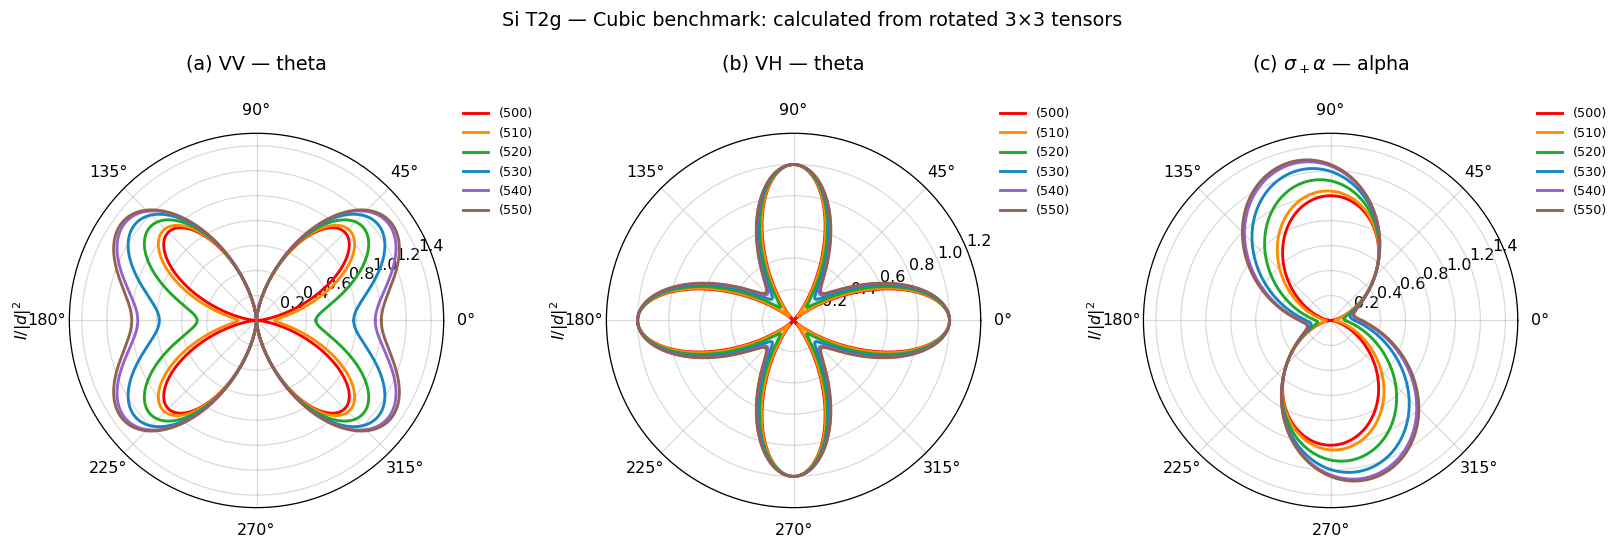

**OriginLab:** download and extract the ZIP, then run plot_in_origin.py inside Origin's Python Console. It creates three native polar graphs and saves an OPJU project locally. The displayed preview was generated by Python.

### Cubic benchmark reference

DOI 10.1002/jrs.70113: the six-surface silicon benchmark uses the Eq. 4 frame, Eq. 11 Jones states and the complete T2g partner sum. VV and VH scan theta; sigma+alpha scans alpha with theta=45 degrees and beta=beta'=90 degrees. All curves use one shared coefficient scale. The companion guides provide the derivation and independent checks.

**Calculated silicon benchmark:** VV, VH and circular-angle scans on six surfaces. Python preview; native OriginLab plotting is available through the application export.

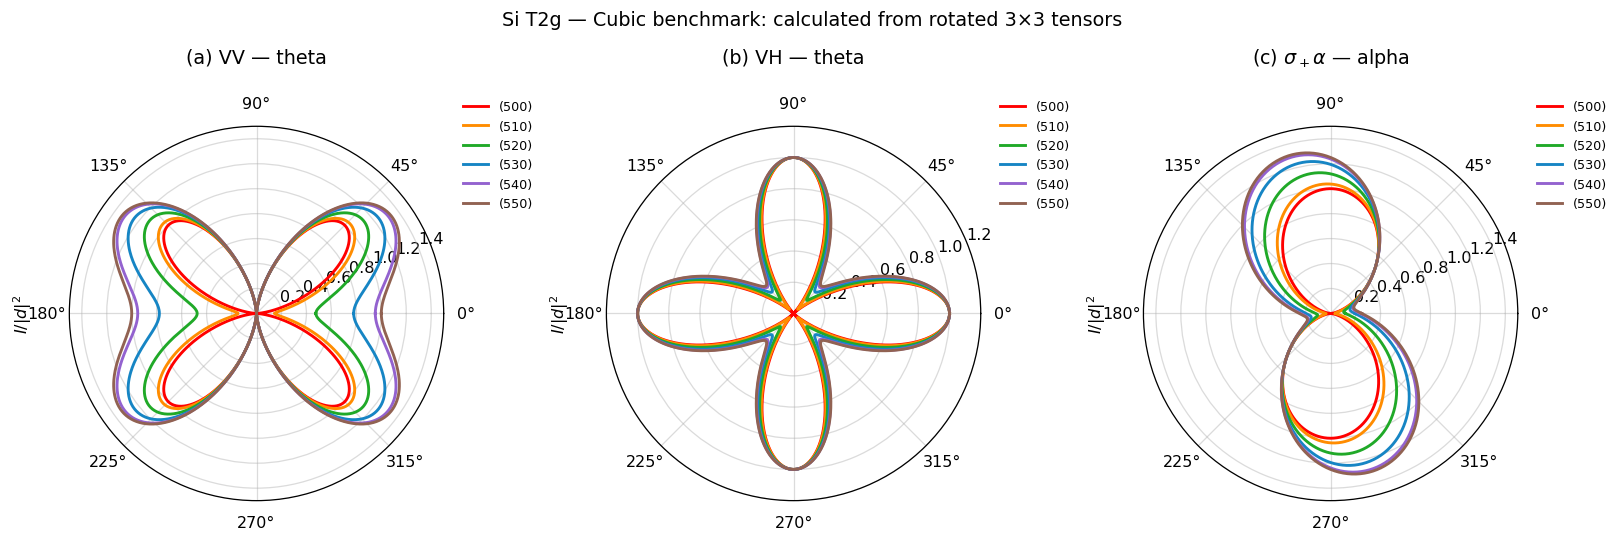

In [22]:
def start_application():
    """Open one app with a coherent full-tensor crystal example and source regressions."""
    if ui["wired"]:
        display(app_view)
        return
    ordinary_controls = [
        case_label,
        input_note,
        *hkl_fields,
        *uvw_fields,
        auto_x,
        normal_pick,
        psi,
        *lattice_fields,
        custom_tensor,
        *direct_widgets.values(),
        *source_widgets.values(),
        circular_N,
        circular_ell,
        circular_mph,
        circular_dm,
        circular_scope,
        normalize,
        show_steps,
        show_components,
        show_geometry,
        points,
    ]
    for widget in ordinary_controls:
        widget.observe(invalidate, names="value")
    for widget, callback in [
        (material_pick, on_material),
        (group_pick, on_group),
        (surface_pick, on_surface),
        (mode_pick, update_visible_modes),
        (optics_pick, on_optics),
        (method_pick, on_method),
        (qwp_model, on_method),
        (ag_relation, on_coefficient_change),
        (auto_x, auto_changed),
        (compare_normalized, render_comparison),
        (circular_spin, on_optics),
        (linear_theta0, on_optics),
    ]:
        widget.observe(callback, names="value")
    for button, callback in [
        (run_button, on_run),
        (export_button, on_export),
        (compare_add, add_comparison),
        (compare_clear, clear_comparison),
        (benchmark_button, on_benchmark),
        (component_button, use_component),
        (qwp_button, use_qwp),
        (qwp_rotation_button, use_qwp_rotation),
        (circular_button, use_circular),
        (linear_button, use_linear),
        (sigma_button, use_sigma),
        (physical_button, use_physical_start),
        (cubic_button, on_cubic_run),
        (cubic_export, on_cubic_export),
        (cubic_inspect, on_cubic_inspect),
        (validate_button, on_validate),
    ]:
        button.on_click(callback)
    ui["wired"] = True
    display(app_view)
    with sources_out:
        display(Markdown(PAPER_NOTES))
    use_physical_start()
    on_run()
    on_validate()
    cubic_d.observe(invalidate_cubic, names="value")
    cubic_points.observe(invalidate_cubic, names="value")
    on_cubic_run()


# Layout construction is separate from the scientific calculation functions.
orientation_inputs = widgets.VBox(
    [
        surface_pick,
        widgets.HBox(hkl_fields),
        widgets.HTML("The initial X direction is [uvw]; h*u+k*v+l*w must equal zero."),
        widgets.HBox(uvw_fields),
        auto_x,
        normal_pick,
        psi,
        widgets.HTML(
            "<b>Metric:</b> lengths use the same units. Replace illustrative ratios for tilted anisotropic surfaces. Hexagonal presets use γ=120° and three-index (hkl), not four-index (hkil). The REFERENCE negative-normal choice is a coordinate convention, not a measured sample-side assignment."
        ),
        widgets.HBox(lattice_fields[:3]),
        widgets.HBox(lattice_fields[3:]),
    ]
)
orientation_box = widgets.VBox([source_orientation_note, orientation_inputs])
crystal_tensor_box = widgets.VBox(
    [
        material_pick,
        group_pick,
        material_note,
        mode_pick,
        coef_note,
        ag_relation,
        coef_accordion,
        custom_tensor,
        ag_locked,
    ]
)
tensor_box = widgets.VBox([case_label, input_note, source_box, crystal_tensor_box])
optics_box = widgets.VBox(
    [
        optics_note,
        optical_preview,
        sigma_button,
        direct_box,
        paper_controls,
    ]
)
comparison_controls = widgets.VBox(
    [
        widgets.HTML(
            "Save calculated cases to compare materials, surfaces or optical profiles. The five-material example uses each material's starting geometry; it is not one shared physical orientation."
        ),
        widgets.HBox([compare_add, compare_clear]),
        compare_normalized,
        benchmark_button,
    ]
)
settings = widgets.Tab(
    children=[
        tensor_box,
        orientation_box,
        optics_box,
        widgets.VBox([normalize, show_steps, show_components, show_geometry, points]),
        comparison_controls,
        library_out,
    ]
)
for index, title in enumerate(
    [
        "1. Material / tensors",
        "2. Orientation",
        "3. Jones optics",
        "4. Display",
        "5. Comparisons",
        "Tensor library",
    ]
):
    settings.set_title(index, title)
app_view = widgets.VBox(
    [
        widgets.HTML(
            "<h2>ROTATION RAMAN TENSOR CALCULATION</h2><p>Choose a workflow and optical method, enter the crystal inputs, then calculate.</p>"
        ),
        method_pick,
        optics_pick,
        qwp_model,
        method_note,
        physical_button,
        widgets.HBox([qwp_button, component_button]),
        widgets.HBox([circular_button, linear_button]),
        qwp_rotation_button,
        settings,
        widgets.HBox([run_button, export_button, validate_button]),
        status,
        tabs,
    ]
)


start_application()
